## Set up


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import datetime

file_path = "../data/consumption12_filled.xlsx"

office12 = pd.read_excel(file_path)
#office12.drop(columns=['consumption'], inplace=True)
office12.drop(columns= {'consumption','consumption_handled'}, inplace=True)
office12.rename(columns={'consumption_full': 'consumption'}, inplace=True)

office12['timestamp'] = pd.to_datetime(office12['timestamp'])
office12 = office12.set_index('timestamp')

office12

,day_name,month,temperature,consumption
timestamp,,,,
2025-03-13 12:00:00,Thursday,March,21.4,136.25
2025-03-13 13:00:00,Thursday,March,21.8,136.66
2025-03-13 14:00:00,Thursday,March,22.0,137.70
2025-03-13 15:00:00,Thursday,March,22.1,138.37
2025-03-13 16:00:00,Thursday,March,22.2,141.35
...,...,...,...,...
2025-11-15 05:00:00,Saturday,November,19.9,0.00
2025-11-15 06:00:00,Saturday,November,19.8,0.00
2025-11-15 07:00:00,Saturday,November,19.8,0.00


In [ ]:
file_path = "../data/consumption35_filled.xlsx"
office35 = pd.read_excel(file_path)
office35.drop(columns= {'consumption','consumption_handled'}, inplace=True)
office35.rename(columns={'consumption_full': 'consumption'}, inplace=True)

office35['timestamp'] = pd.to_datetime(office35['timestamp'])
office35 = office35.set_index('timestamp')

office35

,day_name,month,temperature,consumption
timestamp,,,,
2024-11-27 11:00:00,Wednesday,November,22.7,0.00
2024-11-27 12:00:00,Wednesday,November,23.2,0.01
2024-11-27 13:00:00,Wednesday,November,23.5,0.00
2024-11-27 14:00:00,Wednesday,November,23.7,0.00
2024-11-27 15:00:00,Wednesday,November,23.6,0.00
...,...,...,...,...
2025-11-15 05:00:00,Saturday,November,19.5,101.73
2025-11-15 06:00:00,Saturday,November,19.5,100.63
2025-11-15 07:00:00,Saturday,November,19.7,98.51


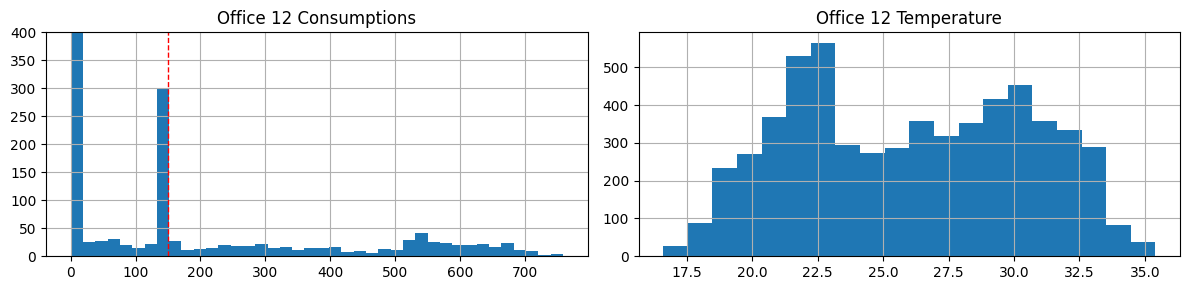

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
office12['consumption'].hist(bins=40, ax=axes[0])
office12['temperature'].hist(bins=20, ax=axes[1])

axes[0].set_title('Office 12 Consumptions')
axes[1].set_title('Office 12 Temperature')
axes[0].set_ylim(0, 400)
axes[0].axvline(x=150, color='r', linestyle='--', linewidth=1, label='Threshold (200 Wh)')

plt.tight_layout()
plt.show()

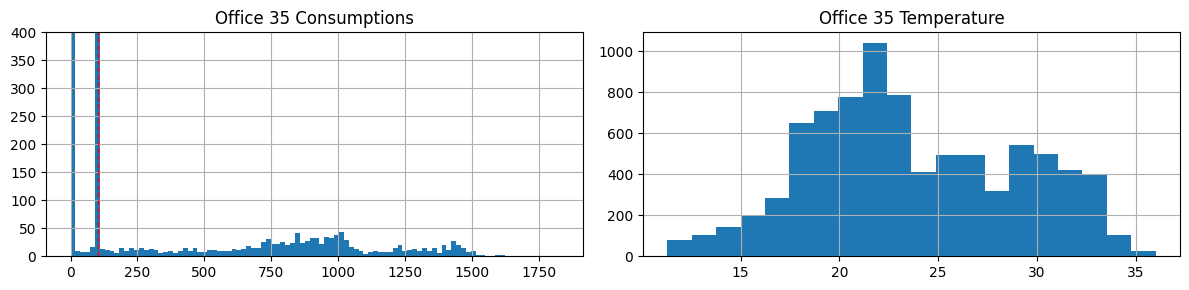

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
office35['consumption'].hist(bins=100, ax=axes[0])
office35['temperature'].hist(bins=20, ax=axes[1])

axes[0].set_title('Office 35 Consumptions')
axes[1].set_title('Office 35 Temperature')
axes[0].set_ylim(0, 400)
axes[0].axvline(x=103, color='r', linestyle='--', linewidth=1, label='Threshold (200 Wh)')

plt.tight_layout()
plt.show()

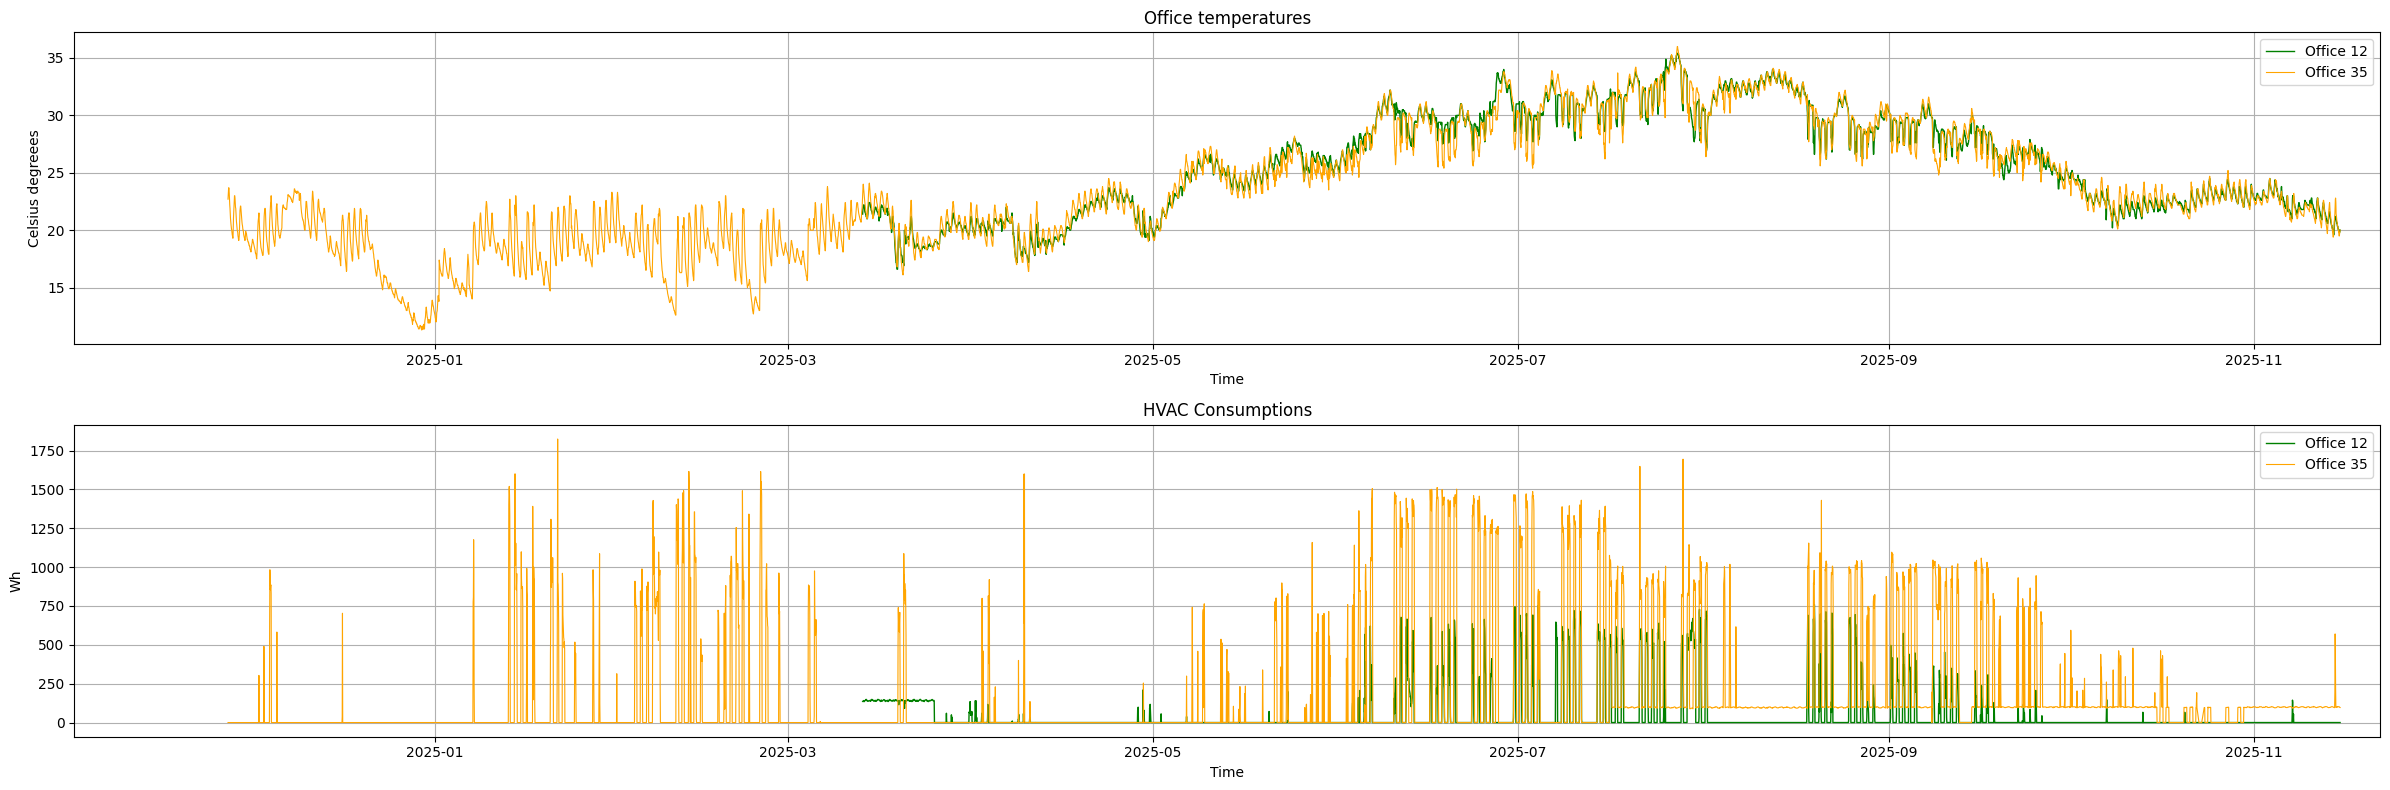

In [ ]:
plt.figure(figsize=(24, 8))

plt.subplot(2, 1, 1)
plt.plot(office12.index, office12['temperature'], color='green', linewidth=1)
plt.plot(office35.index, office35['temperature'], color='orange', linewidth=0.8)
plt.title("Office temperatures")
plt.xlabel("Time")
plt.ylabel("Celsius degreees")
plt.legend(['Office 12', 'Office 35'])
plt.grid(True)
plt.xlim(pd.to_datetime('2024-11-01 19:00:00'), pd.to_datetime('2025-11-22 01:00:00'))

plt.subplot(2, 1, 2)
plt.plot(office12.index, office12['consumption'], color='green', linewidth=1)
plt.plot(office35.index, office35['consumption'], color='orange', linewidth=0.8)
plt.title("HVAC Consumptions")
plt.xlabel("Time")
plt.ylabel("Wh")
plt.legend(['Office 12', 'Office 35'])
plt.grid(True)
plt.xlim(pd.to_datetime('2024-11-01 19:00:00'), pd.to_datetime('2025-11-22 01:00:00'))

plt.tight_layout()
plt.show()

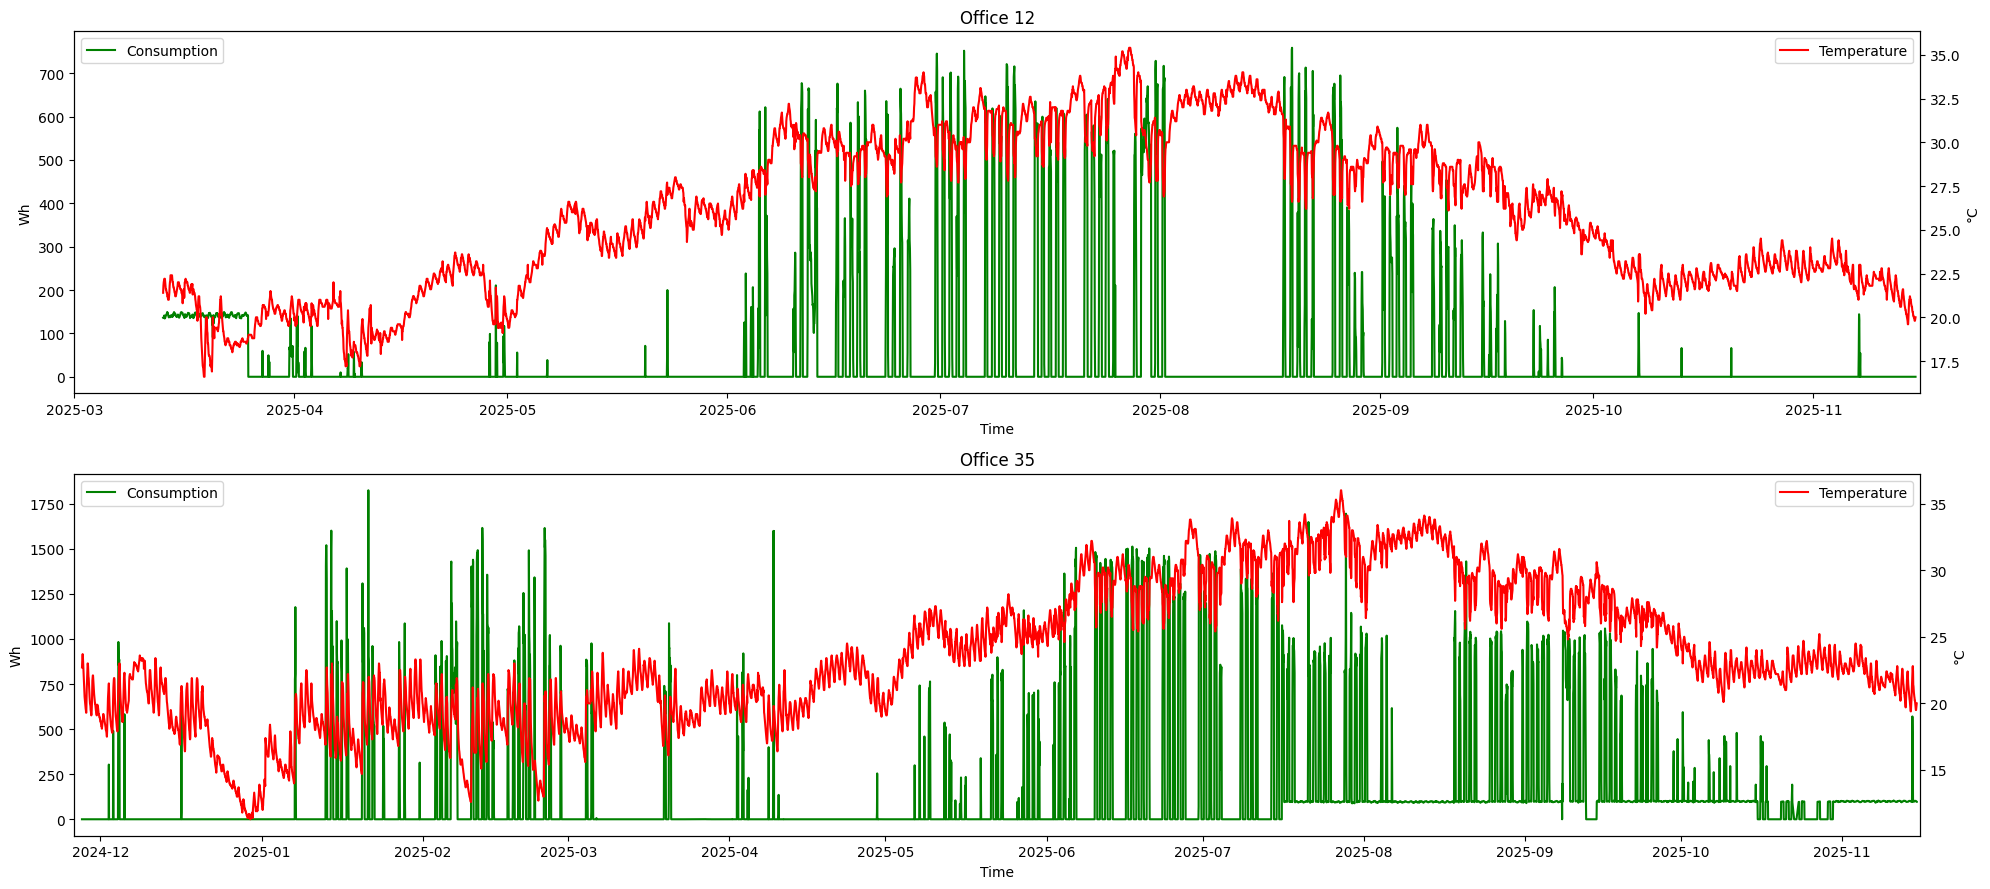

In [ ]:
plt.figure(figsize=(20, 9))

plt.subplot(2, 1, 1)
ax1 = plt.gca()
ax2 = ax1.twinx()
ax1.plot(office12.index, office12['consumption'], 'g-', label='Consumption')
ax2.plot(office12.index, office12['temperature'], 'r-', label='Temperature')
ax1.set_title("Office 12")
ax1.set_xlabel("Time")
ax1.set_ylabel("Wh")
ax2.set_ylabel("°C")
ax1.set_xlim(pd.to_datetime('2025-03-01 00:00:00'),pd.to_datetime('2025-11-16 00:00:00'))
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

plt.subplot(2, 1, 2)
ax1 = plt.gca()
ax2 = ax1.twinx()
ax1.plot(office35.index, office35['consumption'], 'g-', label='Consumption')
ax2.plot(office35.index, office35['temperature'], 'r-', label='Temperature')
ax1.set_title("Office 35")
ax1.set_xlabel("Time")
ax1.set_ylabel("Wh")
ax2.set_ylabel("°C")
ax1.set_xlim(pd.to_datetime('2024-11-26 00:00:00'),pd.to_datetime('2025-11-16 00:00:00'))
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [ ]:
hvac_consumptions_dataframe = pd.concat([
    office12['consumption'].rename('o12_consumption'),
    office35['consumption'].rename('o35_consumption'),
    
], axis=1)

hvac_consumptions_dataframe

C:\Users\yiann\AppData\Local\Temp\ipykernel_27700\3759407458.py:1: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  hvac_consumptions_dataframe = pd.concat([


,o12_consumption,o35_consumption
timestamp,,
2024-11-27 11:00:00,NaN,0.00
2024-11-27 12:00:00,NaN,0.01
2024-11-27 13:00:00,NaN,0.00
2024-11-27 14:00:00,NaN,0.00
2024-11-27 15:00:00,NaN,0.00
...,...,...
2025-11-15 05:00:00,0.0,101.73
2025-11-15 06:00:00,0.0,100.63
2025-11-15 07:00:00,0.0,98.51


## Flagging με naive thresholds

=== OFF reference (00:00-06:00) percentiles -- pre-fill ===
              n     Q90     Q95   Q97.5     Q99
office                                         
Office 12  1341    0.00  144.61  146.92  148.91
Office 35  1938  101.18  101.74  102.11  102.65



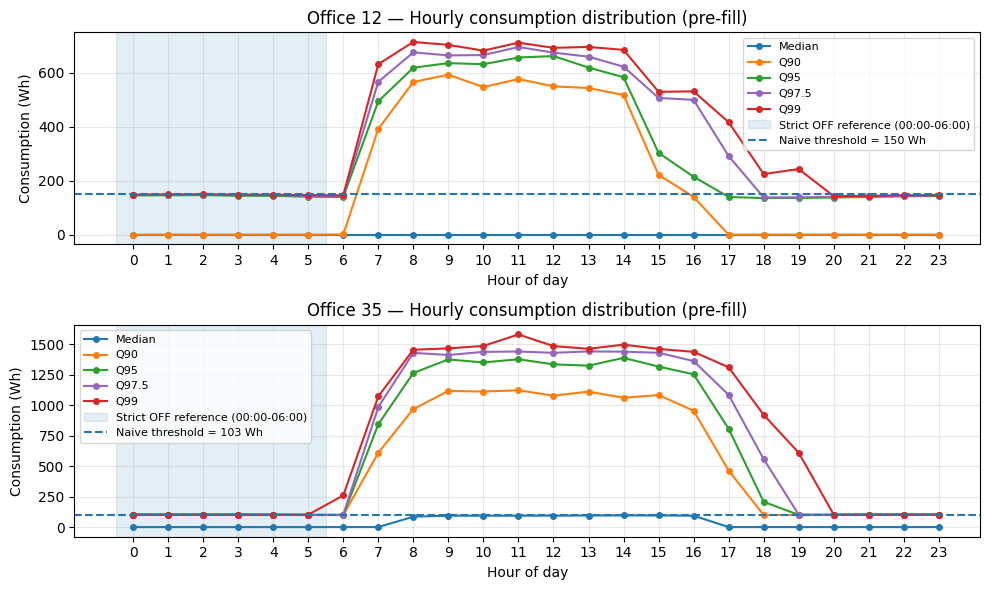

In [ ]:
OFF_HOURS = 6
DATA_DIR  = "../data"
_FILES    = {"o12": "consumption12_filled.xlsx", "o35": "consumption35_filled.xlsx"}
# reference threshold drawn on the plot only -- matches the current cell below, not set here
_REF_THR  = {"o12": 150, "o35": 103}


def load_consumption(column):
    """{'o12': Series, 'o35': Series} for the given column of the *_filled.xlsx files."""
    out = {}
    for room, fn in _FILES.items():
        col = pd.read_excel(fr"{DATA_DIR}/{fn}", index_col=0)[column]
        col.index = pd.to_datetime(col.index)
        out[room] = col
    return out


def off_reference_analysis(cons_by_room, data_label, off_hours=OFF_HOURS):
    #percentile table of the OFF-window distribution
    rows = []
    for room, ser in cons_by_room.items():
        w = ser[ser.index.hour < off_hours].dropna()
        rows.append({"office": f"Office {room[1:]}", "n": int(len(w)),
                     "Q90": w.quantile(.90), "Q95": w.quantile(.95),
                     "Q97.5": w.quantile(.975), "Q99": w.quantile(.99)})
    table = pd.DataFrame(rows).set_index("office").round(2)
    print(f"=== OFF reference (00:00-{off_hours:02d}:00) percentiles -- {data_label} ===")
    print(table)
    print()

    # per-hour-of-day distribution plot
    fig, axes = plt.subplots(len(cons_by_room), 1, figsize=(10, 6))
    for ax, (room, ser) in zip(np.atleast_1d(axes), cons_by_room.items()):
        ser = ser.dropna()
        g = ser.groupby(ser.index.hour)
        hh = list(range(24))
        med = [g.get_group(h).median()      if h in g.groups else np.nan for h in hh]
        q90 = [g.get_group(h).quantile(.90) if h in g.groups else np.nan for h in hh]
        q95 = [g.get_group(h).quantile(.95) if h in g.groups else np.nan for h in hh]
        q99 = [g.get_group(h).quantile(.99) if h in g.groups else np.nan for h in hh]
        q97_5 = [g.get_group(h).quantile(.975) if h in g.groups else np.nan for h in hh]
        ax.plot(hh, med, "-o", ms=4, label="Median")
        ax.plot(hh, q90, "-o", ms=4, color="tab:orange", label="Q90")
        ax.plot(hh, q95, "-o", ms=4, color="tab:green", label="Q95")
        ax.plot(hh, q97_5, "-o", ms=4, color="tab:purple", label="Q97.5")
        ax.plot(hh, q99, "-o", ms=4, color="tab:red", label="Q99")
        ax.axvspan(-0.5, off_hours - 0.5, color="tab:blue", alpha=0.12,
                   label=f"Strict OFF reference (00:00-{off_hours:02d}:00)")
        ax.axhline(_REF_THR[room], ls="--", color="tab:blue",
                   label=f"Naive threshold = {_REF_THR[room]} Wh")
        ax.set_title(f"Office {room[1:]} \u2014 Hourly consumption distribution ({data_label})")
        ax.set_xlabel("Hour of day")
        ax.set_ylabel("Consumption (Wh)")
        ax.set_xticks(hh)
        ax.grid(True, alpha=.3)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
    return table


# raw: actual meter readings only, before gap-filling
off_ref_raw = off_reference_analysis(load_consumption("consumption"), "pre-fill")

=== OFF reference (00:00-06:00) percentiles -- filled (post-fill) ===
              n     Q90     Q95   Q97.5    Q99
office                                        
Office 12  1482    0.00  142.82  146.72  148.6
Office 35  2118  101.09  101.68  102.09  102.6



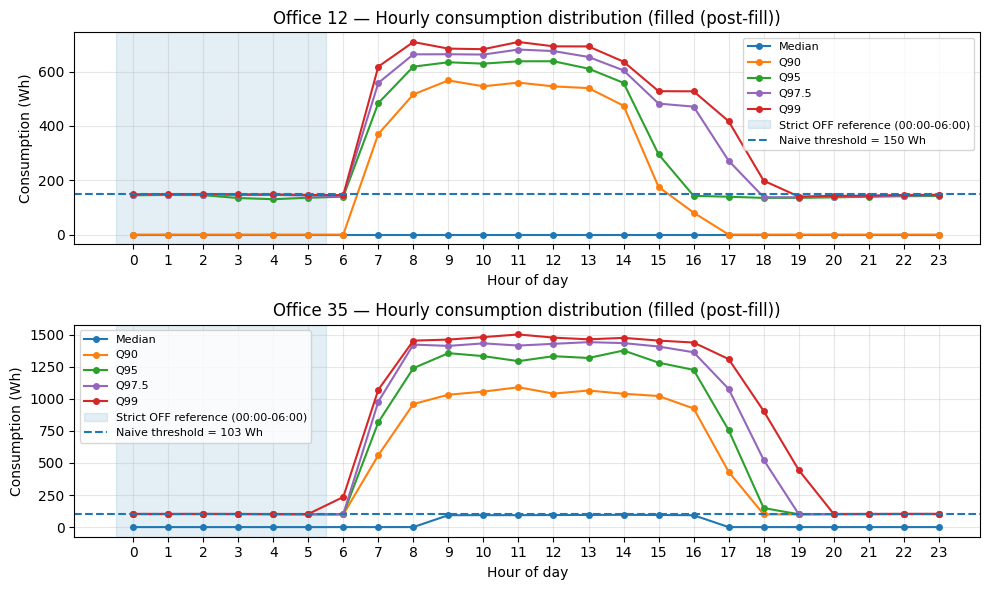

In [ ]:
# Same OFF-reference analysis on the FILLED series (consumption_full, all NaNs filled).
off_ref_filled = off_reference_analysis(load_consumption("consumption_full"), "filled (post-fill)")

In [ ]:
rooms = ['o12', 'o35']
percentage = {'o12': 0.92,'o35': 0.87}

naive_threshold = {}
df_points_where_hvac_is_on = {}

for room in rooms:
    sorted_timeseries = (hvac_consumptions_dataframe[f'{room}_consumption'].dropna().sort_values())
    naive_threshold[room] = sorted_timeseries.iloc[int(percentage[room] * len(sorted_timeseries))]
    df_points_where_hvac_is_on[room] = (hvac_consumptions_dataframe[f'{room}_consumption'].where(hvac_consumptions_dataframe[f'{room}_consumption'] >= naive_threshold[room]))

percentile_derived_threshold = dict(naive_threshold)
print (percentile_derived_threshold)

{'o12': np.float64(208.6499999999069), 'o35': np.float64(294.25)}


In [ ]:
naive_threshold = {'o12': 150,'o35': 103}

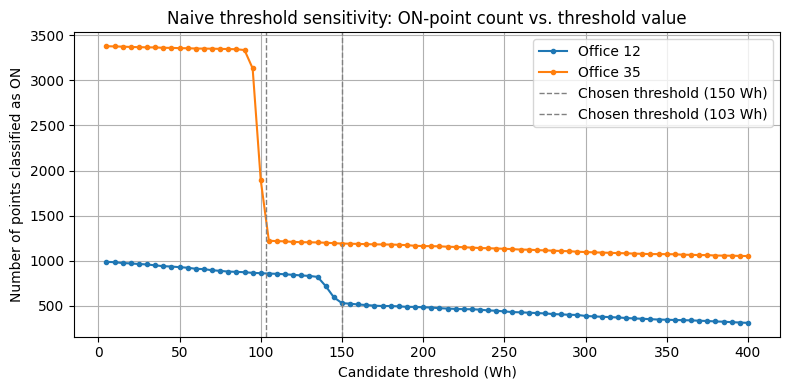

In [ ]:
# Sensitivity sweep (diagnostic only)
threshold_range = np.arange(5, 401, 5)

on_counts_by_threshold = {room: [] for room in rooms}
for room in rooms:
    consumption = hvac_consumptions_dataframe[f'{room}_consumption'].dropna()
    for t in threshold_range:
        on_counts_by_threshold[room].append(int((consumption > t).sum()))

plt.figure(figsize=(8, 4))
for room in rooms:
    plt.plot(threshold_range, on_counts_by_threshold[room], marker='o', markersize=3, label=f'Office {room[1]}{room[2]}')

chosen_threshold = naive_threshold[rooms[0]]
#plt.axvline(x=chosen_threshold, color='grey', linestyle='--', linewidth=1, label=f'Chosen threshold ({chosen_threshold} Wh)')
plt.axvline(x=naive_threshold[rooms[0]], color='grey', linestyle='--', linewidth=1, label=f'Chosen threshold ({naive_threshold[rooms[0]]} Wh)')
plt.axvline(x=naive_threshold[rooms[1]], color='grey', linestyle='--', linewidth=1, label=f'Chosen threshold ({naive_threshold[rooms[1]]} Wh)')

plt.xlabel('Candidate threshold (Wh)')
plt.ylabel('Number of points classified as ON')
plt.title('Naive threshold sensitivity: ON-point count vs. threshold value')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

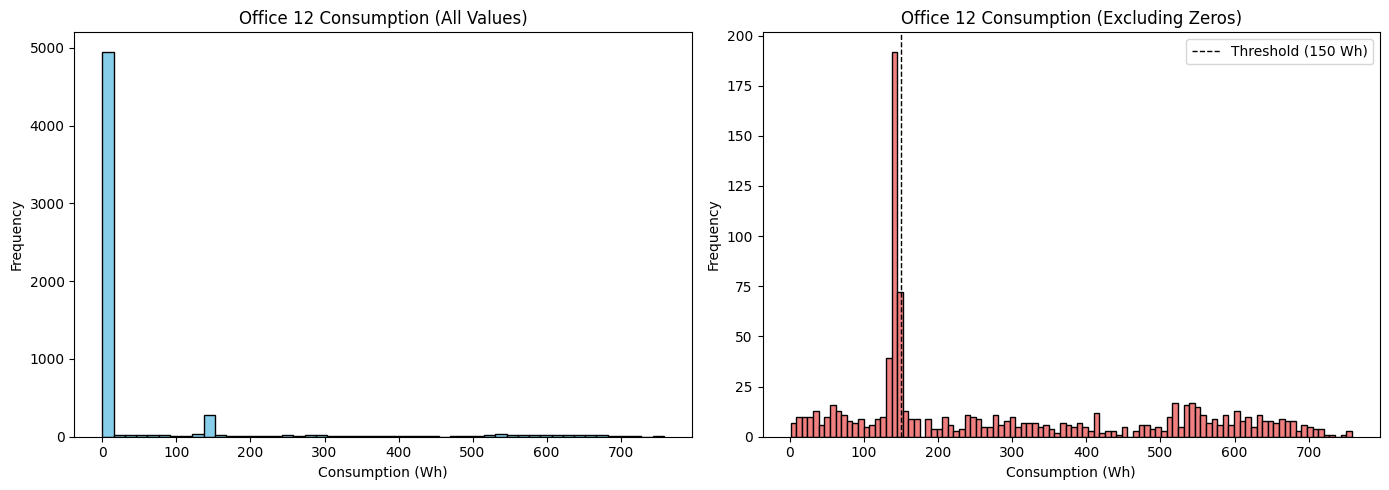

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram 1: All values
axes[0].hist(hvac_consumptions_dataframe['o12_consumption'].dropna(), bins=50, color='skyblue', edgecolor='black')
axes[0].set_title('Office 12 Consumption (All Values)')
axes[0].set_xlabel('Consumption (Wh)')
axes[0].set_ylabel('Frequency')

# Histogram 2: Excluding zero values
non_zero_consumption = hvac_consumptions_dataframe['o12_consumption'][hvac_consumptions_dataframe['o12_consumption'] > 0].dropna()
axes[1].hist(non_zero_consumption, bins=100, color='lightcoral', edgecolor='black')
axes[1].axvline(x=naive_threshold['o12'], color='black', linewidth=1, linestyle='--', label='Threshold (150 Wh)')
axes[1].set_title('Office 12 Consumption (Excluding Zeros)')
axes[1].set_xlabel('Consumption (Wh)')
axes[1].set_ylabel('Frequency')
axes[1].legend()

plt.tight_layout()
plt.show()

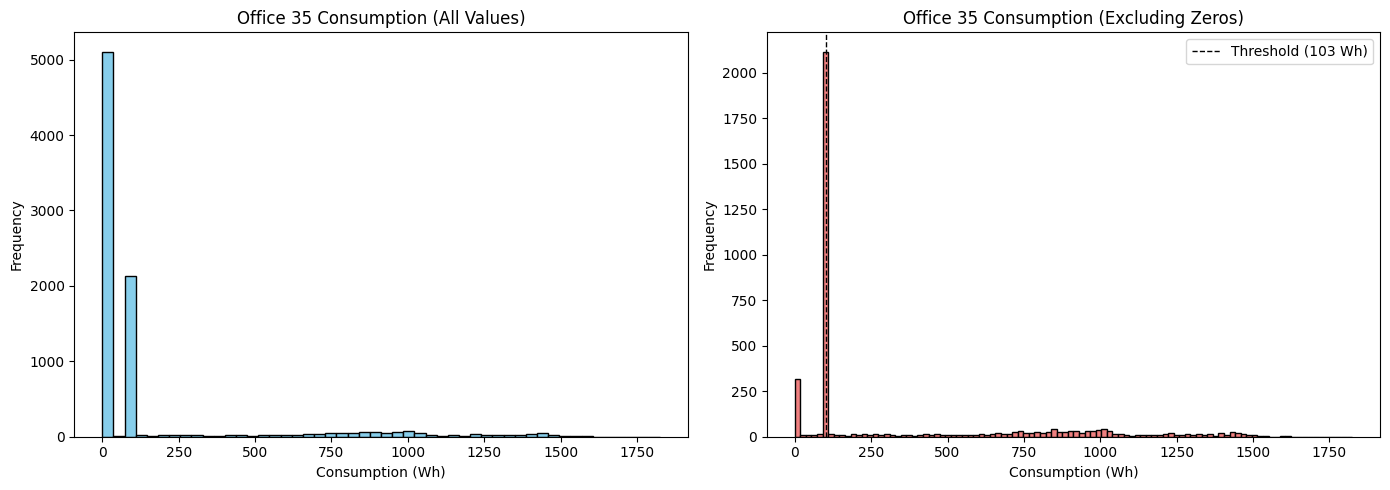

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram 1: All values
axes[0].hist(hvac_consumptions_dataframe['o35_consumption'].dropna(), bins=50, color='skyblue', edgecolor='black')
axes[0].set_title('Office 35 Consumption (All Values)')
axes[0].set_xlabel('Consumption (Wh)')
axes[0].set_ylabel('Frequency')

# Histogram 2: Excluding zero values
non_zero_consumption = hvac_consumptions_dataframe['o35_consumption'][hvac_consumptions_dataframe['o35_consumption'] > 0].dropna()
axes[1].hist(non_zero_consumption, bins=100, color='lightcoral', edgecolor='black')
axes[1].axvline(x=naive_threshold['o35'], color='black', linewidth=1, linestyle='--', label='Threshold (103 Wh)')
axes[1].set_title('Office 35 Consumption (Excluding Zeros)')
axes[1].set_xlabel('Consumption (Wh)')
axes[1].set_ylabel('Frequency')
axes[1].legend()

plt.tight_layout()
plt.show()

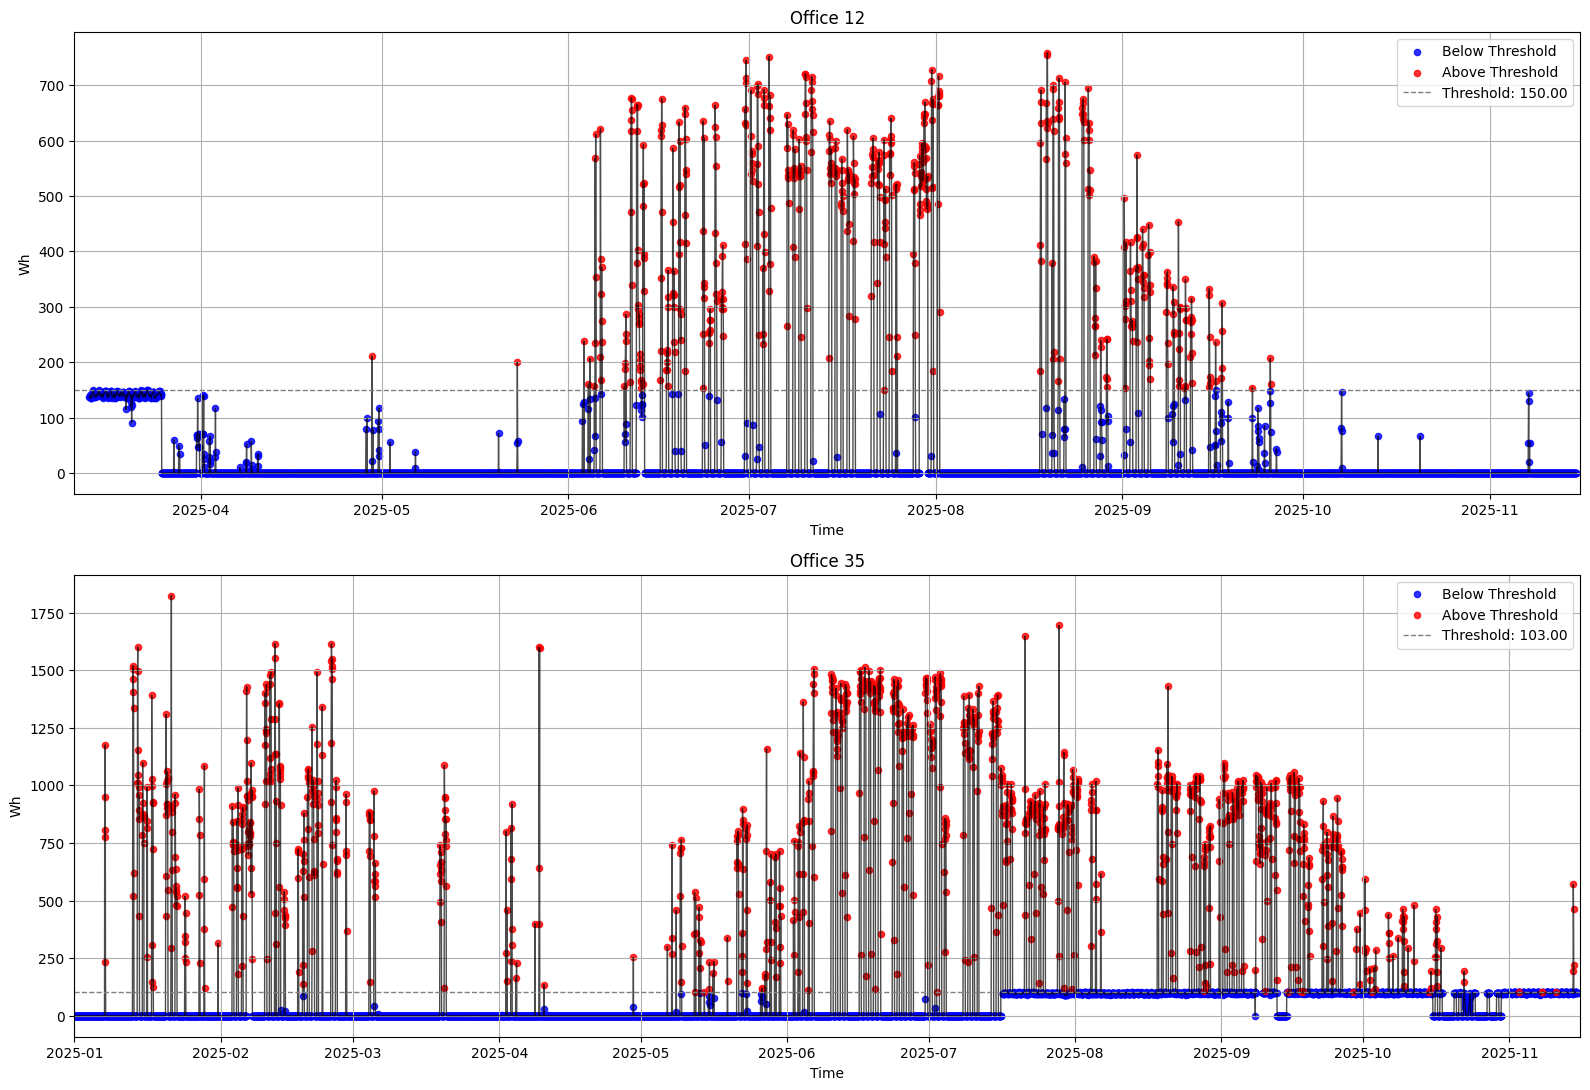

In [ ]:
on_off_sequence_naive = {}
below_threshold_masks = {}
above_threshold_masks = {}
start_date = {'o12': pd.to_datetime('2025-03-11 00:00:00'),'o35': pd.to_datetime('2025-01-01 00:00:00')}

plt.figure(figsize=(16, 16))

for i in range (0,2):
  threshold = naive_threshold[rooms[i]]

  x = hvac_consumptions_dataframe.index
  y = hvac_consumptions_dataframe[f'{rooms[i]}_consumption']

  # Masks
  below_threshold = y <= threshold
  above_threshold = y > threshold
  below_threshold_masks[rooms[i]] = below_threshold
  above_threshold_masks[rooms[i]] = above_threshold

  on_off_sequence_naive[rooms[i]] = pd.Series(
    np.where(y.isna(), np.nan, above_threshold.astype(int)),
    index=y.index,
    dtype='Int64'
)

  plt.subplot(3, 1, i+1)
  plt.plot(x,y,color='black',linewidth=1,alpha=0.7)

  plt.scatter(x[below_threshold],y[below_threshold],color='blue',s=20,alpha=0.8,label='Below Threshold')
  plt.scatter(x[above_threshold],y[above_threshold],color='red',s=20,alpha=0.8,label='Above Threshold')

  plt.axhline(y=threshold,color='grey',linestyle='--',linewidth=1,label=f'Threshold: {threshold:.2f}')

  plt.title(f"Office {rooms[i][1]}{rooms[i][2]}")
  plt.xlabel("Time")
  plt.ylabel("Wh")
  plt.grid(True)
  plt.xlim(start_date[rooms[i]], pd.to_datetime('2025-11-15 23:00:00'))
  plt.legend()


plt.tight_layout()
plt.show()

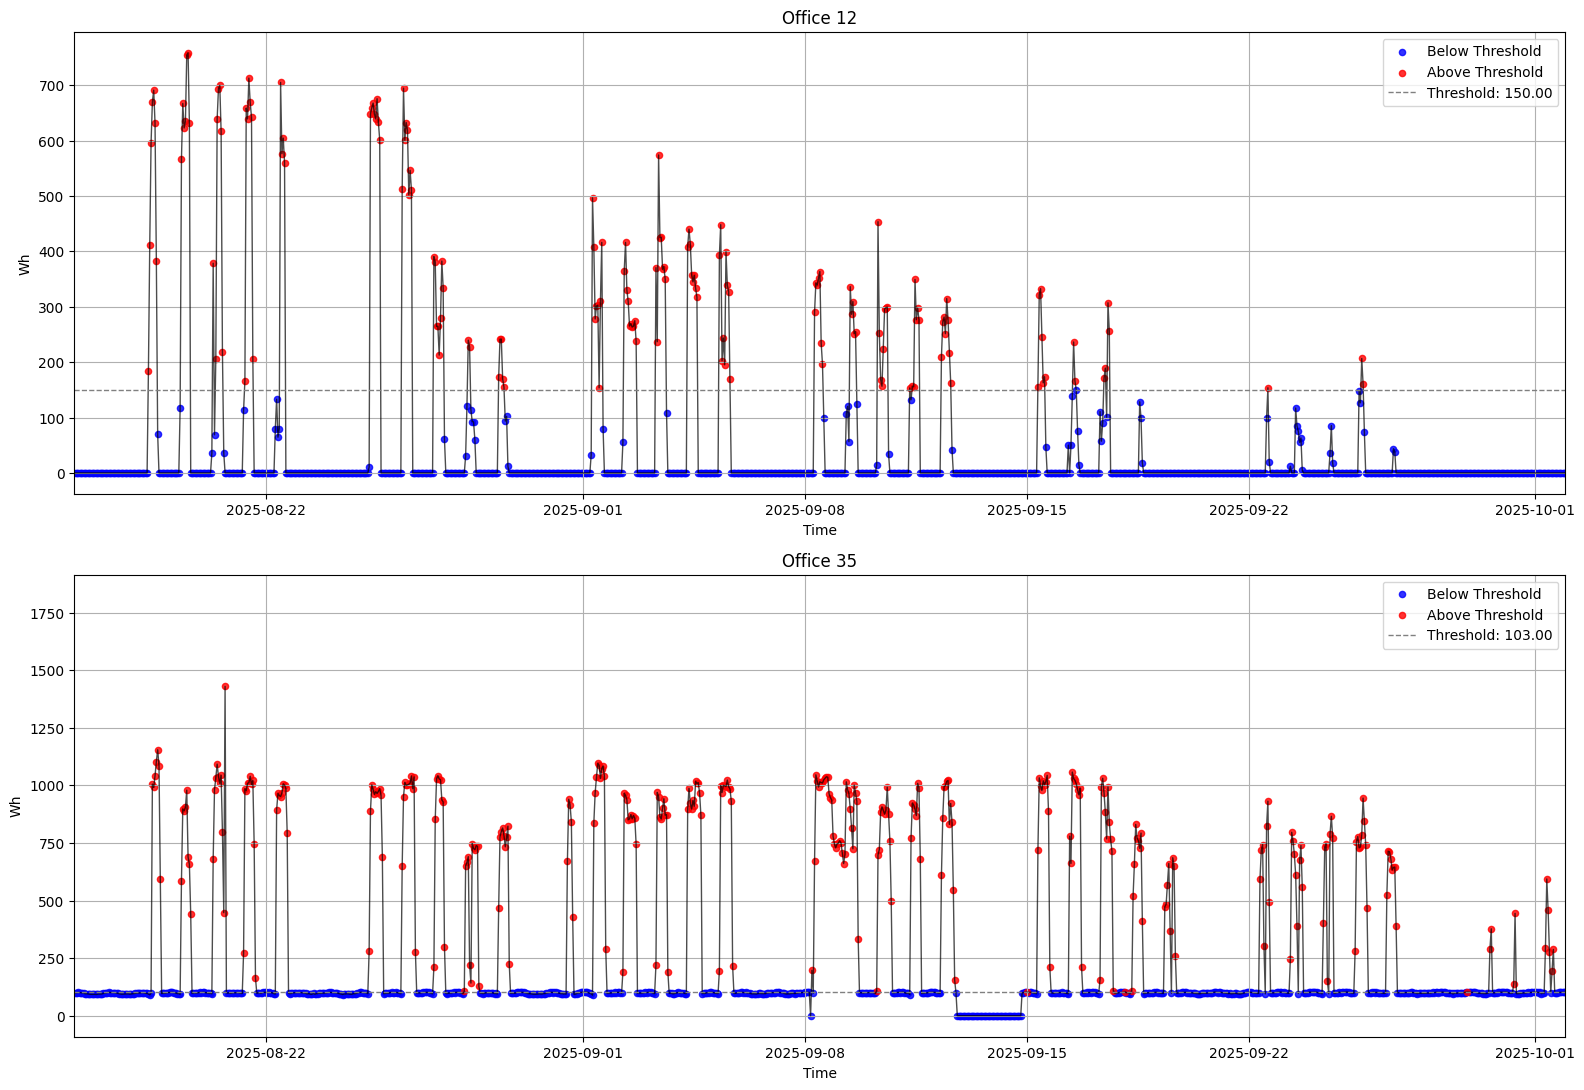

In [ ]:
on_off_sequence_naive = {}
below_threshold_masks = {}
above_threshold_masks = {}
start_date = {'o12': pd.to_datetime('2025-03-11 00:00:00'),'o35': pd.to_datetime('2025-01-01 00:00:00')}

plt.figure(figsize=(16, 16))

for i in range (0,2):
  threshold = naive_threshold[rooms[i]]

  x = hvac_consumptions_dataframe.index
  y = hvac_consumptions_dataframe[f'{rooms[i]}_consumption']

  # Masks
  below_threshold = y <= threshold
  above_threshold = y > threshold
  below_threshold_masks[rooms[i]] = below_threshold
  above_threshold_masks[rooms[i]] = above_threshold

  on_off_sequence_naive[rooms[i]] = pd.Series(
    np.where(y.isna(), np.nan, above_threshold.astype(int)),
    index=y.index,
    dtype='Int64'
)

  plt.subplot(3, 1, i+1)
  plt.plot(x,y,color='black',linewidth=1,alpha=0.7)

  plt.scatter(x[below_threshold],y[below_threshold],color='blue',s=20,alpha=0.8,label='Below Threshold')
  plt.scatter(x[above_threshold],y[above_threshold],color='red',s=20,alpha=0.8,label='Above Threshold')

  plt.axhline(y=threshold,color='grey',linestyle='--',linewidth=1,label=f'Threshold: {threshold:.2f}')

  plt.title(f"Office {rooms[i][1]}{rooms[i][2]}")
  plt.xlabel("Time")
  plt.ylabel("Wh")
  plt.grid(True)
  plt.xlim(pd.to_datetime('2025-08-15 23:00:00'), pd.to_datetime('2025-10-01 23:00:00'))
  plt.legend()


plt.tight_layout()
plt.show()

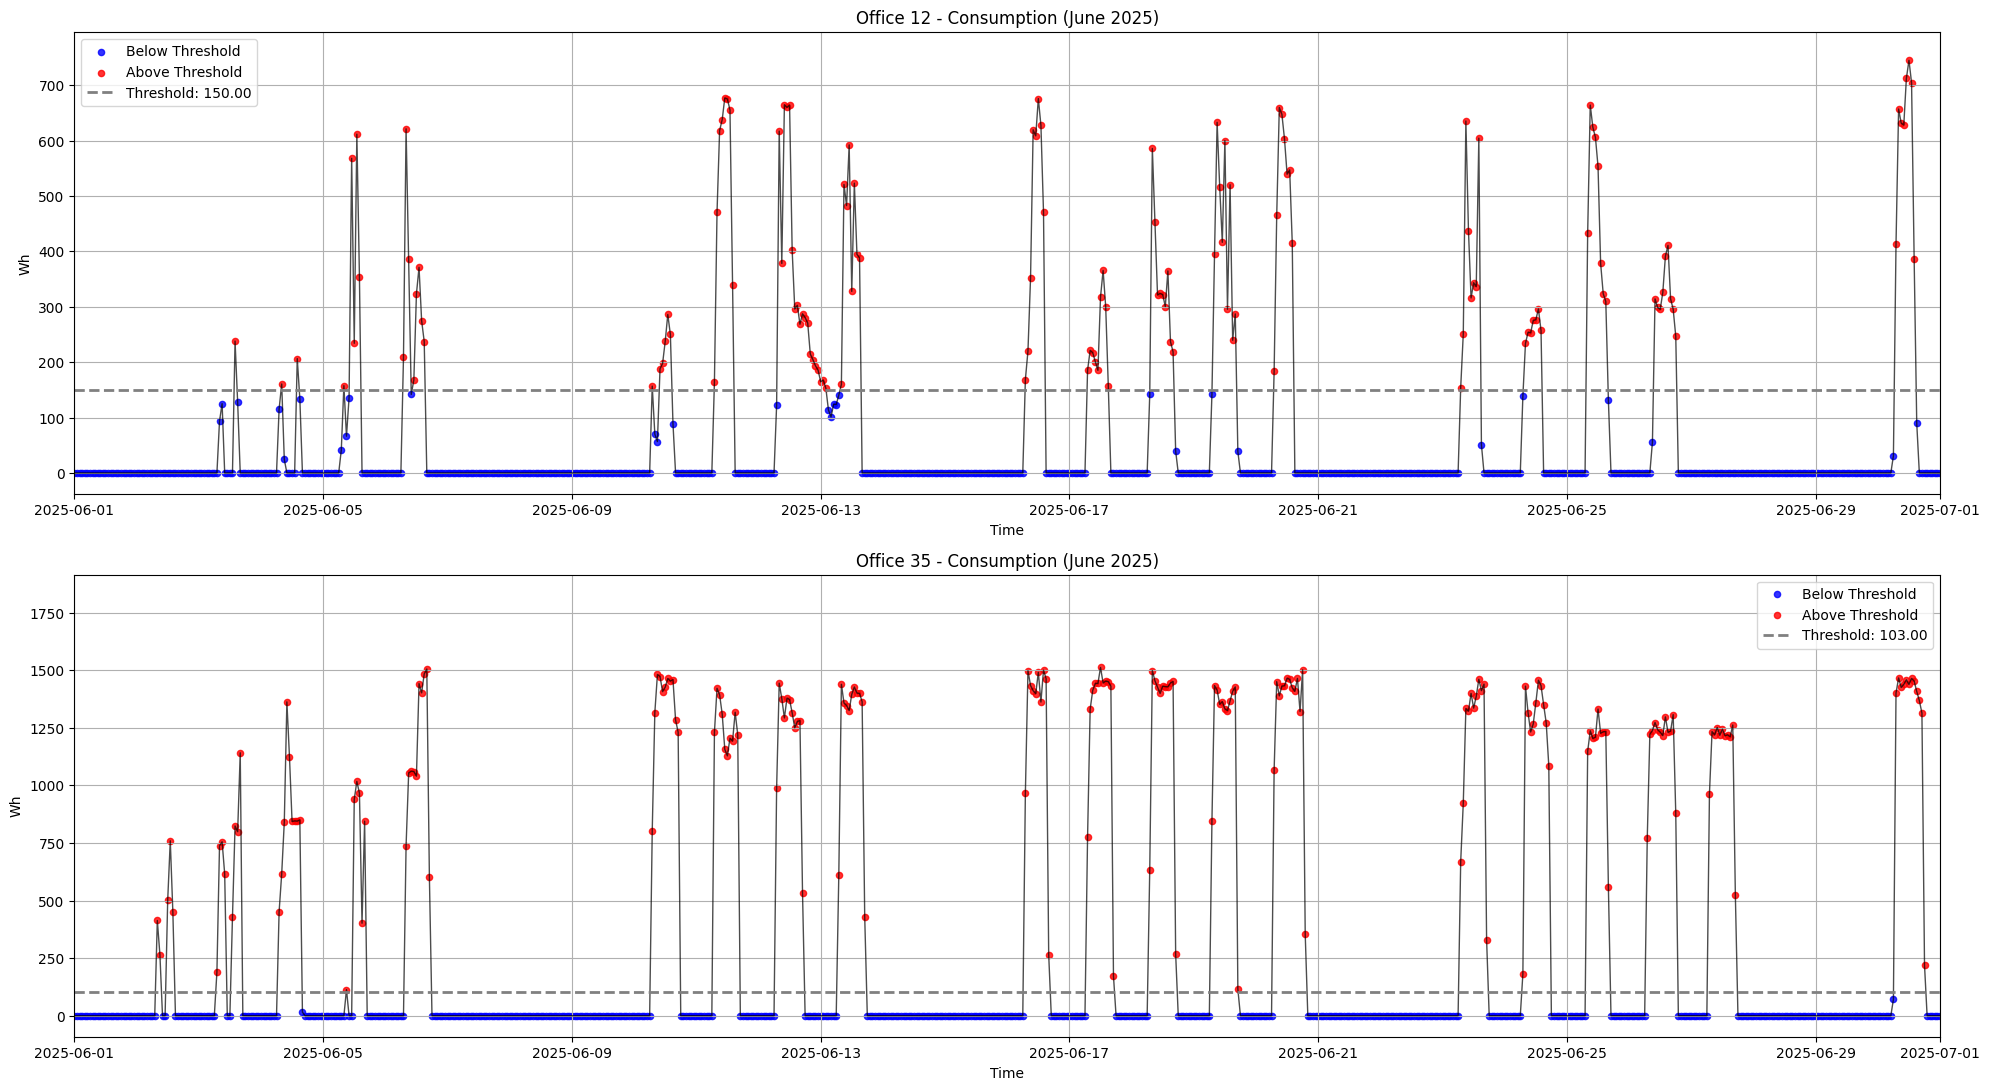

In [ ]:
plt.figure(figsize=(20, 16))

for i in range (0,2):
  threshold = naive_threshold[rooms[i]]

  x = hvac_consumptions_dataframe.index
  y = hvac_consumptions_dataframe[f'{rooms[i]}_consumption']
  below_threshold = below_threshold_masks[rooms[i]]
  above_threshold = above_threshold_masks[rooms[i]]

  plt.subplot(3, 1, i+1)
  plt.plot(x,y,color='black',linewidth=1,alpha=0.7)

  plt.scatter(x[below_threshold],y[below_threshold],color='blue',s=20,alpha=0.8,label='Below Threshold')
  plt.scatter(x[above_threshold],y[above_threshold],color='red',s=20,alpha=0.8,label='Above Threshold')

  plt.axhline(y=threshold,color='grey',linestyle='--',linewidth=2,label=f'Threshold: {threshold:.2f}')

  plt.title(f"Office {rooms[i][1]}{rooms[i][2]} - Consumption (June 2025)")
  plt.xlabel("Time")
  plt.ylabel("Wh")
  plt.grid(True)
  plt.xlim(pd.to_datetime('2025-06-01 00:00:00'), pd.to_datetime('2025-07-01 00:00:00'))
  plt.legend()


plt.tight_layout()
plt.show()

In [ ]:
rooms = ['o12', 'o35']
transitions = {}
for room, series in on_off_sequence_naive.items():
    transitions[room] = series.diff()

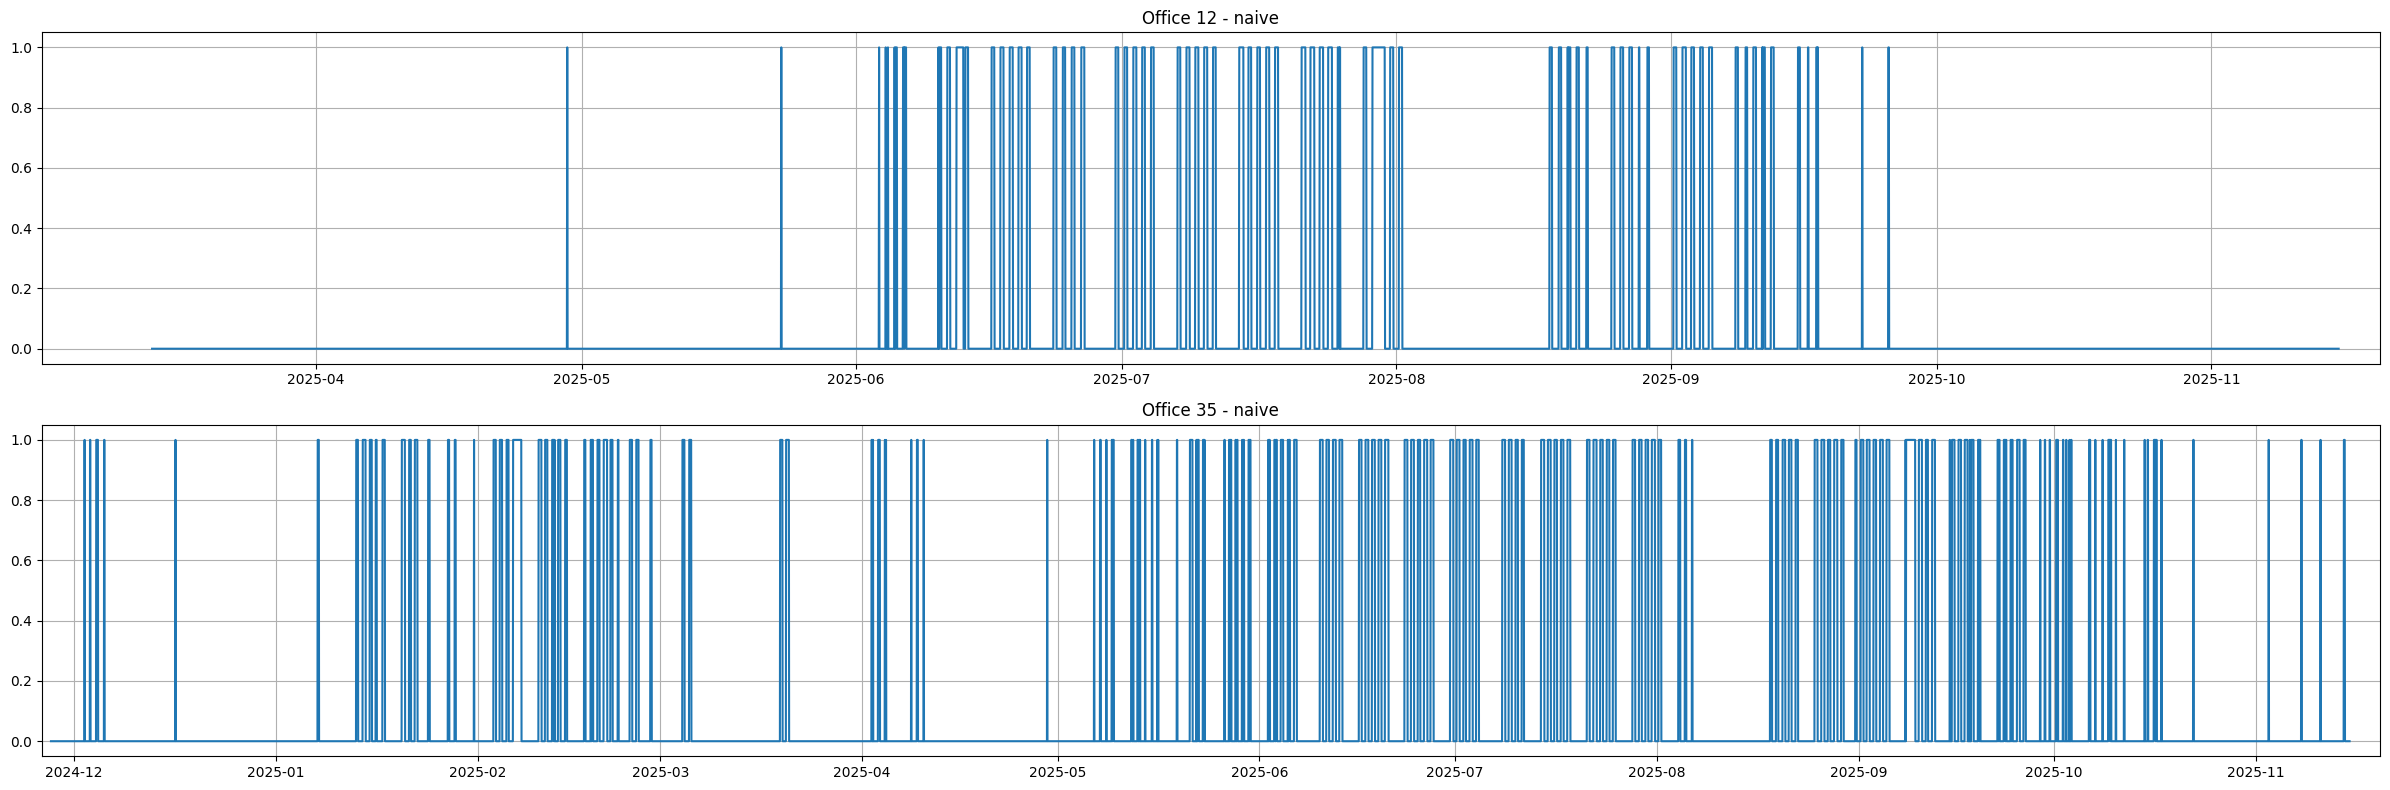

In [ ]:
plt.figure(figsize=(24, 8))

plt.subplot(2,1,1)
plt.plot(on_off_sequence_naive['o12'])
plt.grid(True)
plt.xlim(pd.to_datetime('2025-03-01 01:00:00'), pd.to_datetime('2025-11-20 01:00:00'))
plt.title('Office 12 - naive')

plt.subplot(2,1,2)
plt.plot(on_off_sequence_naive['o35'])
plt.grid(True)
plt.xlim(pd.to_datetime('2024-11-26 01:00:00'), pd.to_datetime('2025-11-20 01:00:00'))
plt.title('Office 35 - naive')

plt.tight_layout()
plt.show()

### Στατιστικά - Naive Threshold

In [ ]:
print(f"Series for Office 12 has: {hvac_consumptions_dataframe['o12_consumption'].isna().sum()} NaN points and {len(office12)} valid points ")
print(f"Series for Office 35 has: {hvac_consumptions_dataframe['o35_consumption'].isna().sum()} NaN points and {len(office35)} valid points ")
print()

print("Percentile-derived thresholds (before overriding to the fixed 150 Wh):", percentile_derived_threshold)
print("Thresholds actually used:", naive_threshold)
print()

for room, series in on_off_sequence_naive.items():
    
    first_valid = hvac_consumptions_dataframe[f'{room}_consumption'].first_valid_index()
    series_valid = series.loc[first_valid:]
    y = hvac_consumptions_dataframe[f'{room}_consumption'].reindex(series_valid.index)
    on_mask = (series_valid == 1).fillna(False)
    off_mask = (series_valid == 0).fillna(False)
    total = len(series_valid)
    on_count = int(on_mask.sum())
    off_count = int(off_mask.sum())

    print(f"Office {room[1]+room[2]}:")
    print(f"  Data available from: {first_valid}")
    print(f"  Total points: {total}")
    print(f"  ON points: {on_count}, OFF points: {off_count}")
    print(f"  ON percentage: {on_count/(on_count+off_count)*100:.2f}%")
    print(f"  Mean consumption (ON): {y[on_mask].mean():.3f} Wh,  Variance (ON): {y[on_mask].var():.3f}")
    print(f"  Mean consumption (OFF): {y[off_mask].mean():.3f} Wh,  Variance (OFF): {y[off_mask].var():.3f}")
    print(f"  Mean consumption (all points): {y.mean():.3f} Wh,  Variance (all points): {y.var():.3f}")
    print(f"  The HVAC flips {transitions[room].value_counts().get(1,0)} times from ON to OFF and another {transitions[room].value_counts().get(-1,0)} times from OFF to ON")
    print()

Series for Office 12 has: 2545 NaN points and 5926 valid points 
Series for Office 35 has: 0 NaN points and 8471 valid points 

Percentile-derived thresholds (before overriding to the fixed 150 Wh): {'o12': np.float64(208.6499999999069), 'o35': np.float64(294.25)}
Thresholds actually used: {'o12': 150, 'o35': 103}

Office 12:
  Data available from: 2025-03-13 12:00:00
  Total points: 5926
  ON points: 529, OFF points: 5397
  ON percentage: 8.93%
  Mean consumption (ON): 447.449 Wh,  Variance (ON): 28519.954
  Mean consumption (OFF): 9.763 Wh,  Variance (OFF): 1177.434
  Mean consumption (all points): 48.834 Wh,  Variance (all points): 19190.785
  The HVAC flips 76 times from ON to OFF and another 76 times from OFF to ON

Office 35:
  Data available from: 2024-11-27 11:00:00
  Total points: 8471
  ON points: 1233, OFF points: 7238
  ON percentage: 14.56%
  Mean consumption (ON): 848.624 Wh,  Variance (ON): 136945.405
  Mean consumption (OFF): 28.879 Wh,  Variance (OFF): 1997.520
  Mean 

In [ ]:
def monthly_breakdown_table(sequence_dict, consumption_df, rooms, month_range, method_label):
    """Per-month breakdown (total/ON/OFF points, avg ON/OFF consumption, %ON) for each room,
    shown side by side as one wide table with a per-office column group."""
    frames = {}
    for room in rooms:
        series = sequence_dict[room]
        y = consumption_df[f'{room}_consumption']
        rows = []
        for month_start in month_range:
            month_end = month_start + pd.DateOffset(months=1)
            s = series[(series.index >= month_start) & (series.index < month_end)]
            yy = y.reindex(s.index)
            on_mask = (s == 1).fillna(False)
            off_mask = (s == 0).fillna(False)
            on_count = int(on_mask.sum())
            off_count = int(off_mask.sum())
            pct_on = (on_count / (on_count + off_count) * 100) if (on_count + off_count) > 0 else np.nan
            rows.append({
                'total_points': on_count + off_count,
                'ON_points': on_count,
                'OFF_points': off_count,
                'avg_consumption_ON': yy[on_mask].mean(),
                'avg_consumption_OFF': yy[off_mask].mean(),
                '%_ON': pct_on,
            })
        idx = [m.strftime('%Y-%m') for m in month_range]
        frames[f'Office {room[1]}{room[2]}'] = pd.DataFrame(rows, index=idx).round(2)

    combined = pd.concat(frames, axis=1)
    print(f"--- Monthly breakdown: {method_label} ---")
    return combined

month_range = pd.date_range('2024-11-01', '2025-11-01', freq='MS')

In [ ]:
monthly_breakdown_table(on_off_sequence_naive, hvac_consumptions_dataframe, rooms, month_range, 'Naive Threshold')

--- Monthly breakdown: Naive Threshold ---


Office 12                                          \
        total_points ON_points OFF_points avg_consumption_ON   
2024-11            0         0          0                NaN   
2024-12            0         0          0                NaN   
2025-01            0         0          0                NaN   
2025-02            0         0          0                NaN   
2025-03          444         0        444                NaN   
2025-04          720         1        719             210.66   
2025-05          744         1        743             199.89   
2025-06          720       140        580             385.77   
2025-07          744       222        522             532.04   
2025-08          744        72        672             515.22   
2025-09          720        93        627             291.11   
2025-10          744         0        744                NaN   
2025-11          346         0        346                NaN   

                                      Office 35                       \
        avg_consumption_OFF   %_ON total_points ON_points OFF_points   
2024-11                 NaN    NaN           85         0         85   
2024-12                 NaN    NaN          744        13        731   
2025-01                 NaN    NaN          744        89        655   
2025-02                 NaN    NaN          672       170        502   
2025-03               93.69   0.00          744        36        708   
2025-04                2.56   0.14          720        20        700   
2025-05                0.39   0.13          744        78        666   
2025-06                4.84  19.44          720       203        517   
2025-07                0.93  29.84          744       228        516   
2025-08                2.36   9.68          744       125        619   
2025-09                5.16  12.92          720       215        505   
2025-10                0.60   0.00          744        48        696   
2025-11                1.16   0.00          346         8        338   

                                                       
        avg_consumption_ON avg_consumption_OFF   %_ON  
2024-11                NaN                0.00   0.00  
2024-12             646.82                0.05   1.75  
2025-01             802.82                0.00  11.96  
2025-02             888.73                0.25  25.30  
2025-03             700.68                0.09   4.84  
2025-04             551.70                0.11   2.78  
2025-05             473.64                1.50  10.48  
2025-06            1163.22                0.17  28.19  
2025-07             978.58               47.46  30.65  
2025-08             819.09               97.38  16.80  
2025-09             764.72               89.29  29.86  
2025-10             297.78               63.58   6.45  
2025-11             232.86               99.18   2.31

## Flagging χρησιμοποιώντας τη μέθοδο των Quantiles

In [ ]:
# approach 1
rooms = ['o12', 'o35']
percentage = {'o12': 0.95,'o35': 0.92}

baseline = {}
on_level = {}
span = {}
th_on = {}
th_off = {}

for room in rooms:
    sorted_timeseries = (hvac_consumptions_dataframe[f'{room}_consumption'].dropna().sort_values())

    baseline[room] = sorted_timeseries.iloc[int(0.25 * len(sorted_timeseries))]
    on_level[room] = sorted_timeseries.iloc[int(percentage[room] * len(sorted_timeseries))]
    span[room] = on_level[room] - baseline[room]

    th_on[room] = baseline[room] + 0.6 * span[room]
    th_off[room] = baseline[room] + 0.4 * span[room]

In [ ]:
#approach 2
rooms = ['o12', 'o35']
working_hours_mask = (hvac_consumptions_dataframe.index.hour >= 9) & (hvac_consumptions_dataframe.index.hour < 17)

baseline = {}
on_level = {}
span = {}
th_on = {}
th_off = {}

for room in rooms:
    working_hours_consumption = hvac_consumptions_dataframe.loc[working_hours_mask, f'{room}_consumption'].dropna()
    non_working_hours_consumption = hvac_consumptions_dataframe.loc[~working_hours_mask, f'{room}_consumption'].dropna()

    on_level[room] = working_hours_consumption.quantile(0.90)
    baseline[room] = non_working_hours_consumption.quantile(0.25)
    span[room] = on_level[room] - baseline[room]

    th_on[room] = 0.5 * span[room]
    th_off[room] = 0.25 * span[room]

    print(f"Office {room[1]}{room[2]}: on_level={on_level[room]:.1f} Wh, "
          f"baseline={baseline[room]:.1f} Wh, on_threshold={th_on[room]:.1f} Wh, "
          f"off_threshold={th_off[room]:.1f} Wh")


Office 12: on_level=512.3 Wh, baseline=0.0 Wh, on_threshold=256.1 Wh, off_threshold=128.1 Wh
Office 35: on_level=1038.3 Wh, baseline=0.0 Wh, on_threshold=519.1 Wh, off_threshold=259.6 Wh


519.1479999999924


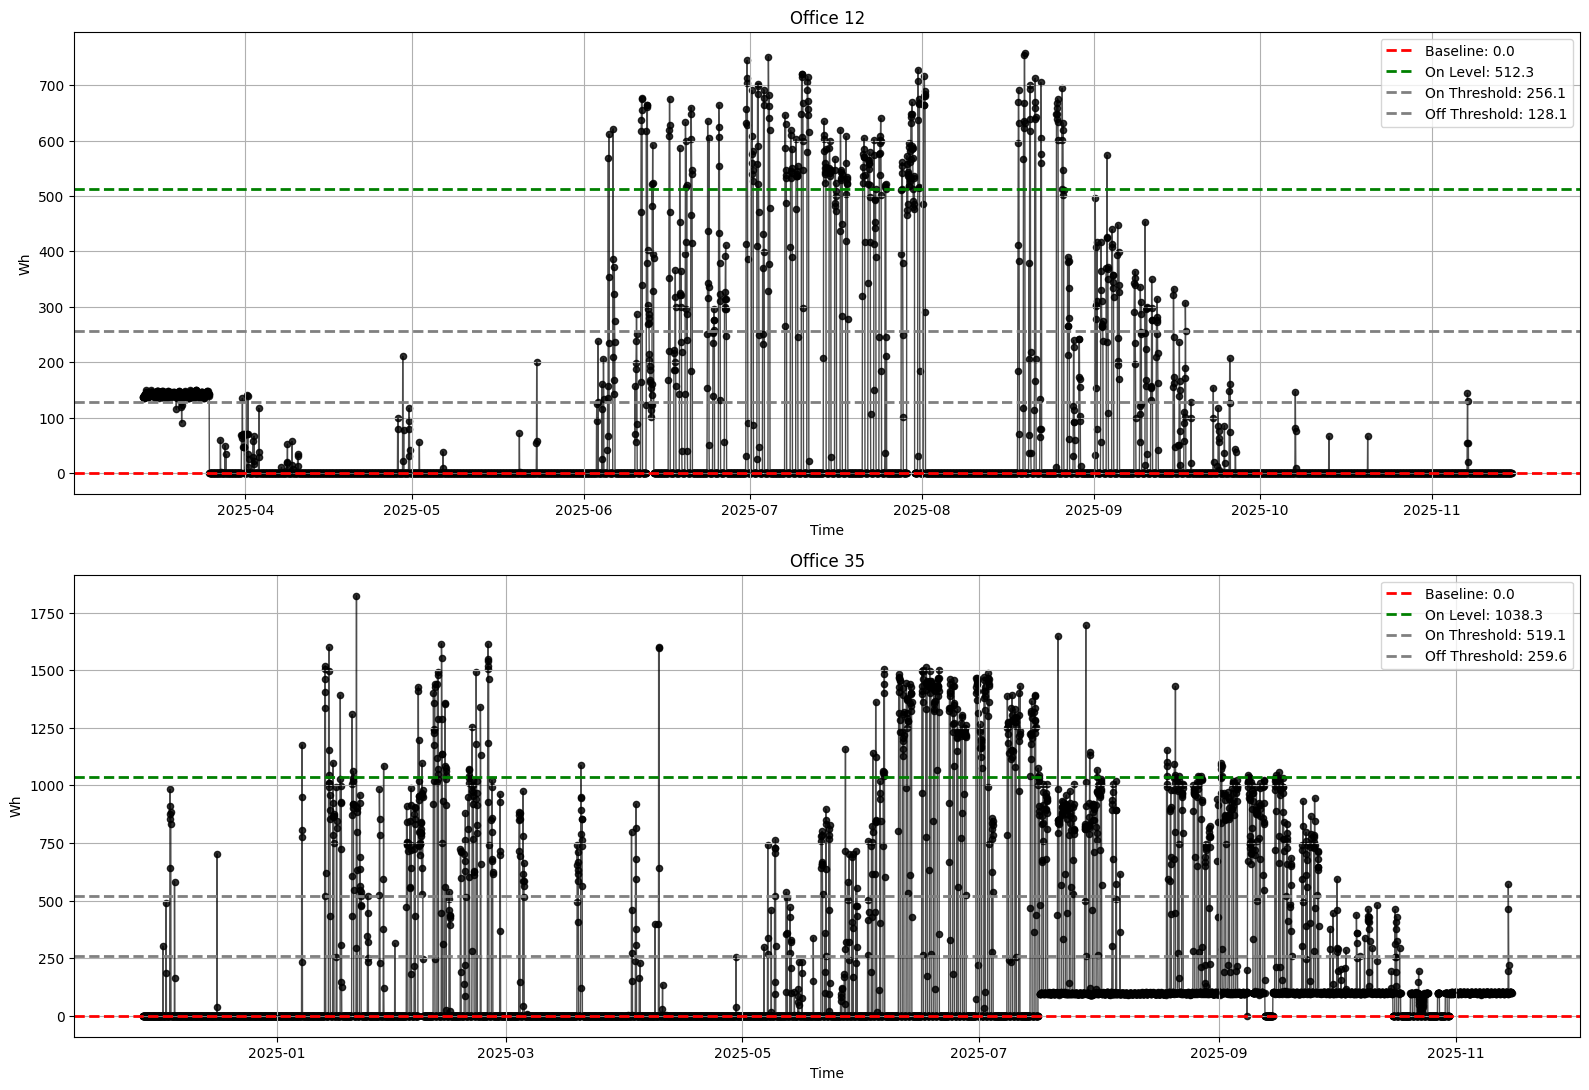

In [ ]:
i=1
print(th_on[rooms[i]])
plt.figure(figsize=(16, 16))

for i in range (0,2):

  x = hvac_consumptions_dataframe.index
  y = hvac_consumptions_dataframe[f'{rooms[i]}_consumption']

  plt.subplot(3, 1, i+1)
  plt.plot(x,y,color='black',linewidth=1,alpha=0.7)
  plt.scatter(x,y,color='black',s=20,alpha=0.8)

  plt.axhline(y=baseline[rooms[i]],color='red',linestyle='--',linewidth=2,label=f'Baseline: {baseline[rooms[i]]:.1f}')
  plt.axhline(y=on_level[rooms[i]],color='green',linestyle='--',linewidth=2,label=f'On Level: {on_level[rooms[i]]:.1f}')
  plt.axhline(y=th_on[rooms[i]],color='grey',linestyle='--',linewidth=2,label=f'On Threshold: {th_on[rooms[i]]:.1f}')
  plt.axhline(y=th_off[rooms[i]],color='grey',linestyle='--',linewidth=2,label=f'Off Threshold: {th_off[rooms[i]]:.1f}')

  plt.title(f"Office {rooms[i][1]}{rooms[i][2]}")
  plt.xlabel("Time")
  plt.ylabel("Wh")
  plt.grid(True)
  #plt.xlim(pd.to_datetime('2025-06-01 01:00:00'), pd.to_datetime('2025-09-30 01:00:00'))
  plt.legend()


plt.tight_layout()
plt.show()

In [ ]:
on_off_sequence_simple_quantiles = {}

for room in rooms:

  state = 0  # start OFF
  states = []
  y = hvac_consumptions_dataframe[f'{room}_consumption']

  for val in y:
      if pd.isna(val):
          states.append(np.nan)
          continue
      if val <= th_off[room]:
          state = 0
      elif val >= th_on[room]:
          state = 1
      # else: keep previous state
      states.append(state)

  on_off_sequence_simple_quantiles[room] = pd.Series(states, index=y.index)

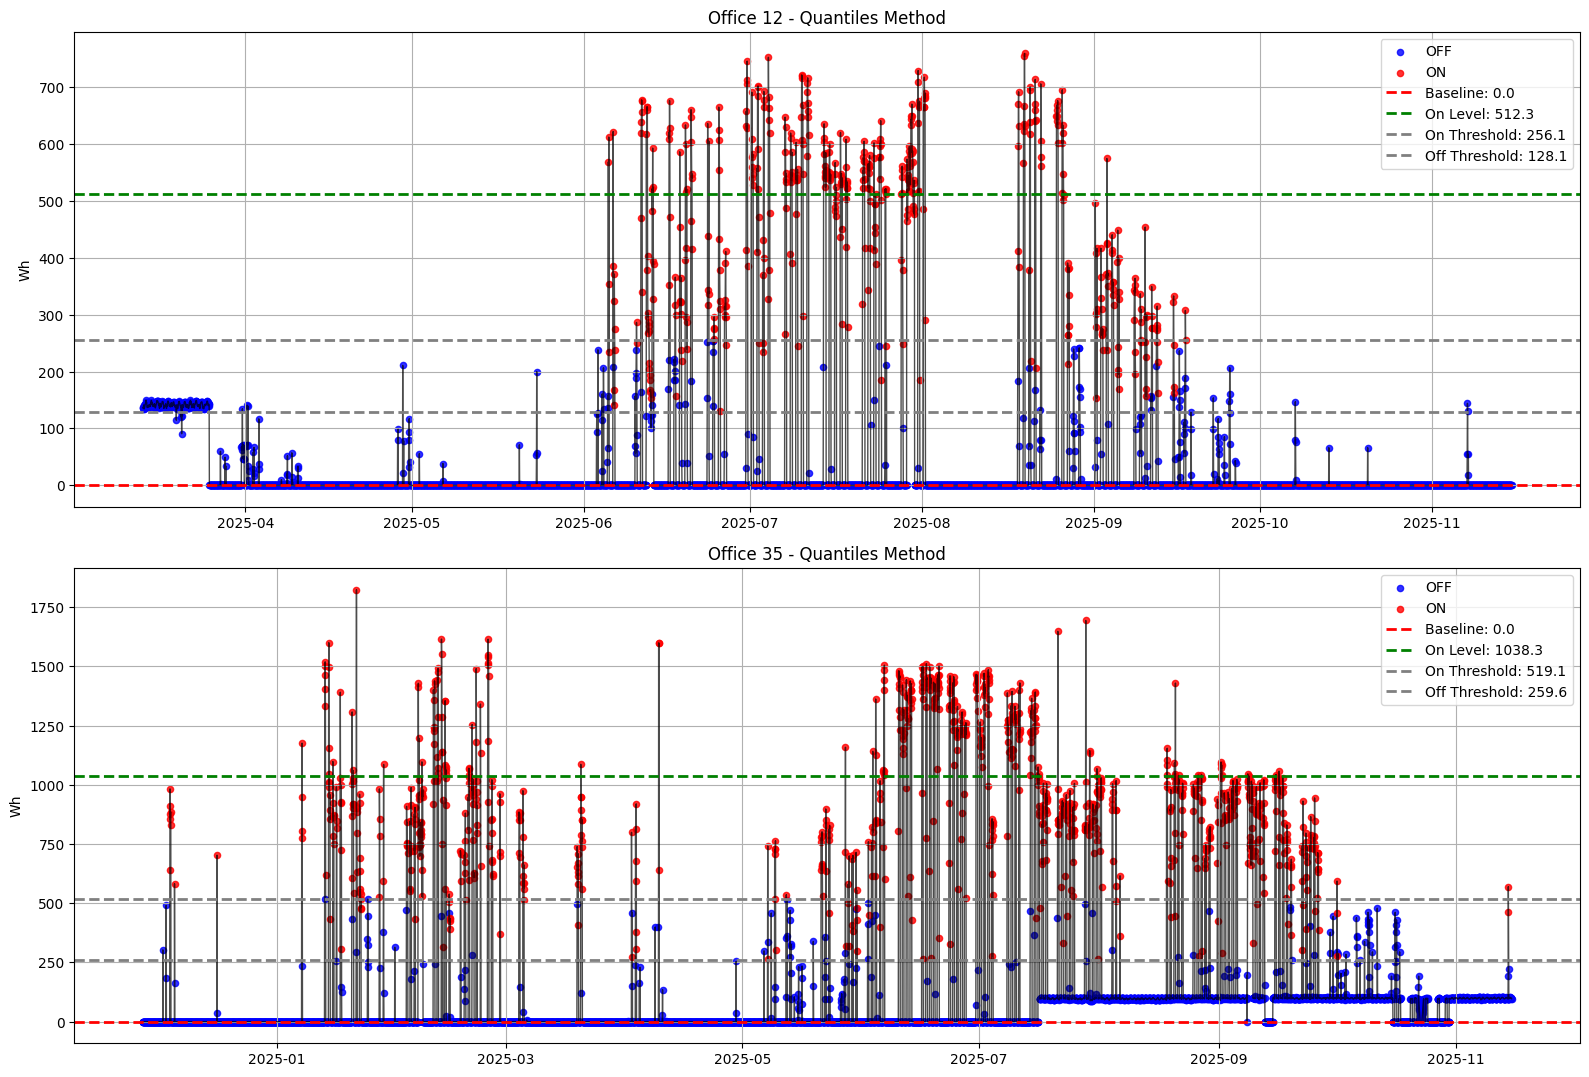

In [ ]:
plt.figure(figsize=(16,16))

for i in range (0,2):
  x = hvac_consumptions_dataframe.index
  y = hvac_consumptions_dataframe[f'{rooms[i]}_consumption']

# Reindex the HMM sequence to align with the full consumption data
  hvac_on_off_aligned = on_off_sequence_simple_quantiles[rooms[i]].reindex(y.index)

# Masks based on the aligned HMM sequence
  off_flag = (hvac_on_off_aligned == 0)
  on_flag = (hvac_on_off_aligned == 1)

  plt.subplot(3,1,i+1)
  plt.plot(x,y,color='black',linewidth=1,alpha=0.7)

  plt.scatter(x[off_flag],y[off_flag],color='blue',s=20,alpha=0.8,label='OFF')
  plt.scatter(x[on_flag],y[on_flag],color='red',s=20,alpha=0.8,label='ON')

  plt.axhline(y=baseline[rooms[i]],color='red',linestyle='--',linewidth=2,label=f'Baseline: {baseline[rooms[i]]:.1f}')
  plt.axhline(y=on_level[rooms[i]],color='green',linestyle='--',linewidth=2,label=f'On Level: {on_level[rooms[i]]:.1f}')
  plt.axhline(y=th_on[rooms[i]],color='grey',linestyle='--',linewidth=2,label=f'On Threshold: {th_on[rooms[i]]:.1f}')
  plt.axhline(y=th_off[rooms[i]],color='grey',linestyle='--',linewidth=2,label=f'Off Threshold: {th_off[rooms[i]]:.1f}')

  plt.title(f"Office {rooms[i][1]}{rooms[i][2]} - Quantiles Method")
  #plt.xlabel("Time")
  plt.ylabel("Wh")
  plt.grid(True)
  #plt.xlim(pd.to_datetime('2025-01-01 19:00:00'), pd.to_datetime('2025-11-12 01:00:00'))
  plt.legend()

plt.tight_layout()
plt.show()

### Στατιστικά - Quantiles Method

In [ ]:
for room in rooms:
    print(f'For {room} the baseline is {baseline[room]:.4f} and the on_level is {on_level[room]:.4f}. The on and off thresholds are: {th_on[room]:.4f} and {th_off[room]:.4f} respectively')
print()

rooms = ['o12', 'o35']
transitions = {}
for room, series in on_off_sequence_simple_quantiles.items():
    transitions[room] = series.diff()

for room in rooms:
    series = on_off_sequence_simple_quantiles[room]
    # offices don't all have data starting at the same date.
    first_valid = hvac_consumptions_dataframe[f'{room}_consumption'].first_valid_index()
    series_valid = series.loc[first_valid:]
    y = hvac_consumptions_dataframe[f'{room}_consumption'].reindex(series_valid.index)
    on_mask = (series_valid == 1).fillna(False)
    off_mask = (series_valid == 0).fillna(False)
    total = len(series_valid)
    on_count = int(on_mask.sum())
    off_count = int(off_mask.sum())

    print(f"Office {room[1]+room[2]}:")
    print(f"  Data available from: {first_valid}")
    print(f"  Total points: {total}")
    print(f"  ON points: {on_count}, OFF points: {off_count}")
    print(f"  ON percentage: {on_count/(on_count+off_count)*100:.2f}%")
    print(f"  Mean consumption (ON): {y[on_mask].mean():.3f} Wh,  Variance (ON): {y[on_mask].var():.3f}")
    print(f"  Mean consumption (OFF): {y[off_mask].mean():.3f} Wh,  Variance (OFF): {y[off_mask].var():.3f}")
    print(f"  Mean consumption (all points): {y.mean():.3f} Wh,  Variance (all points): {y.var():.3f}")
    print(f"  The HVAC flips {transitions[room].value_counts().get(1,0)} times from ON to OFF and another {transitions[room].value_counts().get(-1,0)} times from OFF to ON")
    print()

For o12 the baseline is 0.0000 and the on_level is 512.2770. The on and off thresholds are: 256.1385 and 128.0693 respectively
For o35 the baseline is 0.0000 and the on_level is 1038.2960. The on and off thresholds are: 519.1480 and 259.5740 respectively

Office 12:
  Data available from: 2025-03-13 12:00:00
  Total points: 5926
  ON points: 479, OFF points: 5447
  ON percentage: 8.08%
  Mean consumption (ON): 473.536 Wh,  Variance (ON): 24187.593
  Mean consumption (OFF): 11.487 Wh,  Variance (OFF): 1496.173
  Mean consumption (all points): 48.834 Wh,  Variance (all points): 19190.785
  The HVAC flips 60 times from ON to OFF and another 60 times from OFF to ON

Office 35:
  Data available from: 2024-11-27 11:00:00
  Total points: 8471
  ON points: 1042, OFF points: 7429
  ON percentage: 12.30%
  Mean consumption (ON): 955.562 Wh,  Variance (ON): 85460.133
  Mean consumption (OFF): 34.956 Wh,  Variance (OFF): 3726.282
  Mean consumption (all points): 148.198 Wh,  Variance (all points):

In [ ]:
monthly_breakdown_table(on_off_sequence_simple_quantiles, hvac_consumptions_dataframe, rooms, month_range, 'Quantiles Method')

--- Monthly breakdown: Quantiles Method ---


Office 12                                          \
        total_points ON_points OFF_points avg_consumption_ON   
2024-11            0         0          0                NaN   
2024-12            0         0          0                NaN   
2025-01            0         0          0                NaN   
2025-02            0         0          0                NaN   
2025-03          444         0        444                NaN   
2025-04          720         0        720                NaN   
2025-05          744         0        744                NaN   
2025-06          720       118        602             419.30   
2025-07          744       218        526             538.06   
2025-08          744        62        682             565.98   
2025-09          720        81        639             308.12   
2025-10          744         0        744                NaN   
2025-11          346         0        346                NaN   

                                      Office 35                       \
        avg_consumption_OFF   %_ON total_points ON_points OFF_points   
2024-11                 NaN    NaN           85         0         85   
2024-12                 NaN    NaN          744         9        735   
2025-01                 NaN    NaN          744        72        672   
2025-02                 NaN    NaN          672       159        513   
2025-03               93.69   0.00          744        33        711   
2025-04                2.85   0.00          720        11        709   
2025-05                0.65   0.00          744        44        700   
2025-06               12.19  16.39          720       192        528   
2025-07                2.47  29.30          744       215        529   
2025-08                5.27   8.33          744       114        630   
2025-09                8.38  11.25          720       188        532   
2025-10                0.60   0.00          744         3        741   
2025-11                1.16   0.00          346         2        344   

                                                       
        avg_consumption_ON avg_consumption_OFF   %_ON  
2024-11                NaN                0.00   0.00  
2024-12             807.46                1.60   1.21  
2025-01             920.66                7.68   9.68  
2025-02             930.77                6.27  23.66  
2025-03             741.34                1.16   4.44  
2025-04             782.24                3.54   1.53  
2025-05             637.63               14.12   5.91  
2025-06            1213.98                5.94  26.67  
2025-07            1020.60               53.26  28.90  
2025-08             876.01               99.68  15.32  
2025-09             841.91               96.29  26.11  
2025-10             444.10               77.21   0.40  
2025-11             516.66               99.86   0.58

## Flagging χρησιμοποιώντας HMM (χωρίς αρχικοποίηση από τον χρήστη)

In [ ]:
from hmmlearn.hmm import GaussianHMM

dummy_on_off_sequence_hmm = {}

y = hvac_consumptions_dataframe['o12_consumption']
y = y.dropna()
X = y.values.reshape(-1, 1)

dummy_hmm = GaussianHMM(
    n_components=2,
    covariance_type="full",
    n_iter=100,
    random_state=42,
)
dummy_hmm.fit(X)

hidden_states = dummy_hmm.predict(X)
on_state = np.argmax(dummy_hmm.means_.flatten())
hvac_on_off = (hidden_states == on_state).astype(int)

dummy_on_off_sequence_hmm['o12'] = pd.Series(hvac_on_off, index=y.index, dtype='Int64')

In [ ]:
# Office 35 - self-initialized HMM (same idea as Office 12 above)
y = hvac_consumptions_dataframe['o35_consumption']
y = y.dropna()
X = y.values.reshape(-1, 1)

dummy_hmm = GaussianHMM(
    n_components=2,
    covariance_type="full",
    n_iter=100,
    random_state=42,
)
dummy_hmm.fit(X)

hidden_states = dummy_hmm.predict(X)
on_state = np.argmax(dummy_hmm.means_.flatten())
hvac_on_off = (hidden_states == on_state).astype(int)

dummy_on_off_sequence_hmm['o35'] = pd.Series(hvac_on_off, index=y.index, dtype='Int64')

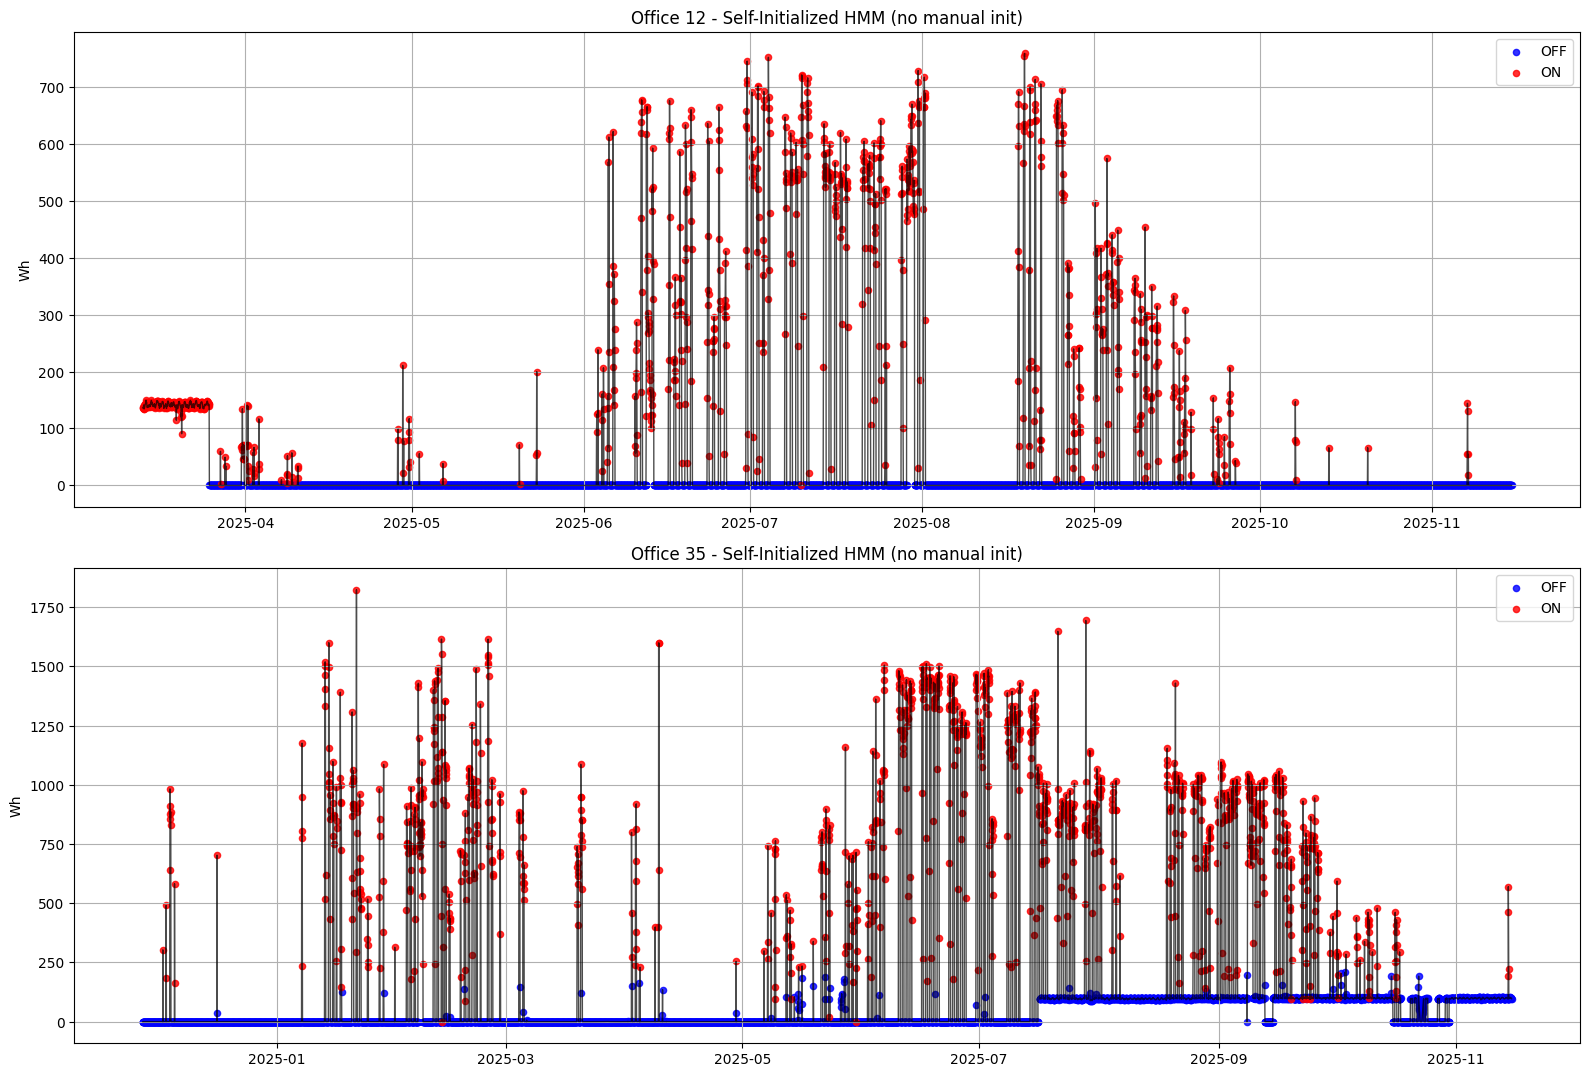

In [ ]:
# Visualize the self-initialized ('dummy') HMM results, for comparison against the real (manually-initialized) HMM section that follows.
dummy_rooms = ['o12', 'o35']
plt.figure(figsize=(16, 16))

for i in range(0, 2):
    x = hvac_consumptions_dataframe.index
    y = hvac_consumptions_dataframe[f'{dummy_rooms[i]}_consumption']

    hvac_on_off_aligned = dummy_on_off_sequence_hmm[dummy_rooms[i]].reindex(y.index)

    off_flag = (hvac_on_off_aligned == 0)
    on_flag = (hvac_on_off_aligned == 1)

    plt.subplot(3, 1, i + 1)
    plt.plot(x, y, color='black', linewidth=1, alpha=0.7)

    plt.scatter(x[off_flag], y[off_flag], color='blue', s=20, alpha=0.8, label='OFF')
    plt.scatter(x[on_flag], y[on_flag], color='red', s=20, alpha=0.8, label='ON')

    plt.title(f"Office {dummy_rooms[i][1]}{dummy_rooms[i][2]} - Self-Initialized HMM (no manual init)")
    plt.ylabel("Wh")
    plt.grid(True)
    plt.legend()

plt.tight_layout()
plt.show()

## Flagging χρησιμοποιώντας HMM

In [ ]:
import numpy as np
import pandas as pd
from hmmlearn.hmm import GaussianHMM

on_off_sequence_hmm = {}

### Office 12

In [ ]:

import numpy as np
import pandas as pd


def estimate_hmm_init(room, var_floor=1e-6):
    cons = hvac_consumptions_dataframe[f'{room}_consumption']
    methods = {
        'naive':     on_off_sequence_naive[room].astype('float'),
        'quantiles': on_off_sequence_simple_quantiles[room].astype('float'),
    }

    m_off, m_on, v_off, v_on = [], [], [], []
    print(f"--- {room}: per-method estimates (raw consumption) ---")
    for name, seq in methods.items():
        off = cons[seq == 0].dropna()
        on  = cons[seq == 1].dropna()
        m_off.append(off.mean()); m_on.append(on.mean())
        v_off.append(off.var());  v_on.append(on.var())
        print(f"  {name:10s} OFF: mean={off.mean():8.2f}  var={off.var():12.2f}  n={len(off):5d}")
        print(f"  {name:10s} ON : mean={on.mean():8.2f}  var={on.var():12.2f}  n={len(on):5d}")

    means  = np.array([[np.nanmean(m_off)], [np.nanmean(m_on)]])
    covars = np.array([[[max(np.nanmean(v_off), var_floor)]],
                       [[max(np.nanmean(v_on),  var_floor)]]])

    def transmat_of(seq):
        prev = seq.shift(1)
        step_ok = seq.index.to_series().diff().eq(pd.Timedelta(hours=1)).to_numpy()
        ok = seq.notna().to_numpy() & prev.notna().to_numpy() & step_ok
        a = prev.to_numpy()[ok].astype(int)
        b = seq.to_numpy()[ok].astype(int)
        M = np.zeros((2, 2))
        np.add.at(M, (a, b), 1)
        rs = M.sum(axis=1, keepdims=True)
        return np.divide(M, rs, out=np.full((2, 2), 0.5), where=rs > 0)

    def startprob_of(seq):
        v = seq.dropna().to_numpy().astype(int)
        counts = np.bincount(v, minlength=2).astype(float)
        return counts / counts.sum()

    mats = {name: transmat_of(seq) for name, seq in methods.items()}
    for name, T in mats.items():
        print(f"  {name:10s} transmat: {np.round(T, 4).tolist()}")
    transmat = np.mean(list(mats.values()), axis=0)
    transmat = transmat / transmat.sum(axis=1, keepdims=True)

    sps = {name: startprob_of(seq) for name, seq in methods.items()}
    for name, p in sps.items():
        print(f"  {name:10s} startprob: {np.round(p, 4).tolist()}")
    startprob = np.mean(list(sps.values()), axis=0)
    startprob = startprob / startprob.sum()

    return means, covars, transmat, startprob


init_means_o12, init_covars_o12, init_transmat_o12, init_startprob_o12 = estimate_hmm_init('o12')

print("\n# copy-paste into the Office 12 HMM cell:")
print(f"hmm.startprob_ = np.array({np.round(init_startprob_o12, 3).tolist()})")
print(f"hmm.means_    = np.array({np.round(init_means_o12, 2).tolist()})")
print(f"hmm.covars_   = np.array({np.round(init_covars_o12, 2).tolist()})")
print(f"hmm.transmat_ = np.array({np.round(init_transmat_o12, 3).tolist()})")


--- o12: per-method estimates (raw consumption) ---
  naive      OFF: mean=    9.76  var=     1177.43  n= 5397
  naive      ON : mean=  447.45  var=    28519.95  n=  529
  quantiles  OFF: mean=   11.49  var=     1496.17  n= 5447
  quantiles  ON : mean=  473.54  var=    24187.59  n=  479
  naive      transmat: [[0.9859, 0.0141], [0.1437, 0.8563]]
  quantiles  transmat: [[0.989, 0.011], [0.1253, 0.8747]]
  naive      startprob: [0.9107, 0.0893]
  quantiles  startprob: [0.9192, 0.0808]

# copy-paste into the Office 12 HMM cell:
hmm.startprob_ = np.array([0.915, 0.085])
hmm.means_    = np.array([[10.62], [460.49]])
hmm.covars_   = np.array([[[1336.8]], [[26353.77]]])
hmm.transmat_ = np.array([[0.987, 0.013], [0.134, 0.866]])


In [ ]:
# 1. Extract and clean the data
y = hvac_consumptions_dataframe['o12_consumption']
#y[y.index <= pd.to_datetime('2025-03-26 00:00:00')] = 0
y = y.dropna()

# 2. Reshape for HMM
X = y.values.reshape(-1, 1)

# 3. Define HMM
hmm = GaussianHMM(
    n_components=2,
    covariance_type="full",
    n_iter=100,
    random_state=42,
    init_params="",
    params="stmc"
)

# 4. Initialization using estimates
hmm.startprob_ = np.array([0.915, 0.085])
hmm.means_    = np.array([[10.62], [460.49]])
hmm.covars_   = np.array([[[1336.8]], [[26353.77]]])
hmm.transmat_ = np.array([[0.987, 0.013], [0.134, 0.866]])

# 5. Fit model
hmm.fit(X)

# 6. Decode hidden states
hidden_states = hmm.predict(X)

# 7. Map states to OFF=0, ON=1 using means
state_means = hmm.means_.flatten()
on_state = np.argmax(state_means)

hvac_on_off = (hidden_states == on_state).astype(int)

# 8. Back to pandas Series
on_off_sequence_hmm['o12'] = pd.Series(
    hvac_on_off,
    index=y.index,
    dtype='Int64'
)

# 9. Snapshot the fitted parameters before the office35 fit below reuses/overwrites
# the `hmm` variable
hmm_o12_means = hmm.means_.flatten().copy()
hmm_o12_covars = hmm.covars_.copy()
hmm_o12_transmat = hmm.transmat_.copy()
hmm_o12_startprob = hmm.startprob_.copy()

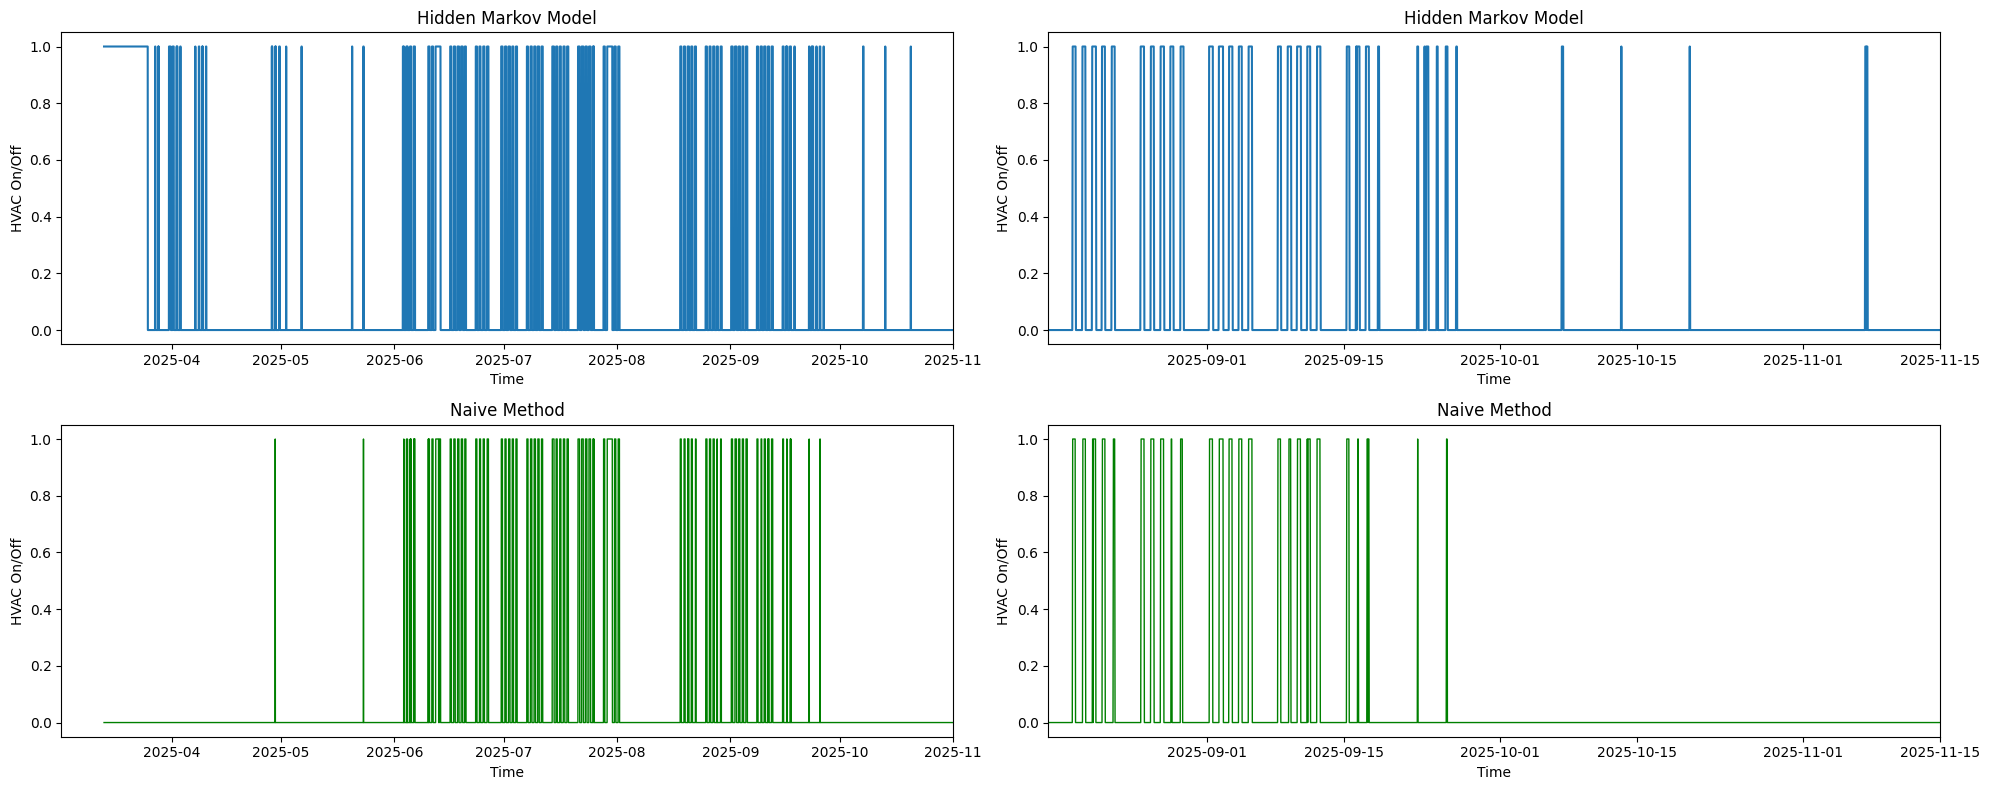

In [ ]:
plt.figure(figsize=(20, 8))

plt.subplot(2, 2, 1)
plt.plot(on_off_sequence_hmm['o12'])
plt.title("Hidden Markov Model")
plt.xlabel("Time")
plt.ylabel("HVAC On/Off")
plt.xlim(pd.to_datetime('2025-03-01 19:00:00'), pd.to_datetime('2025-11-01 01:00:00'))

plt.subplot(2, 2, 2)
plt.plot(on_off_sequence_hmm['o12'])
plt.title("Hidden Markov Model")
plt.xlabel("Time")
plt.ylabel("HVAC On/Off")
plt.xlim(pd.to_datetime('2025-08-15 19:00:00'), pd.to_datetime('2025-11-15 01:00:00'))

plt.subplot(2, 2, 3)
plt.plot(on_off_sequence_naive['o12'], color='green', linewidth=1)
plt.title("Naive Method")
plt.xlabel("Time")
plt.ylabel("HVAC On/Off")
plt.xlim(pd.to_datetime('2025-03-01 19:00:00'), pd.to_datetime('2025-11-01 01:00:00'))

plt.subplot(2, 2, 4)
plt.plot(on_off_sequence_naive['o12'], color='green', linewidth=1)
plt.title("Naive Method")
plt.xlabel("Time")
plt.ylabel("HVAC On/Off")
plt.xlim(pd.to_datetime('2025-08-15 19:00:00'), pd.to_datetime('2025-11-15 01:00:00'))

plt.tight_layout()
plt.show()

### Office 35

In [ ]:
init_means_o35, init_covars_o35, init_transmat_o35, init_startprob_o35 = estimate_hmm_init('o35')

print("\n# copy-paste into the Office 35 HMM cell:")
print(f"hmm.startprob_ = np.array({np.round(init_startprob_o35, 3).tolist()})")
print(f"hmm.means_    = np.array({np.round(init_means_o35, 2).tolist()})")
print(f"hmm.covars_   = np.array({np.round(init_covars_o35, 2).tolist()})")
print(f"hmm.transmat_ = np.array({np.round(init_transmat_o35, 3).tolist()})")


--- o35: per-method estimates (raw consumption) ---
  naive      OFF: mean=   28.88  var=     1997.52  n= 7238
  naive      ON : mean=  848.62  var=   136945.41  n= 1233
  quantiles  OFF: mean=   34.96  var=     3726.28  n= 7429
  quantiles  ON : mean=  955.56  var=    85460.13  n= 1042
  naive      transmat: [[0.9732, 0.0268], [0.1573, 0.8427]]
  quantiles  transmat: [[0.981, 0.019], [0.1353, 0.8647]]
  naive      startprob: [0.8544, 0.1456]
  quantiles  startprob: [0.877, 0.123]

# copy-paste into the Office 35 HMM cell:
hmm.startprob_ = np.array([0.866, 0.134])
hmm.means_    = np.array([[31.92], [902.09]])
hmm.covars_   = np.array([[[2861.9]], [[111202.77]]])
hmm.transmat_ = np.array([[0.977, 0.023], [0.146, 0.854]])


In [ ]:
# 1. Extract and clean the data
y = hvac_consumptions_dataframe['o35_consumption']
y = y.dropna()

# 2. Reshape for HMM
X = y.values.reshape(-1, 1)

# 3. Define HMM
hmm = GaussianHMM(
    n_components=2,
    covariance_type="full",
    n_iter=100,
    random_state=42,
    init_params="",
    params="stmc"
)

# 4. Initialization using estimates
hmm.startprob_ = np.array([0.866, 0.134])
hmm.means_    = np.array([[31.92], [902.09]])
hmm.covars_   = np.array([[[2861.9]], [[111202.77]]])
hmm.transmat_ = np.array([[0.977, 0.023], [0.146, 0.854]])

# 5. Fit model
hmm.fit(X)

# 6. Decode hidden states
hidden_states = hmm.predict(X)

# 7. Map states to OFF=0, ON=1 using means
state_means = hmm.means_.flatten()
on_state = np.argmax(state_means)

hvac_on_off = (hidden_states == on_state).astype(int)

# 8. Create the result series
new_series = pd.Series(
    hvac_on_off,
    index=y.index,
    name='o35',
    dtype='Int64'
)

temporary = on_off_sequence_hmm['o12']
on_off_sequence_hmm = pd.DataFrame()
on_off_sequence_hmm['o35'] = new_series
on_off_sequence_hmm['o12'] = temporary

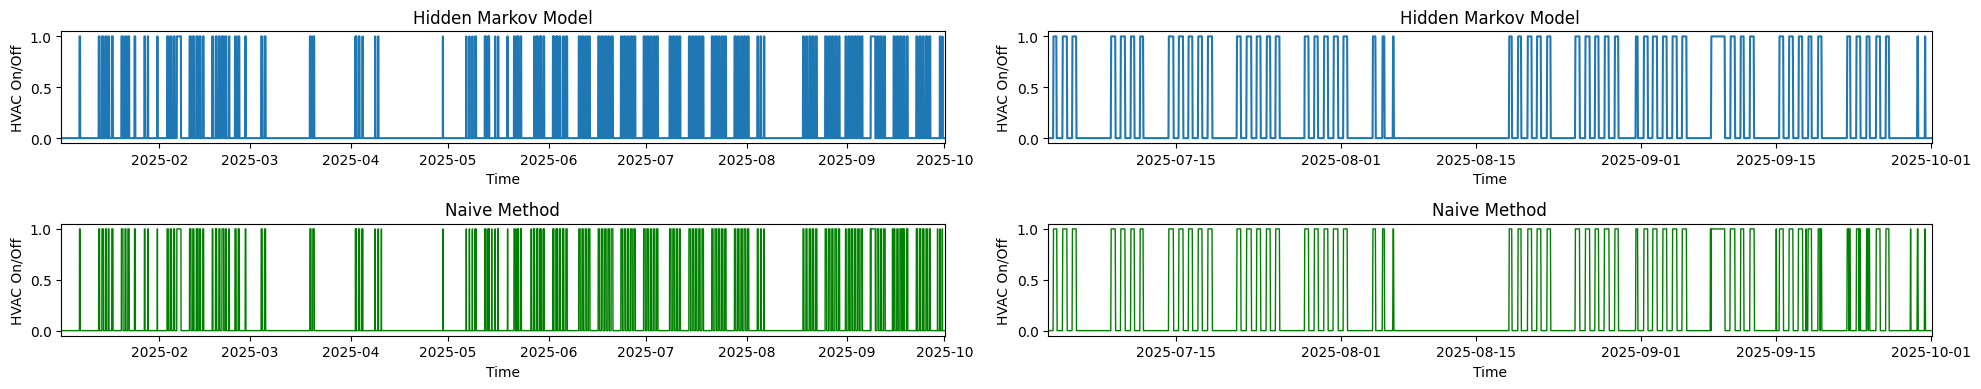

In [ ]:
plt.figure(figsize=(20, 4))

plt.subplot(2, 2, 1)
plt.plot(on_off_sequence_hmm['o35'])
plt.title("Hidden Markov Model")
plt.xlabel("Time")
plt.ylabel("HVAC On/Off")
plt.xlim(pd.to_datetime('2025-01-01 19:00:00'), pd.to_datetime('2025-10-01 01:00:00'))

plt.subplot(2, 2, 2)
plt.plot(on_off_sequence_hmm['o35'])
plt.title("Hidden Markov Model")
plt.xlabel("Time")
plt.ylabel("HVAC On/Off")
plt.xlim(pd.to_datetime('2025-07-01 19:00:00'), pd.to_datetime('2025-10-01 01:00:00'))

plt.subplot(2, 2, 3)
plt.plot(on_off_sequence_naive['o35'], color='green', linewidth=1)
plt.title("Naive Method")
plt.xlabel("Time")
plt.ylabel("HVAC On/Off")
plt.xlim(pd.to_datetime('2025-01-01 19:00:00'), pd.to_datetime('2025-10-01 01:00:00'))

plt.subplot(2, 2, 4)
plt.plot(on_off_sequence_naive['o35'], color='green', linewidth=1)
plt.title("Naive Method")
plt.xlabel("Time")
plt.ylabel("HVAC On/Off")
plt.xlim(pd.to_datetime('2025-07-01 19:00:00'), pd.to_datetime('2025-10-01 01:00:00'))

plt.tight_layout()
plt.show()

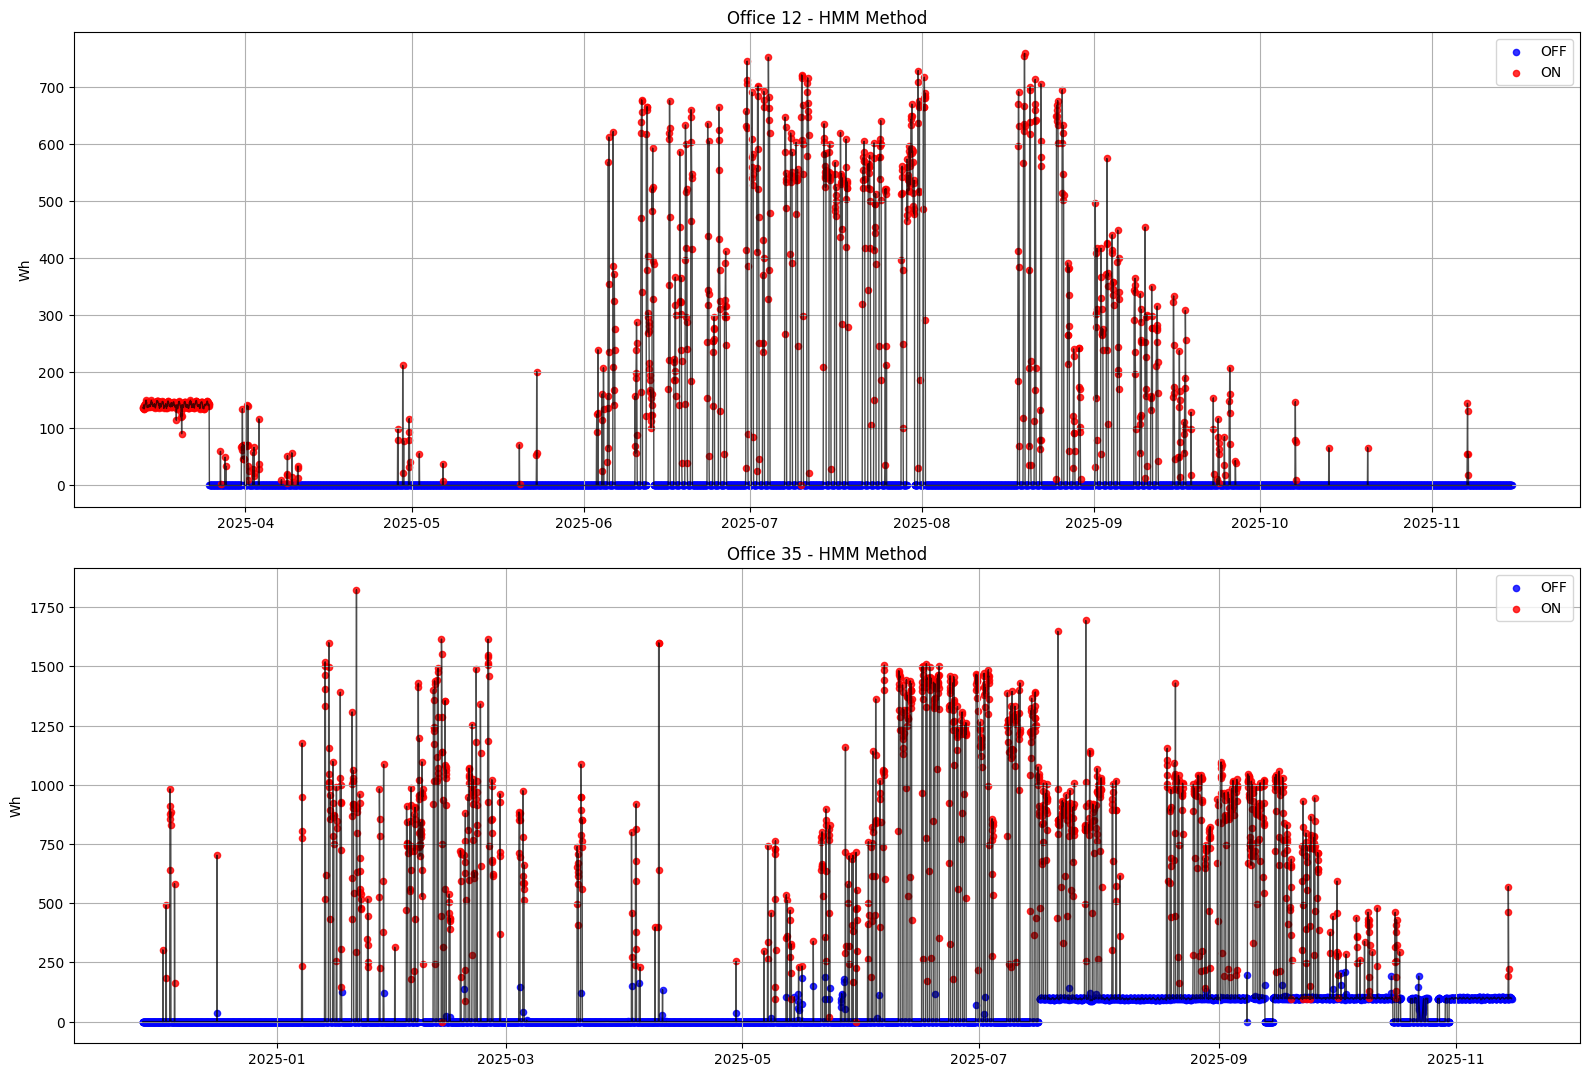

In [ ]:
rooms = ['o12', 'o35']
plt.figure(figsize=(16, 16))

for i in range(0, 2):
  x = hvac_consumptions_dataframe.index
  y = hvac_consumptions_dataframe[f'{rooms[i]}_consumption']

  # Reindex the HMM sequence to align with the full consumption data
  hvac_on_off_aligned = on_off_sequence_hmm[rooms[i]].reindex(y.index)

  # Masks based on the aligned HMM sequence
  off_flag = (hvac_on_off_aligned == 0)
  on_flag = (hvac_on_off_aligned == 1)

  plt.subplot(3, 1, i + 1)
  plt.plot(x, y, color='black', linewidth=1, alpha=0.7)

  plt.scatter(x[off_flag], y[off_flag], color='blue', s=20, alpha=0.8, label='OFF')
  plt.scatter(x[on_flag], y[on_flag], color='red', s=20, alpha=0.8, label='ON')

  plt.title(f"Office {rooms[i][1]}{rooms[i][2]} - HMM Method")
  plt.ylabel("Wh")
  plt.grid(True)
  #plt.xlim(pd.to_datetime('2025-03-12 19:00:00'), pd.to_datetime('2025-04-12 01:00:00'))
  plt.legend()

plt.tight_layout()
plt.show()

### Στατιστικά - HMM

In [ ]:

rooms = ['o12', 'o35']
for room in rooms:
    series = on_off_sequence_hmm[room]

    first_valid = hvac_consumptions_dataframe[f'{room}_consumption'].first_valid_index()
    series_valid = series.loc[first_valid:]
    y = hvac_consumptions_dataframe[f'{room}_consumption'].reindex(series_valid.index)
    on_mask = (series_valid == 1).fillna(False)
    off_mask = (series_valid == 0).fillna(False)
    total = len(series_valid)
    on_count = int(on_mask.sum())
    off_count = int(off_mask.sum())

    print(f"Office {room[1]+room[2]}:")
    print(f"  Data available from: {first_valid}")
    print(f"  Total points: {total}")
    print(f"  ON points: {on_count}, OFF points: {off_count}")
    print(f"  ON percentage: {on_count/(on_count+off_count)*100:.2f}%")
    print(f"  Mean consumption (ON): {y[on_mask].mean():.3f} Wh,  Variance (ON): {y[on_mask].var():.3f}")
    print(f"  Mean consumption (OFF): {y[off_mask].mean():.3f} Wh,  Variance (OFF): {y[off_mask].var():.3f}")
    print(f"  Mean consumption (all points): {y.mean():.3f} Wh,  Variance (all points): {y.var():.3f}")
    print()

Office 12:
  Data available from: 2025-03-13 12:00:00
  Total points: 5926
  ON points: 991, OFF points: 4935
  ON percentage: 16.72%
  Mean consumption (ON): 292.019 Wh,  Variance (ON): 43767.359
  Mean consumption (OFF): 0.000 Wh,  Variance (OFF): 0.000
  Mean consumption (all points): 48.834 Wh,  Variance (all points): 19190.785

Office 35:
  Data available from: 2024-11-27 11:00:00
  Total points: 8471
  ON points: 1195, OFF points: 7276
  ON percentage: 14.11%
  Mean consumption (ON): 870.701 Wh,  Variance (ON): 125499.364
  Mean consumption (OFF): 29.535 Wh,  Variance (OFF): 2064.942
  Mean consumption (all points): 148.198 Wh,  Variance (all points): 105209.498



In [ ]:
monthly_breakdown_table(on_off_sequence_hmm, hvac_consumptions_dataframe, rooms, month_range, 'HMM')

--- Monthly breakdown: HMM ---


Office 12                                          \
        total_points ON_points OFF_points avg_consumption_ON   
2024-11            0         0          0                NaN   
2024-12            0         0          0                NaN   
2025-01            0         0          0                NaN   
2025-02            0         0          0                NaN   
2025-03          444       304        140             136.84   
2025-04          720        37        683              55.44   
2025-05          744         8        736              60.84   
2025-06          720       169        551             336.18   
2025-07          744       232        512             511.19   
2025-08          744        93        651             415.96   
2025-09          720       137        583             221.25   
2025-10          744         6        738              74.25   
2025-11          346         5        341              80.49   

                                      Office 35                       \
        avg_consumption_OFF   %_ON total_points ON_points OFF_points   
2024-11                 NaN    NaN           85         0         85   
2024-12                 NaN    NaN          744        13        731   
2025-01                 NaN    NaN          744        87        657   
2025-02                 NaN    NaN          672       171        501   
2025-03                 0.0  68.47          744        34        710   
2025-04                 0.0   5.14          720        17        703   
2025-05                 0.0   1.08          744        71        673   
2025-06                 0.0  23.47          720       201        519   
2025-07                 0.0  31.18          744       224        520   
2025-08                 0.0  12.50          744       123        621   
2025-09                 0.0  19.03          720       209        511   
2025-10                 0.0   0.81          744        41        703   
2025-11                 0.0   1.45          346         4        342   

                                                       
        avg_consumption_ON avg_consumption_OFF   %_ON  
2024-11                NaN                0.00   0.00  
2024-12             646.82                0.05   1.75  
2025-01             818.45                0.37  11.69  
2025-02             883.22                0.36  25.45  
2025-03             734.11                0.46   4.57  
2025-04             622.71                0.75   2.36  
2025-05             501.20                3.50   9.54  
2025-06            1173.66                0.61  27.92  
2025-07             993.92               48.02  30.11  
2025-08             830.51               97.44  16.53  
2025-09             782.38               90.00  29.03  
2025-10             318.30               64.72   5.51  
2025-11             362.24               99.23   1.16

In [ ]:
# Fitted HMM parameters, after .fit()
fitted_hmm = {
    'o12': (hmm_o12_startprob, hmm_o12_means, hmm_o12_covars, hmm_o12_transmat),
    'o35': (hmm.startprob_, hmm.means_, hmm.covars_, hmm.transmat_),
}

for room, (sp, mu, cov, A) in fitted_hmm.items():
    mu  = np.asarray(mu).ravel()
    var = np.asarray(cov).reshape(2, -1)[:, 0]
    sp  = np.asarray(sp).ravel()
    A   = np.asarray(A)
    on = int(np.argmax(mu)); off = 1 - on
    A_off_on = A[np.ix_([off, on], [off, on])]

    print(f"=== Office {room[1]}{room[2]} - fitted HMM parameters (OFF, ON) ===")
    print(f"  means     : OFF = {mu[off]:9.2f}   ON = {mu[on]:9.2f}")
    print(f"  variances : OFF = {var[off]:9.2f}   ON = {var[on]:9.2f}")
    print(f"  startprob : OFF = {sp[off]:9.3f}   ON = {sp[on]:9.3f}")
    print(f"  transmat  : [[OFF->OFF {A_off_on[0, 0]:.3f}, OFF->ON {A_off_on[0, 1]:.3f}],")
    print(f"               [ ON->OFF {A_off_on[1, 0]:.3f},  ON->ON {A_off_on[1, 1]:.3f}]]")
    print()

=== Office 12 - fitted HMM parameters (OFF, ON) ===
  means     : OFF =      0.00   ON =    292.02
  variances : OFF =      0.00   ON =  43723.46
  startprob : OFF =     0.000   ON =     1.000
  transmat  : [[OFF->OFF 0.980, OFF->ON 0.020],
               [ ON->OFF 0.103,  ON->ON 0.897]]

=== Office 35 - fitted HMM parameters (OFF, ON) ===
  means     : OFF =     29.54   ON =    868.68
  variances : OFF =   2070.26   ON = 126807.08
  startprob : OFF =     1.000   ON =     0.000
  transmat  : [[OFF->OFF 0.978, OFF->ON 0.022],
               [ ON->OFF 0.135,  ON->ON 0.865]]



## Flagging aggregation

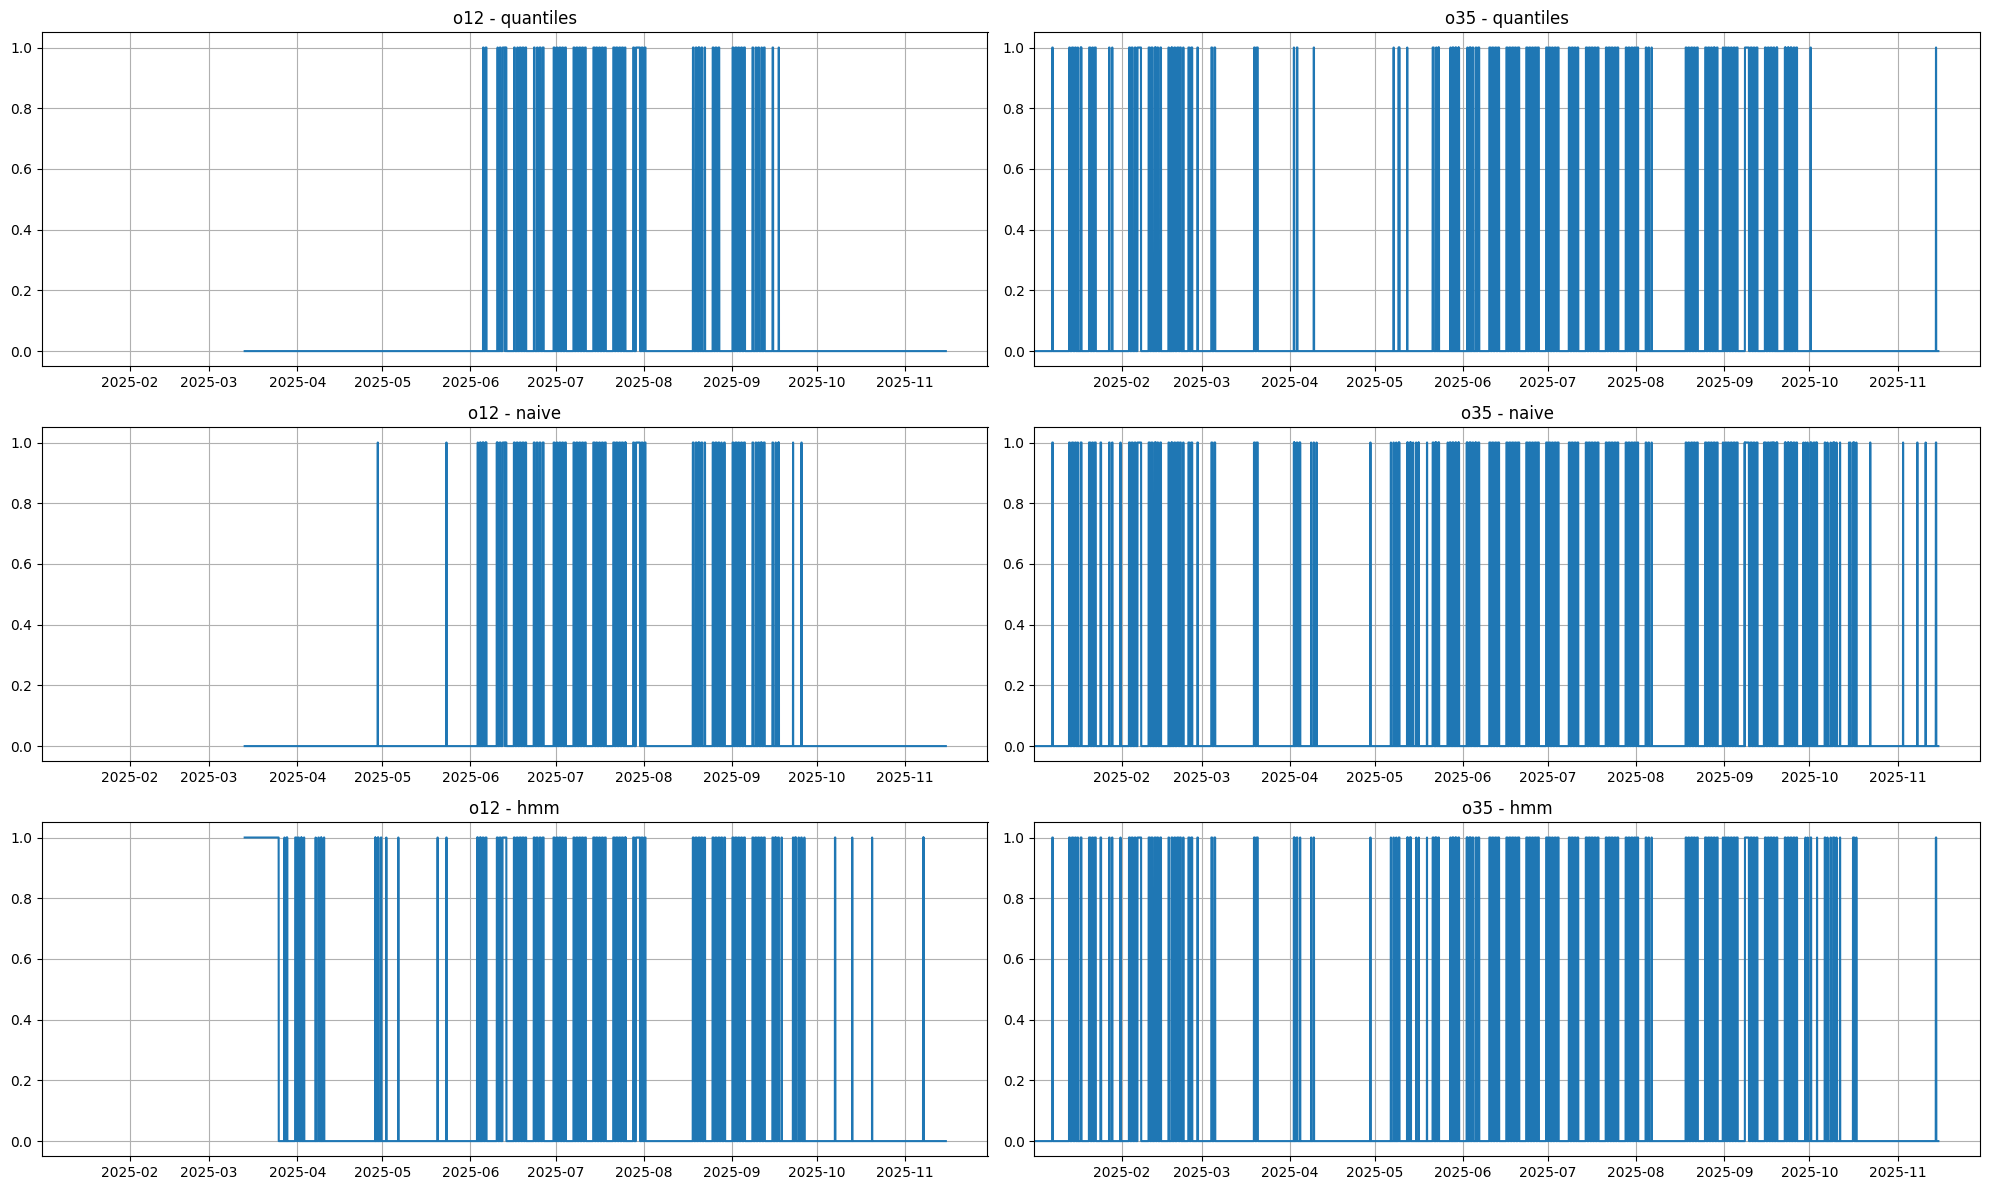

In [ ]:
plt.figure(figsize=(20, 12))

for i in range (0,2):
  plt.subplot(3,2,i+1)
  plt.plot(on_off_sequence_simple_quantiles[rooms[i]])
  plt.grid(True)
  plt.xlim(pd.to_datetime('2025-01-01 01:00:00'), pd.to_datetime('2025-11-30 01:00:00'))
  plt.title(f'{rooms[i]} - quantiles')

  plt.subplot(3,2,i+3)
  plt.plot(on_off_sequence_naive[rooms[i]])
  plt.grid(True)
  plt.xlim(pd.to_datetime('2025-01-01 01:00:00'), pd.to_datetime('2025-11-30 01:00:00'))
  plt.title(f'{rooms[i]} - naive')

  plt.subplot(3,2,i+5)
  plt.plot(on_off_sequence_hmm[rooms[i]])
  plt.grid(True)
  plt.xlim(pd.to_datetime('2025-01-01 01:00:00'), pd.to_datetime('2025-11-30 01:00:00'))
  plt.title(f'{rooms[i]} - hmm')

plt.tight_layout()
plt.show()



o12: Quantiles method: 52 out of 8471 entries are classified differently
o12: Naive method: 2 out of 8471 entries are classified differently
o12: HMM method: 460 out of 8471 entries are classified differently


o35: Quantiles method: 140 out of 8471 entries are classified differently
o35: Naive method: 51 out of 8471 entries are classified differently
o35: HMM method: 13 out of 8471 entries are classified differently




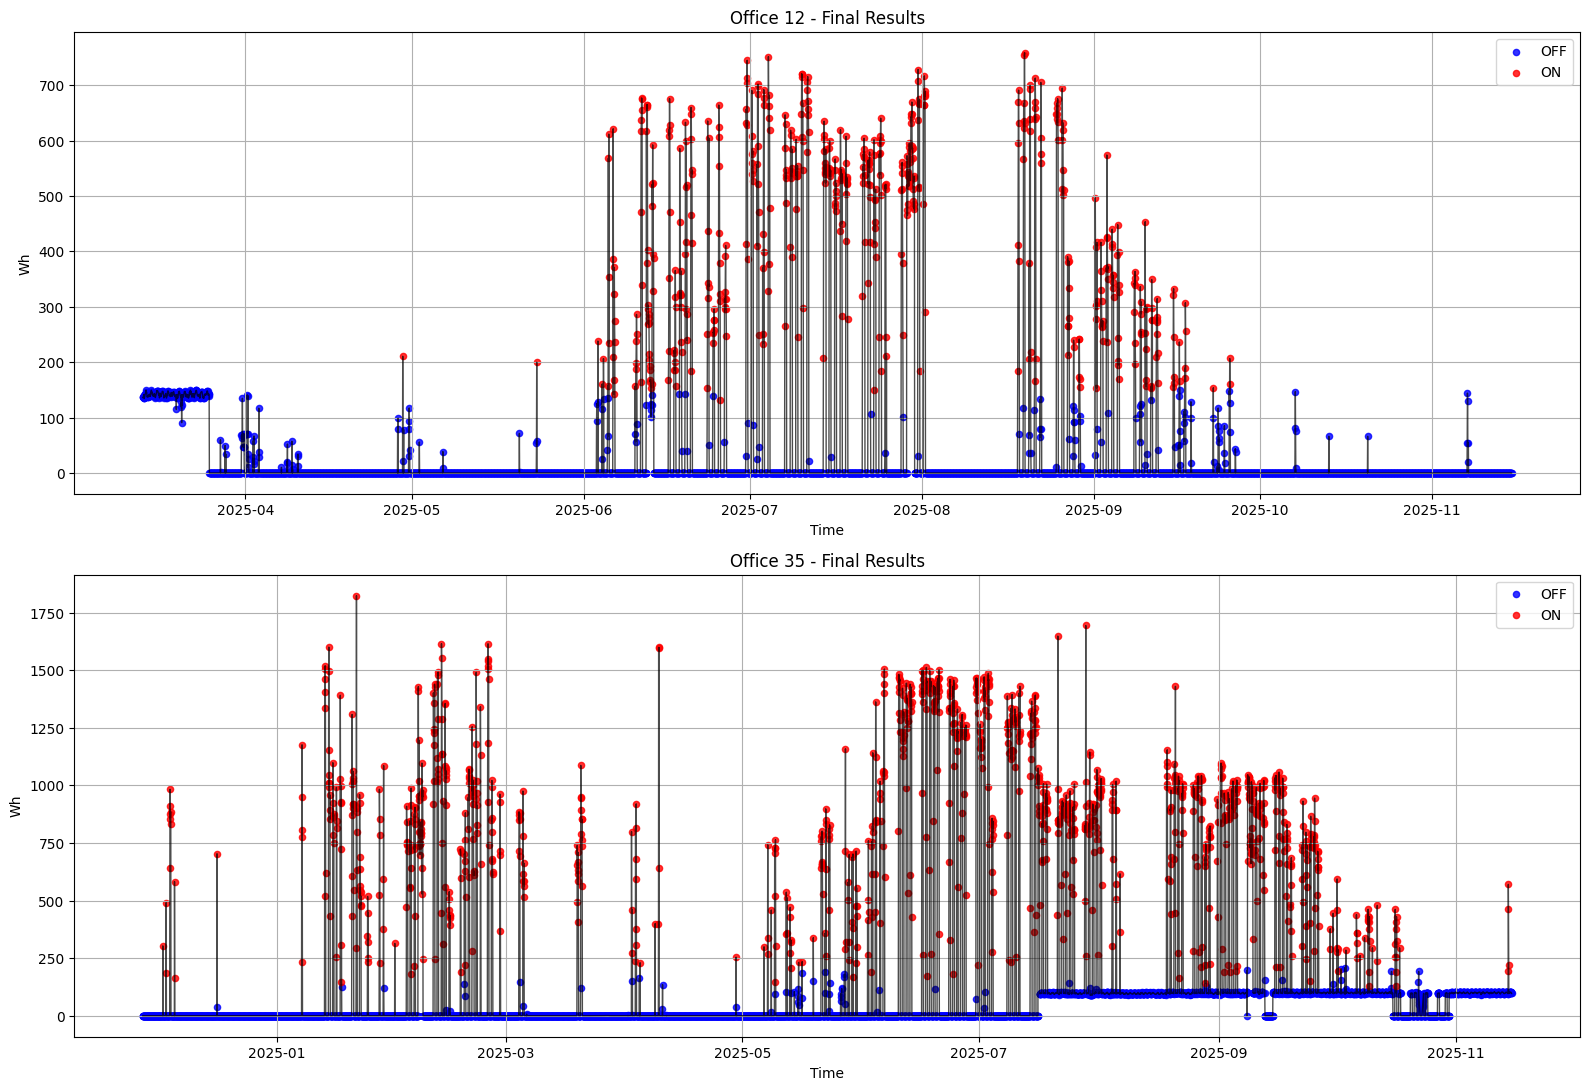

In [ ]:
on_off_sequence_aggregation = {}
for room in rooms:
  # Sum the on/off sequences from the three methods
  summed_states = on_off_sequence_hmm[room].fillna(0).astype(int) + \
                  on_off_sequence_naive[room].fillna(0).astype(int) + \
                  on_off_sequence_simple_quantiles[room].fillna(0).astype(int)

  # Re-map the summed states: 0 or 1 -> 0, and 2 or 3 -> 1
  on_off_sequence_aggregation[room] = (summed_states >= 2).astype(int).reindex_like(hvac_consumptions_dataframe[f'{room}_consumption'])

for room in rooms:
  xor_results = on_off_sequence_simple_quantiles[room].fillna(0).astype(int) ^ on_off_sequence_aggregation[room]
  print(f'{room}: Quantiles method: {xor_results.value_counts().get(1,0)} out of {len(on_off_sequence_simple_quantiles[room])} entries are classified differently')
  xor_results = on_off_sequence_naive[room] ^ on_off_sequence_aggregation[room]
  print(f'{room}: Naive method: {xor_results.value_counts().get(1,0)} out of {len(on_off_sequence_simple_quantiles[room])} entries are classified differently')
  xor_results = on_off_sequence_aggregation[room] ^ on_off_sequence_hmm[room]
  print(f'{room}: HMM method: {xor_results.value_counts().get(1,0)} out of {len(on_off_sequence_simple_quantiles[room])} entries are classified differently')
  print('\n')


plt.figure(figsize=(16,16))

for i in range (0,2):
  x = hvac_consumptions_dataframe.index
  y = hvac_consumptions_dataframe[f'{rooms[i]}_consumption']

  off_flag = (on_off_sequence_aggregation[rooms[i]] == 0)
  on_flag = (on_off_sequence_aggregation[rooms[i]] == 1)

  plt.subplot(3,1,i+1)
  plt.plot(x,y,color='black',linewidth=1,alpha=0.7)

  plt.scatter(x[off_flag],y[off_flag],color='blue',s=20,alpha=0.8,label='OFF')
  plt.scatter(x[on_flag],y[on_flag],color='red',s=20,alpha=0.8,label='ON')

  plt.title(f"Office {rooms[i][1]}{rooms[i][2]} - Final Results")
  plt.xlabel("Time")
  plt.ylabel("Wh")
  plt.grid(True)
  #plt.xlim(pd.to_datetime('2025-01-01 19:00:00'), pd.to_datetime('2025-11-21 01:00:00'))
  plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
print(on_off_sequence_aggregation['o12'].value_counts())
print(on_off_sequence_aggregation['o35'].value_counts())

0    7940
1     531
Name: count, dtype: int64
0    7289
1    1182
Name: count, dtype: int64


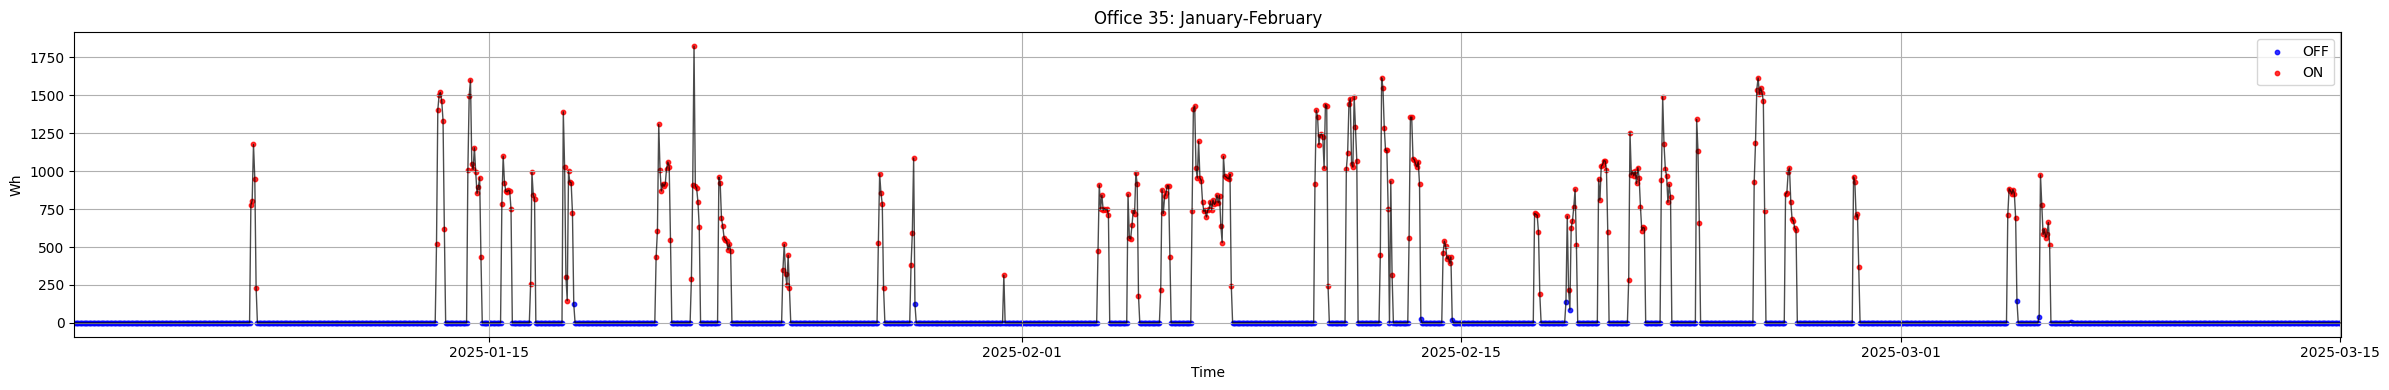

In [ ]:
x = hvac_consumptions_dataframe.index
y = hvac_consumptions_dataframe[f'{rooms[i]}_consumption']

off_flag = (on_off_sequence_aggregation[rooms[i]] == 0)
on_flag = (on_off_sequence_aggregation[rooms[i]] == 1)

plt.figure(figsize=(24,4))
plt.plot(x,y,color='black',linewidth=1,alpha=0.7)
plt.scatter(x[off_flag],y[off_flag],color='blue',s=10,alpha=0.8,label='OFF')
plt.scatter(x[on_flag],y[on_flag],color='red',s=10,alpha=0.8,label='ON')

plt.title(f"Office 35: January-February")
plt.xlabel("Time")
plt.ylabel("Wh")
plt.grid(True)
plt.xlim(pd.to_datetime('2025-01-01 19:00:00'), pd.to_datetime('2025-03-15 01:00:00'))
plt.legend()

plt.tight_layout()
plt.show()

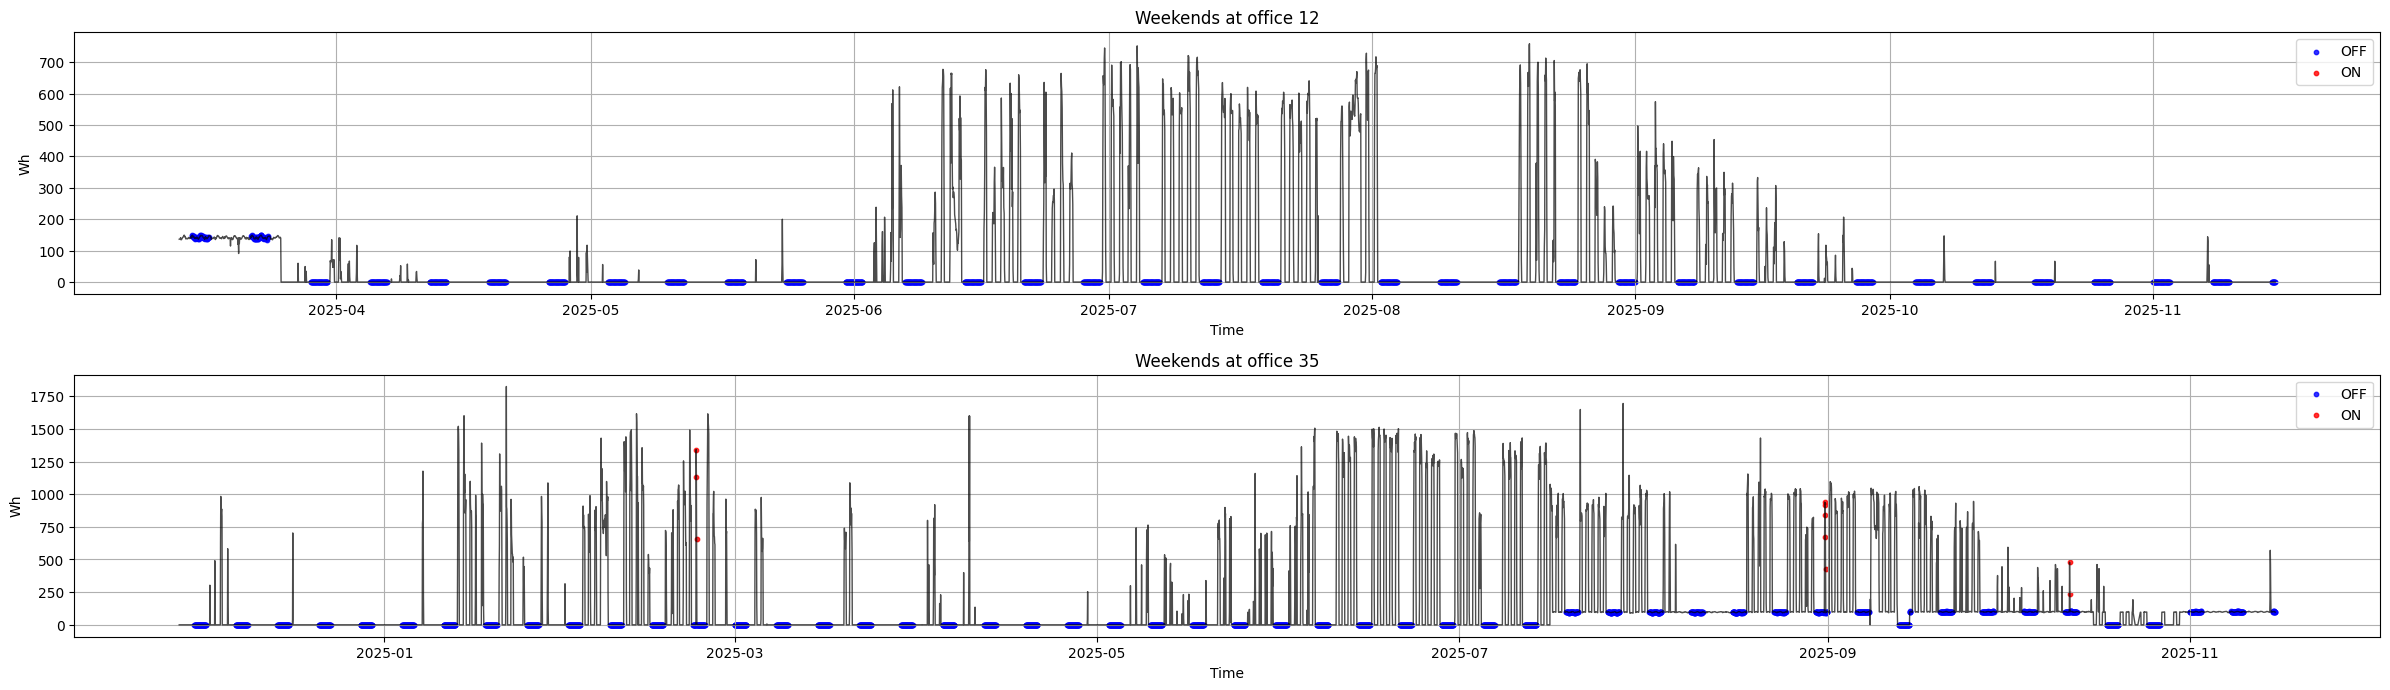

In [ ]:
plt.figure(figsize=(24,10))

for i in range (0,2):
  x = hvac_consumptions_dataframe.index
  y = hvac_consumptions_dataframe[f'{rooms[i]}_consumption']

# Reindex the HMM sequence to align with the full consumption data
  hvac_on_off_aligned = on_off_sequence_aggregation[rooms[i]].reindex(y.index)


# Masks based on the aligned HMM sequence
  off_flag = (hvac_on_off_aligned == 0)
  on_flag = (hvac_on_off_aligned == 1)

  weekend_mask = x.dayofweek >= 5 

  off_flag_weekend = off_flag & weekend_mask
  on_flag_weekend  = on_flag  & weekend_mask

  plt.subplot(3,1,i+1)
  plt.plot(x,y,color='black',linewidth=1,alpha=0.7)

  plt.scatter(x[off_flag_weekend],y[off_flag_weekend],color='blue',s=10,alpha=0.8,label='OFF')
  plt.scatter(x[on_flag_weekend],y[on_flag_weekend],color='red',s=10,alpha=0.8,label='ON')

  plt.title(f"Weekends at office {rooms[i][1]}{rooms[i][2]}")
  plt.xlabel("Time")
  plt.ylabel("Wh")
  plt.grid(True)
  #plt.xlim(pd.to_datetime('2025-07-10 19:00:00'), pd.to_datetime('2025-10-12 01:00:00'))
  plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
methods = {
    'naive': on_off_sequence_naive,
    'hmm': on_off_sequence_hmm,
    'quantiles': on_off_sequence_simple_quantiles,
    'aggregation': on_off_sequence_aggregation,
}

def method_counts_table(room):
    valid_index = hvac_consumptions_dataframe[f'{room}_consumption'].dropna().index
    aggregation_valid = on_off_sequence_aggregation[room].reindex(valid_index)

    rows = []
    for method_name, sequences in methods.items():
        seq_valid = sequences[room].reindex(valid_index)
        counts = seq_valid.value_counts()
        diff_from_aggregation = (seq_valid.astype(int) ^ aggregation_valid.astype(int)).value_counts().get(1, 0)
        rows.append({
            'method': method_name,
            'ones': int(counts.get(1, 0)),
            'zeros': int(counts.get(0, 0)),
            'diff_from_aggregation': int(diff_from_aggregation),
        })
    return pd.DataFrame(rows).set_index('method')

o12_method_counts = method_counts_table('o12')
o35_method_counts = method_counts_table('o35')

print("Office 12")
display(o12_method_counts)
print("Office 35")
display(o35_method_counts)

Office 12


,ones,zeros,diff_from_aggregation
method,,,
naive,529,5397,2
hmm,991,4935,460
quantiles,479,5447,52
aggregation,531,5395,0


Office 35


,ones,zeros,diff_from_aggregation
method,,,
naive,1233,7238,51
hmm,1195,7276,13
quantiles,1042,7429,140
aggregation,1182,7289,0


### Histograms Comparison

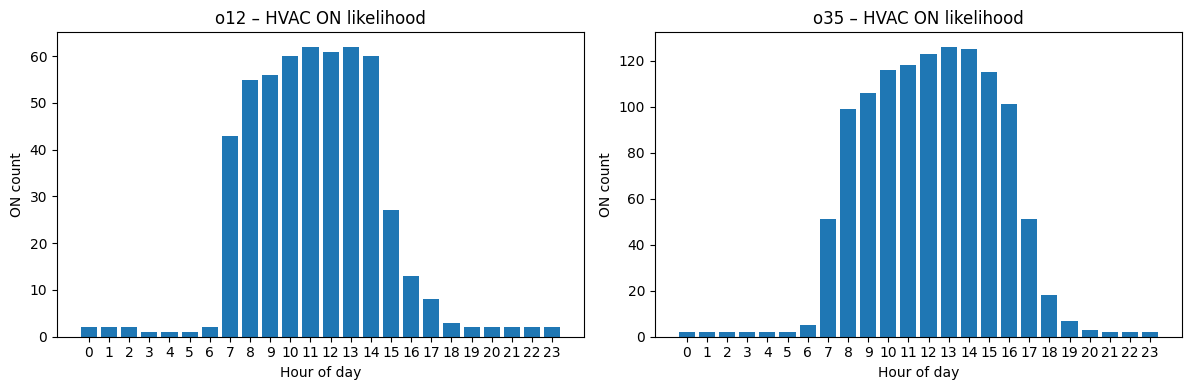

In [ ]:
import matplotlib.pyplot as plt

rooms = ["o12", "o35"]

plt.figure(figsize=(18, 4))

for i, room in enumerate(rooms):
    on_off = on_off_sequence_aggregation[room]

    hourly_on_counts = (
        on_off
        .groupby(on_off.index.hour)
        .sum()
    )

    plt.subplot(1, 3, i + 1)
    plt.bar(hourly_on_counts.index, hourly_on_counts.values)
    plt.xticks(range(24))
    plt.xlabel("Hour of day")
    plt.ylabel("ON count")
    plt.title(f"{room} – HVAC ON likelihood")

plt.tight_layout()
plt.show()


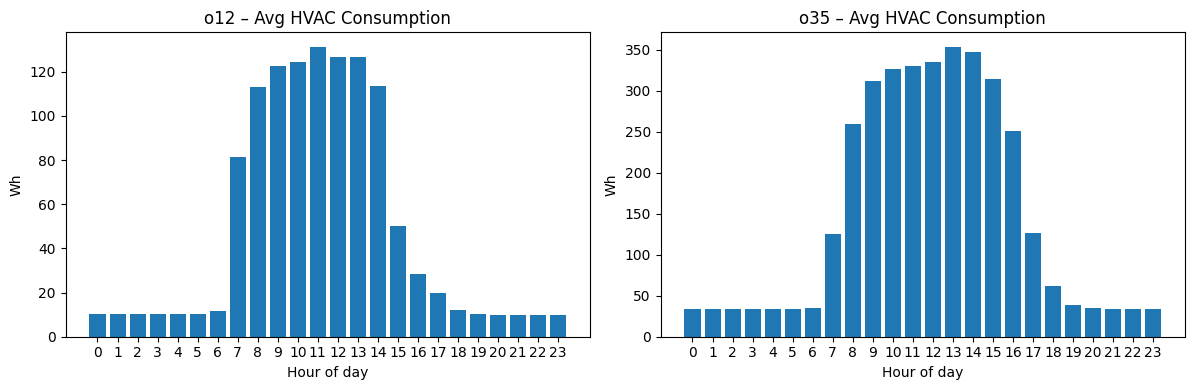

In [ ]:
plt.figure(figsize=(18, 4))

for i, room in enumerate(rooms):
    consumptions = hvac_consumptions_dataframe[f"{room}_consumption"]
    hourly_cons_mean = consumptions.groupby(consumptions.index.hour).mean()

    # Consumption
    plt.subplot(1, 3, i + 1)
    plt.bar(hourly_cons_mean.index, hourly_cons_mean.values)
    plt.xticks(range(24))
    plt.xlabel("Hour of day")
    plt.ylabel("Wh")
    plt.title(f"{room} – Avg HVAC Consumption")

plt.tight_layout()
plt.show()

## Εξωτερικές θερμοκρασίες

In [ ]:
monthly_breakdown_table(on_off_sequence_aggregation, hvac_consumptions_dataframe, rooms, month_range, 'Aggregation')

--- Monthly breakdown: Aggregation ---


Office 12                                          \
        total_points ON_points OFF_points avg_consumption_ON   
2024-11           85         0         85                NaN   
2024-12          744         0        744                NaN   
2025-01          744         0        744                NaN   
2025-02          672         0        672                NaN   
2025-03          744         0        744                NaN   
2025-04          720         1        719             210.66   
2025-05          744         1        743             199.89   
2025-06          720       142        578             382.26   
2025-07          744       222        522             532.04   
2025-08          744        72        672             515.22   
2025-09          720        93        627             291.11   
2025-10          744         0        744                NaN   
2025-11          346         0        346                NaN   

                                      Office 35                       \
        avg_consumption_OFF   %_ON total_points ON_points OFF_points   
2024-11                 NaN   0.00           85         0         85   
2024-12                 NaN   0.00          744        13        731   
2025-01                 NaN   0.00          744        87        657   
2025-02                 NaN   0.00          672       169        503   
2025-03               93.69   0.00          744        34        710   
2025-04                2.56   0.14          720        17        703   
2025-05                0.39   0.13          744        67        677   
2025-06                4.38  19.72          720       201        519   
2025-07                0.93  29.84          744       224        520   
2025-08                2.36   9.68          744       123        621   
2025-09                5.16  12.92          720       205        515   
2025-10                0.60   0.00          744        38        706   
2025-11                1.16   0.00          346         4        342   

                                                       
        avg_consumption_ON avg_consumption_OFF   %_ON  
2024-11                NaN                0.00   0.00  
2024-12             646.82                0.05   1.75  
2025-01             818.45                0.37  11.69  
2025-02             893.17                0.53  25.15  
2025-03             734.11                0.46   4.57  
2025-04             622.71                0.75   2.36  
2025-05             527.94                3.80   9.01  
2025-06            1173.66                0.61  27.92  
2025-07             993.92               48.02  30.11  
2025-08             830.51               97.44  16.53  
2025-09             795.77               90.05  28.47  
2025-10             335.61               64.87   5.11  
2025-11             362.24               99.23   1.16

In [ ]:
import requests
import pandas as pd
import datetime
from datetime import timedelta

min_date = hvac_consumptions_dataframe.index.min().date()
max_date = hvac_consumptions_dataframe.index.max().date()


# --- 1) Ορισμός περιοχής & εύρους ημερομηνιών ---
latitude = 37.98   # Αθήνα (αλλάζεις για άλλη πόλη/χώρα)
longitude = 23.73
start_date = min_date.isoformat()
end_date   =  (max_date + timedelta(days=1)).isoformat()

# --- 2) Κάλεσμα στο Open-Meteo ARCHIVE (ιστορικά) σε UTC ---
url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": latitude,
    "longitude": longitude,
    "start_date": start_date,
    "end_date": end_date,
    "hourly": "temperature_2m",
    "timezone": "UTC",   # για να ταιριάζει 1-1 στο 'hour' σου
}

r = requests.get(url, params=params)
r.raise_for_status()
data = r.json()

df_tout = pd.DataFrame({
    "hour": pd.to_datetime(data["hourly"]["time"], utc=True),
    "T_out": data["hourly"]["temperature_2m"]
}).sort_values("hour")

df_tout['hour'] = pd.to_datetime(df_tout['hour'])
df_tout.set_index('hour', inplace=True)
df_tout

,T_out
hour,
2024-11-27 00:00:00+00:00,8.1
2024-11-27 01:00:00+00:00,10.0
2024-11-27 02:00:00+00:00,9.6
2024-11-27 03:00:00+00:00,9.0
2024-11-27 04:00:00+00:00,8.4
...,...
2025-11-16 19:00:00+00:00,15.0
2025-11-16 20:00:00+00:00,14.8
2025-11-16 21:00:00+00:00,14.7


### Save the on/off sequences

In [ ]:
office12

,day_name,month,temperature,consumption
timestamp,,,,
2025-03-13 12:00:00,Thursday,March,21.4,136.25
2025-03-13 13:00:00,Thursday,March,21.8,136.66
2025-03-13 14:00:00,Thursday,March,22.0,137.70
2025-03-13 15:00:00,Thursday,March,22.1,138.37
2025-03-13 16:00:00,Thursday,March,22.2,141.35
...,...,...,...,...
2025-11-15 05:00:00,Saturday,November,19.9,0.00
2025-11-15 06:00:00,Saturday,November,19.8,0.00
2025-11-15 07:00:00,Saturday,November,19.8,0.00


In [ ]:
office12['t_out'] = df_tout['T_out'].tz_localize(None)
office12.rename(columns={'temperature': 't_in'}, inplace=True)
office12['sequence'] = on_off_sequence_aggregation['o12']

#office12.to_csv("../data/office12_on_off_dataframe.csv")
dumm = office12.copy()
dumm.drop(columns=['day_name', 'month', 'sequence'], inplace=True)
dumm

,t_in,consumption,t_out
timestamp,,,
2025-03-13 12:00:00,21.4,136.25,20.7
2025-03-13 13:00:00,21.8,136.66,20.6
2025-03-13 14:00:00,22.0,137.70,20.0
2025-03-13 15:00:00,22.1,138.37,19.3
2025-03-13 16:00:00,22.2,141.35,18.2
...,...,...,...
2025-11-15 05:00:00,19.9,0.00,11.6
2025-11-15 06:00:00,19.8,0.00,12.1
2025-11-15 07:00:00,19.8,0.00,14.2


In [ ]:
office35['t_out'] = df_tout['T_out'].tz_localize(None)
office35.rename(columns={'temperature': 't_in'}, inplace=True)
office35['sequence'] = on_off_sequence_aggregation['o35']

#office35.to_csv("../data/office35_on_off_dataframe.csv")
dumm = office35.copy()
dumm.drop(columns=['day_name', 'month', 'sequence'], inplace=True)
dumm

,t_in,consumption,t_out
timestamp,,,
2024-11-27 11:00:00,22.7,0.00,17.2
2024-11-27 12:00:00,23.2,0.01,17.7
2024-11-27 13:00:00,23.5,0.00,18.0
2024-11-27 14:00:00,23.7,0.00,17.4
2024-11-27 15:00:00,23.6,0.00,16.2
...,...,...,...
2025-11-15 05:00:00,19.5,101.73,11.6
2025-11-15 06:00:00,19.5,100.63,12.1
2025-11-15 07:00:00,19.7,98.51,14.2


# Distinction betweeen heating and cooling

## Heating degree days / Cooling degree days

In [ ]:
#OUTDOOR TEMPERATURE
df_tout.head(3)

,T_out
hour,
2024-11-27 00:00:00+00:00,8.1
2024-11-27 01:00:00+00:00,10.0
2024-11-27 02:00:00+00:00,9.6


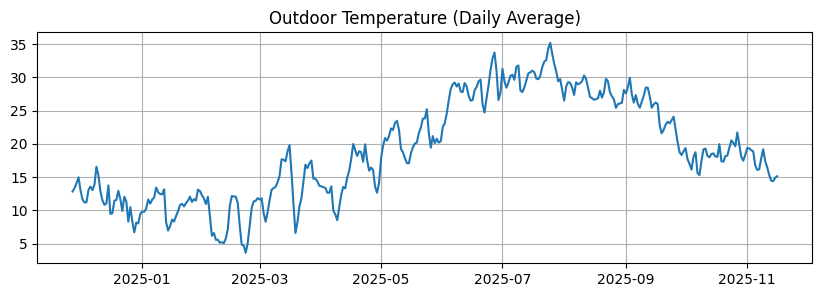

In [ ]:
tout_daily = df_tout.resample('D').mean()
tout_daily.rename(columns={'T_out': 'daily_avg_T_out'}, inplace=True)

plt.figure(figsize=(10,3))
plt.plot(tout_daily.index, tout_daily['daily_avg_T_out'], label='Outdoor Temperature (Daily Average)')
plt.title('Outdoor Temperature (Daily Average)')
plt.grid(True)
plt.show()

In [ ]:
baseline_temp_heating = 18 #if outdoor temperature is under baseline_temp_heating, it means that weather conditions 'favor' heating
baseline_temp_cooling = 21 #if outdoor temperature is over baseline_temp_cooling, it means that weather conditions 'favor' cooling

tout_daily['heating_degree_days'] = baseline_temp_heating - tout_daily['daily_avg_T_out']
tout_daily['cooling_degree_days'] = tout_daily['daily_avg_T_out'] - baseline_temp_cooling

tout_daily['heating_degree_days'] = tout_daily['heating_degree_days'].clip(lower=0)
tout_daily['cooling_degree_days'] = tout_daily['cooling_degree_days'].clip(lower=0)

tout_daily.head(3)

,daily_avg_T_out,heating_degree_days,cooling_degree_days
hour,,,
2024-11-27 00:00:00+00:00,12.829167,5.170833,0.0
2024-11-28 00:00:00+00:00,13.358333,4.641667,0.0
2024-11-29 00:00:00+00:00,14.079167,3.920833,0.0


In [ ]:
start = pd.Timestamp("2025-05-01 00:00:00", tz="UTC")
end = pd.Timestamp("2025-05-29 00:00:00", tz="UTC")

print(tout_daily.loc[start:end - pd.Timedelta(hours=1), 'cooling_degree_days'])

hour
2025-05-01 00:00:00+00:00    0.000000
2025-05-02 00:00:00+00:00    0.000000
2025-05-03 00:00:00+00:00    0.000000
2025-05-04 00:00:00+00:00    0.000000
2025-05-05 00:00:00+00:00    0.175000
2025-05-06 00:00:00+00:00    1.320833
2025-05-07 00:00:00+00:00    1.087500
2025-05-08 00:00:00+00:00    2.170833
2025-05-09 00:00:00+00:00    2.462500
2025-05-10 00:00:00+00:00    1.129167
2025-05-11 00:00:00+00:00    0.000000
2025-05-12 00:00:00+00:00    0.000000
2025-05-13 00:00:00+00:00    0.000000
2025-05-14 00:00:00+00:00    0.000000
2025-05-15 00:00:00+00:00    0.000000
2025-05-16 00:00:00+00:00    0.000000
2025-05-17 00:00:00+00:00    0.000000
2025-05-18 00:00:00+00:00    0.000000
2025-05-19 00:00:00+00:00    0.000000
2025-05-20 00:00:00+00:00    0.666667
2025-05-21 00:00:00+00:00    1.458333
2025-05-22 00:00:00+00:00    2.795833
2025-05-23 00:00:00+00:00    2.837500
2025-05-24 00:00:00+00:00    4.204167
2025-05-25 00:00:00+00:00    0.620833
2025-05-26 00:00:00+00:00    0.000000
2025-05

In [ ]:
start = pd.Timestamp("2025-06-01 00:00:00", tz="UTC")
end = pd.Timestamp("2025-06-10 00:00:00", tz="UTC")

print(tout_daily.loc[start:end - pd.Timedelta(hours=1), 'cooling_degree_days'])

hour
2025-06-01 00:00:00+00:00    1.541667
2025-06-02 00:00:00+00:00    2.104167
2025-06-03 00:00:00+00:00    3.550000
2025-06-04 00:00:00+00:00    5.566667
2025-06-05 00:00:00+00:00    7.233333
2025-06-06 00:00:00+00:00    7.962500
2025-06-07 00:00:00+00:00    8.233333
2025-06-08 00:00:00+00:00    7.641667
2025-06-09 00:00:00+00:00    8.087500
Freq: D, Name: cooling_degree_days, dtype: float64


In [ ]:
start = pd.Timestamp("2025-09-01 00:00:00", tz="UTC")
end = pd.Timestamp("2025-09-27 00:00:00", tz="UTC")

print(tout_daily.loc[start:end - pd.Timedelta(hours=1), 'cooling_degree_days'])

hour
2025-09-01 00:00:00+00:00    6.608333
2025-09-02 00:00:00+00:00    7.470833
2025-09-03 00:00:00+00:00    8.950000
2025-09-04 00:00:00+00:00    6.445833
2025-09-05 00:00:00+00:00    5.216667
2025-09-06 00:00:00+00:00    6.341667
2025-09-07 00:00:00+00:00    5.037500
2025-09-08 00:00:00+00:00    4.445833
2025-09-09 00:00:00+00:00    5.354167
2025-09-10 00:00:00+00:00    6.262500
2025-09-11 00:00:00+00:00    7.479167
2025-09-12 00:00:00+00:00    7.450000
2025-09-13 00:00:00+00:00    6.170833
2025-09-14 00:00:00+00:00    4.433333
2025-09-15 00:00:00+00:00    4.945833
2025-09-16 00:00:00+00:00    5.233333
2025-09-17 00:00:00+00:00    4.975000
2025-09-18 00:00:00+00:00    1.795833
2025-09-19 00:00:00+00:00    0.591667
2025-09-20 00:00:00+00:00    1.112500
2025-09-21 00:00:00+00:00    1.900000
2025-09-22 00:00:00+00:00    2.329167
2025-09-23 00:00:00+00:00    2.083333
2025-09-24 00:00:00+00:00    2.575000
2025-09-25 00:00:00+00:00    3.100000
2025-09-26 00:00:00+00:00    1.191667
Freq: D

In [ ]:
monthly_hdd_cdd = tout_daily.groupby(tout_daily.index.month)[['heating_degree_days', 'cooling_degree_days']].mean()
monthly_hdd_cdd

,heating_degree_days,cooling_degree_days
hour,,
1,7.077823,0.000000
2,9.691071,0.000000
3,4.320833,0.000000
4,3.424861,0.000000
5,0.070027,0.680511
6,0.000000,6.995417
7,0.000000,9.612500
8,0.000000,6.882661
9,0.000000,3.983333


Text(0.5, 0, 'Date')

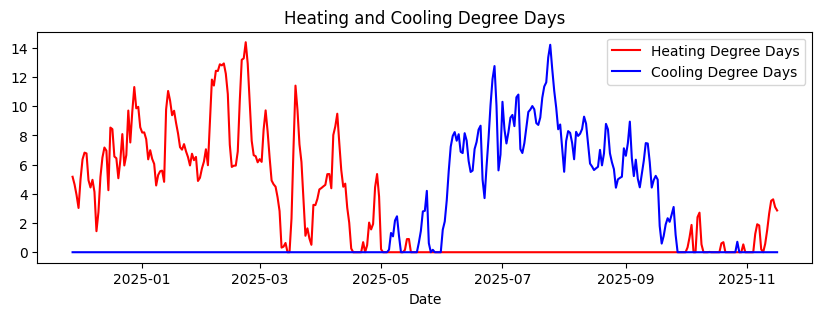

In [ ]:
plt.figure(figsize=(10, 3))
plt.plot(tout_daily.index, tout_daily['heating_degree_days'], label='Heating Degree Days', color = 'red')
plt.plot(tout_daily.index, tout_daily['cooling_degree_days'], label='Cooling Degree Days', color = 'blue')

plt.legend()
plt.title('Heating and Cooling Degree Days')
plt.xlabel('Date')

### Weekly averages (workdays only)

In [ ]:
# One row per week (Monday-Friday), average CDD / HDD over the weekdays

def weekly_degree_day_table(daily_df, col, start, end):
    mask = (daily_df.index.weekday < 5) & (daily_df.index >= start) & (daily_df.index <= end)
    sub = daily_df.loc[mask, [col]].copy()
    iso = sub.index.isocalendar()
    sub['iso_year'] = iso['year'].values
    sub['iso_week'] = iso['week'].values

    rows = []
    for (iso_year, iso_week), grp in sub.groupby(['iso_year', 'iso_week']):
        monday = pd.Timestamp.fromisocalendar(int(iso_year), int(iso_week), 1)
        friday = pd.Timestamp.fromisocalendar(int(iso_year), int(iso_week), 5)
        rows.append({
            'Week Start (Mon)': monday.date(),
            'Week End (Fri)':   friday.date(),
            f'Avg {col}':       round(float(grp[col].mean()), 2),
            'Weekdays in range': len(grp),
        })
    return pd.DataFrame(rows).sort_values('Week Start (Mon)').reset_index(drop=True)


CDD_START = pd.Timestamp("2025-05-01", tz="UTC")
CDD_END   = pd.Timestamp("2025-09-30", tz="UTC")
HDD_START = pd.Timestamp("2024-12-01", tz="UTC")
HDD_END   = pd.Timestamp("2025-03-31", tz="UTC")

weekly_cdd_table = weekly_degree_day_table(tout_daily, 'cooling_degree_days', CDD_START, CDD_END)
weekly_hdd_table = weekly_degree_day_table(tout_daily, 'heating_degree_days', HDD_START, HDD_END)

print(f"=== Weekly average CDD, May-September 2025 ({len(weekly_cdd_table)} weeks) ===")
display(weekly_cdd_table)

print(f"\n=== Weekly average HDD, January-March 2025 ({len(weekly_hdd_table)} weeks) ===")
display(weekly_hdd_table)


=== Weekly average CDD, May-September 2025 (23 weeks) ===


,Week Start (Mon),Week End (Fri),Avg cooling_degree_days,Weekdays in range
0,2025-04-28,2025-05-02,0.00,2
1,2025-05-05,2025-05-09,1.44,5
2,2025-05-12,2025-05-16,0.00,5
3,2025-05-19,2025-05-23,1.55,5
4,2025-05-26,2025-05-30,0.03,5
5,2025-06-02,2025-06-06,5.28,5
6,2025-06-09,2025-06-13,7.52,5
7,2025-06-16,2025-06-20,7.46,5
8,2025-06-23,2025-06-27,9.67,5
9,2025-06-30,2025-07-04,8.22,5



=== Weekly average HDD, January-March 2025 (18 weeks) ===


,Week Start (Mon),Week End (Fri),Avg heating_degree_days,Weekdays in range
0,2024-12-02,2024-12-06,5.87,5
1,2024-12-09,2024-12-13,4.60,5
2,2024-12-16,2024-12-20,7.01,5
3,2024-12-23,2024-12-27,7.89,5
4,2024-12-30,2025-01-03,8.54,5
5,2025-01-06,2025-01-10,5.57,5
6,2025-01-13,2025-01-17,10.06,5
7,2025-01-20,2025-01-24,7.01,5
8,2025-01-27,2025-01-31,5.71,5
9,2025-02-03,2025-02-07,10.12,5


## Office 12

In [ ]:
copy = office12.copy()
copy.drop(columns=['day_name', 'month'], inplace=True)
copy.rename(columns={'sequence': 'on/off sequence'}, inplace=True)
#print(copy['sequence'].value_counts())
copy

,t_in,consumption,t_out,on/off sequence
timestamp,,,,
2025-03-13 12:00:00,21.4,136.25,20.7,0
2025-03-13 13:00:00,21.8,136.66,20.6,0
2025-03-13 14:00:00,22.0,137.70,20.0,0
2025-03-13 15:00:00,22.1,138.37,19.3,0
2025-03-13 16:00:00,22.2,141.35,18.2,0
...,...,...,...,...
2025-11-15 05:00:00,19.9,0.00,11.6,0
2025-11-15 06:00:00,19.8,0.00,12.1,0
2025-11-15 07:00:00,19.8,0.00,14.2,0


In [ ]:
# 1. Strip the timezone from tout_daily to match office12's naive timestamps
tout_daily_naive = tout_daily.tz_localize(None)

# 2. Map the daily degree day data to the hourly office12 dataframe
office12['hdd'] = tout_daily_naive['heating_degree_days'].reindex(office12.index, method='ffill')
office12['cdd'] = tout_daily_naive['cooling_degree_days'].reindex(office12.index, method='ffill')

# 3. Initialize
office12['heating_mode'] = 0
office12['cooling_mode'] = 0

# 4. Apply the logic
# Sequence is 1 AND heating > cooling
office12.loc[
    (office12['sequence'] == 1) & (office12['hdd'] > office12['cdd']),
    'heating_mode'
] = 1

# Sequence is 1 AND cooling > heating
office12.loc[
    (office12['sequence'] == 1) & (office12['cdd'] > office12['hdd']),
    'cooling_mode'
] = 1

# 5. Clean up helper columns
office12.drop(columns=['hdd', 'cdd'], inplace=True)

print(office12.head())

                     day_name  month  t_in  consumption  t_out  sequence  \
timestamp                                                                  
2025-03-13 12:00:00  Thursday  March  21.4       136.25   20.7         0   
2025-03-13 13:00:00  Thursday  March  21.8       136.66   20.6         0   
2025-03-13 14:00:00  Thursday  March  22.0       137.70   20.0         0   
2025-03-13 15:00:00  Thursday  March  22.1       138.37   19.3         0   
2025-03-13 16:00:00  Thursday  March  22.2       141.35   18.2         0   

                     heating_mode  cooling_mode  
timestamp                                        
2025-03-13 12:00:00             0             0  
2025-03-13 13:00:00             0             0  
2025-03-13 14:00:00             0             0  
2025-03-13 15:00:00             0             0  
2025-03-13 16:00:00             0             0  


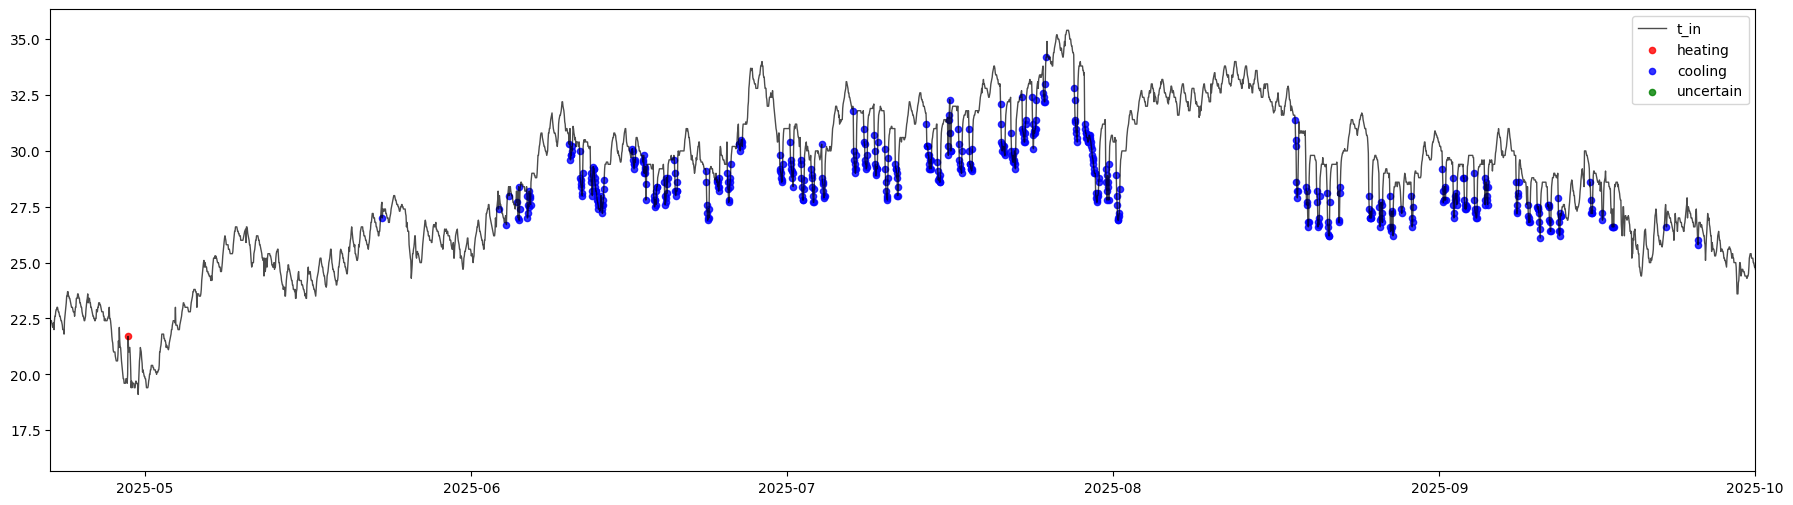

In [ ]:
# 6. Plot
x = office12.index
y = office12['t_in']

heating_flag = (office12['heating_mode'] == 1)
cooling_flag = (office12['cooling_mode'] == 1)
uncertain_flag = (office12['heating_mode'] == 0) & (office12['cooling_mode'] == 0) & (office12['sequence'] == 1)

plt.figure(figsize=(22, 6))
#plt.plot(x, office12['t_out'], color='orange', linewidth=1, label='t_out', alpha=0.5)
plt.plot(x, y, color='black', linewidth=1, alpha=0.7, label='t_in')

plt.scatter(x[heating_flag], y[heating_flag], color='red', s=20,alpha=0.8,label='heating')
plt.scatter(x[cooling_flag], y[cooling_flag], color='blue', s=20,alpha=0.8,label='cooling')
plt.scatter(x[uncertain_flag], y[uncertain_flag], color='green', s=20,alpha=0.8,label='uncertain')

#plt.axhline(y=18, color='purple', linestyle='--', label='Baseline 18°C')
#plt.axhline(y=24, color='brown', linestyle='--', label='Baseline 24°C')


# Set limits
start_date = pd.to_datetime('2025-04-22 00:00:00')
end_date = pd.to_datetime('2025-10-01 01:00:00')
plt.xlim(start_date, end_date)

plt.legend()
plt.show()

In [ ]:
print(f"Out of the {office12['sequence'].sum()} points {office12['heating_mode'].sum()} are heating, {office12['cooling_mode'].sum()} are cooling and {uncertain_flag.sum()} are uncertain")

Out of the 531 points 1 are heating, 530 are cooling and 0 are uncertain


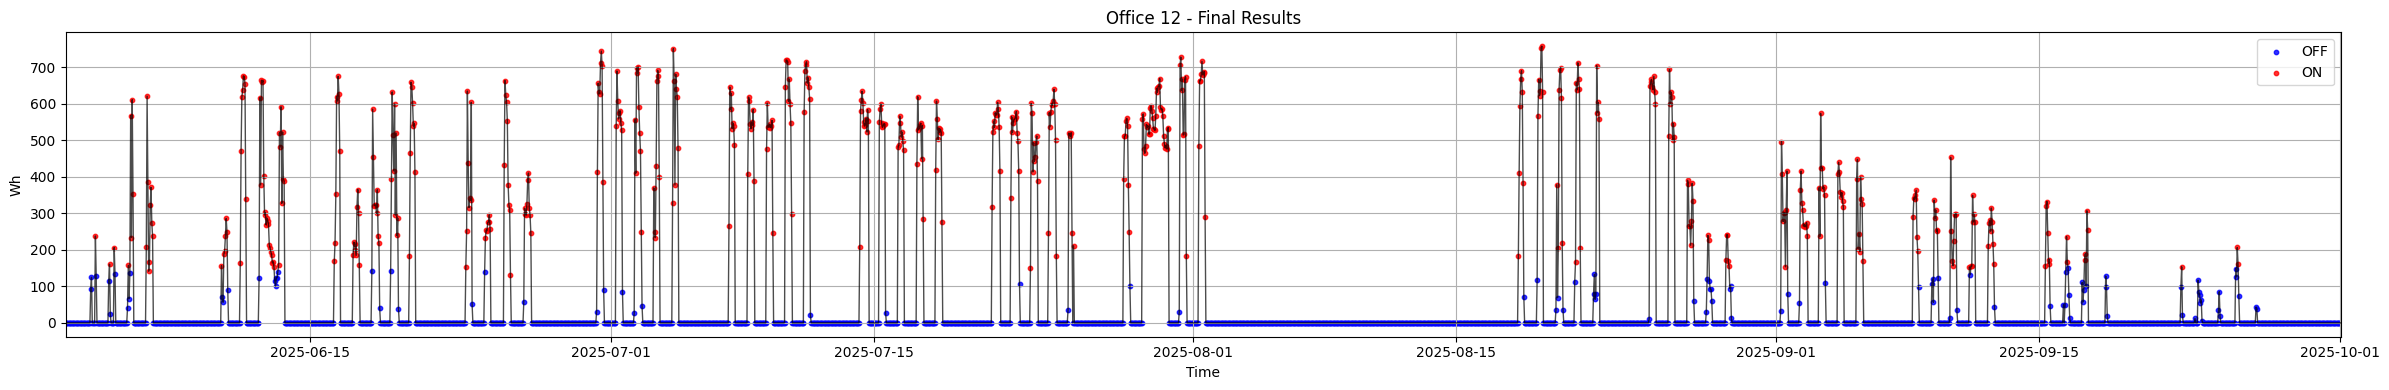

In [ ]:
plt.figure(figsize=(24,4))

x = hvac_consumptions_dataframe.index
y = hvac_consumptions_dataframe['o12_consumption']

off_flag = (on_off_sequence_aggregation['o12'] == 0)
on_flag = (on_off_sequence_aggregation['o12'] == 1)

plt.plot(x,y,color='black',linewidth=1,alpha=0.7)

plt.scatter(x[off_flag],y[off_flag],color='blue',s=10,alpha=0.8,label='OFF')
plt.scatter(x[on_flag],y[on_flag],color='red',s=10,alpha=0.8,label='ON')

plt.title(f"Office 12 - Final Results")
plt.xlabel("Time")
plt.ylabel("Wh")
plt.grid(True)
plt.legend()

# Set limits
start_date = pd.to_datetime('2025-06-02 00:00:00')
end_date = pd.to_datetime('2025-10-01 01:00:00')
plt.xlim(start_date, end_date)


plt.tight_layout()
plt.show()


In [ ]:
error_mask = (office12['sequence'] == 1) & (office12['heating_mode'] == 0) & (office12['cooling_mode'] == 0)
error_mask.sum()

np.int64(0)

In [ ]:
#office12.to_excel("../data/office12_fullop_dataframe.xlsx")
office12


,day_name,month,t_in,consumption,t_out,sequence,heating_mode,cooling_mode
timestamp,,,,,,,,
2025-03-13 12:00:00,Thursday,March,21.4,136.25,20.7,0,0,0
2025-03-13 13:00:00,Thursday,March,21.8,136.66,20.6,0,0,0
2025-03-13 14:00:00,Thursday,March,22.0,137.70,20.0,0,0,0
2025-03-13 15:00:00,Thursday,March,22.1,138.37,19.3,0,0,0
2025-03-13 16:00:00,Thursday,March,22.2,141.35,18.2,0,0,0
...,...,...,...,...,...,...,...,...
2025-11-15 05:00:00,Saturday,November,19.9,0.00,11.6,0,0,0
2025-11-15 06:00:00,Saturday,November,19.8,0.00,12.1,0,0,0
2025-11-15 07:00:00,Saturday,November,19.8,0.00,14.2,0,0,0


## Office 35

In [ ]:
print(office35['sequence'].value_counts())
office35

sequence
0    7289
1    1182
Name: count, dtype: int64


,day_name,month,t_in,consumption,t_out,sequence
timestamp,,,,,,
2024-11-27 11:00:00,Wednesday,November,22.7,0.00,17.2,0
2024-11-27 12:00:00,Wednesday,November,23.2,0.01,17.7,0
2024-11-27 13:00:00,Wednesday,November,23.5,0.00,18.0,0
2024-11-27 14:00:00,Wednesday,November,23.7,0.00,17.4,0
2024-11-27 15:00:00,Wednesday,November,23.6,0.00,16.2,0
...,...,...,...,...,...,...
2025-11-15 05:00:00,Saturday,November,19.5,101.73,11.6,0
2025-11-15 06:00:00,Saturday,November,19.5,100.63,12.1,0
2025-11-15 07:00:00,Saturday,November,19.7,98.51,14.2,0


In [ ]:
import numpy as np

# 1. Strip the timezone from tout_daily to match office35's naive timestamps
tout_daily_naive = tout_daily.tz_localize(None)

# 2. Map the daily degree day data to the hourly office35 dataframe
office35['hdd'] = tout_daily_naive['heating_degree_days'].reindex(office35.index, method='ffill')
office35['cdd'] = tout_daily_naive['cooling_degree_days'].reindex(office35.index, method='ffill')

# 3. Initialize
office35['heating_mode'] = 0
office35['cooling_mode'] = 0

# 4. Apply the logic
# Sequence is 1 AND heating > cooling
office35.loc[
    (office35['sequence'] == 1) & (office35['hdd'] > office35['cdd']),
    'heating_mode'
] = 1

# Sequence is 1 AND cooling > heating
office35.loc[
    (office35['sequence'] == 1) & (office35['cdd'] > office35['hdd']),
    'cooling_mode'
] = 1

# 5. Clean up helper columns
office35.drop(columns=['hdd', 'cdd'], inplace=True)

print(office35.head())

                      day_name     month  t_in  consumption  t_out  sequence  \
timestamp                                                                      
2024-11-27 11:00:00  Wednesday  November  22.7         0.00   17.2         0   
2024-11-27 12:00:00  Wednesday  November  23.2         0.01   17.7         0   
2024-11-27 13:00:00  Wednesday  November  23.5         0.00   18.0         0   
2024-11-27 14:00:00  Wednesday  November  23.7         0.00   17.4         0   
2024-11-27 15:00:00  Wednesday  November  23.6         0.00   16.2         0   

                     heating_mode  cooling_mode  
timestamp                                        
2024-11-27 11:00:00             0             0  
2024-11-27 12:00:00             0             0  
2024-11-27 13:00:00             0             0  
2024-11-27 14:00:00             0             0  
2024-11-27 15:00:00             0             0  


### Plots - Before handling uncertain points

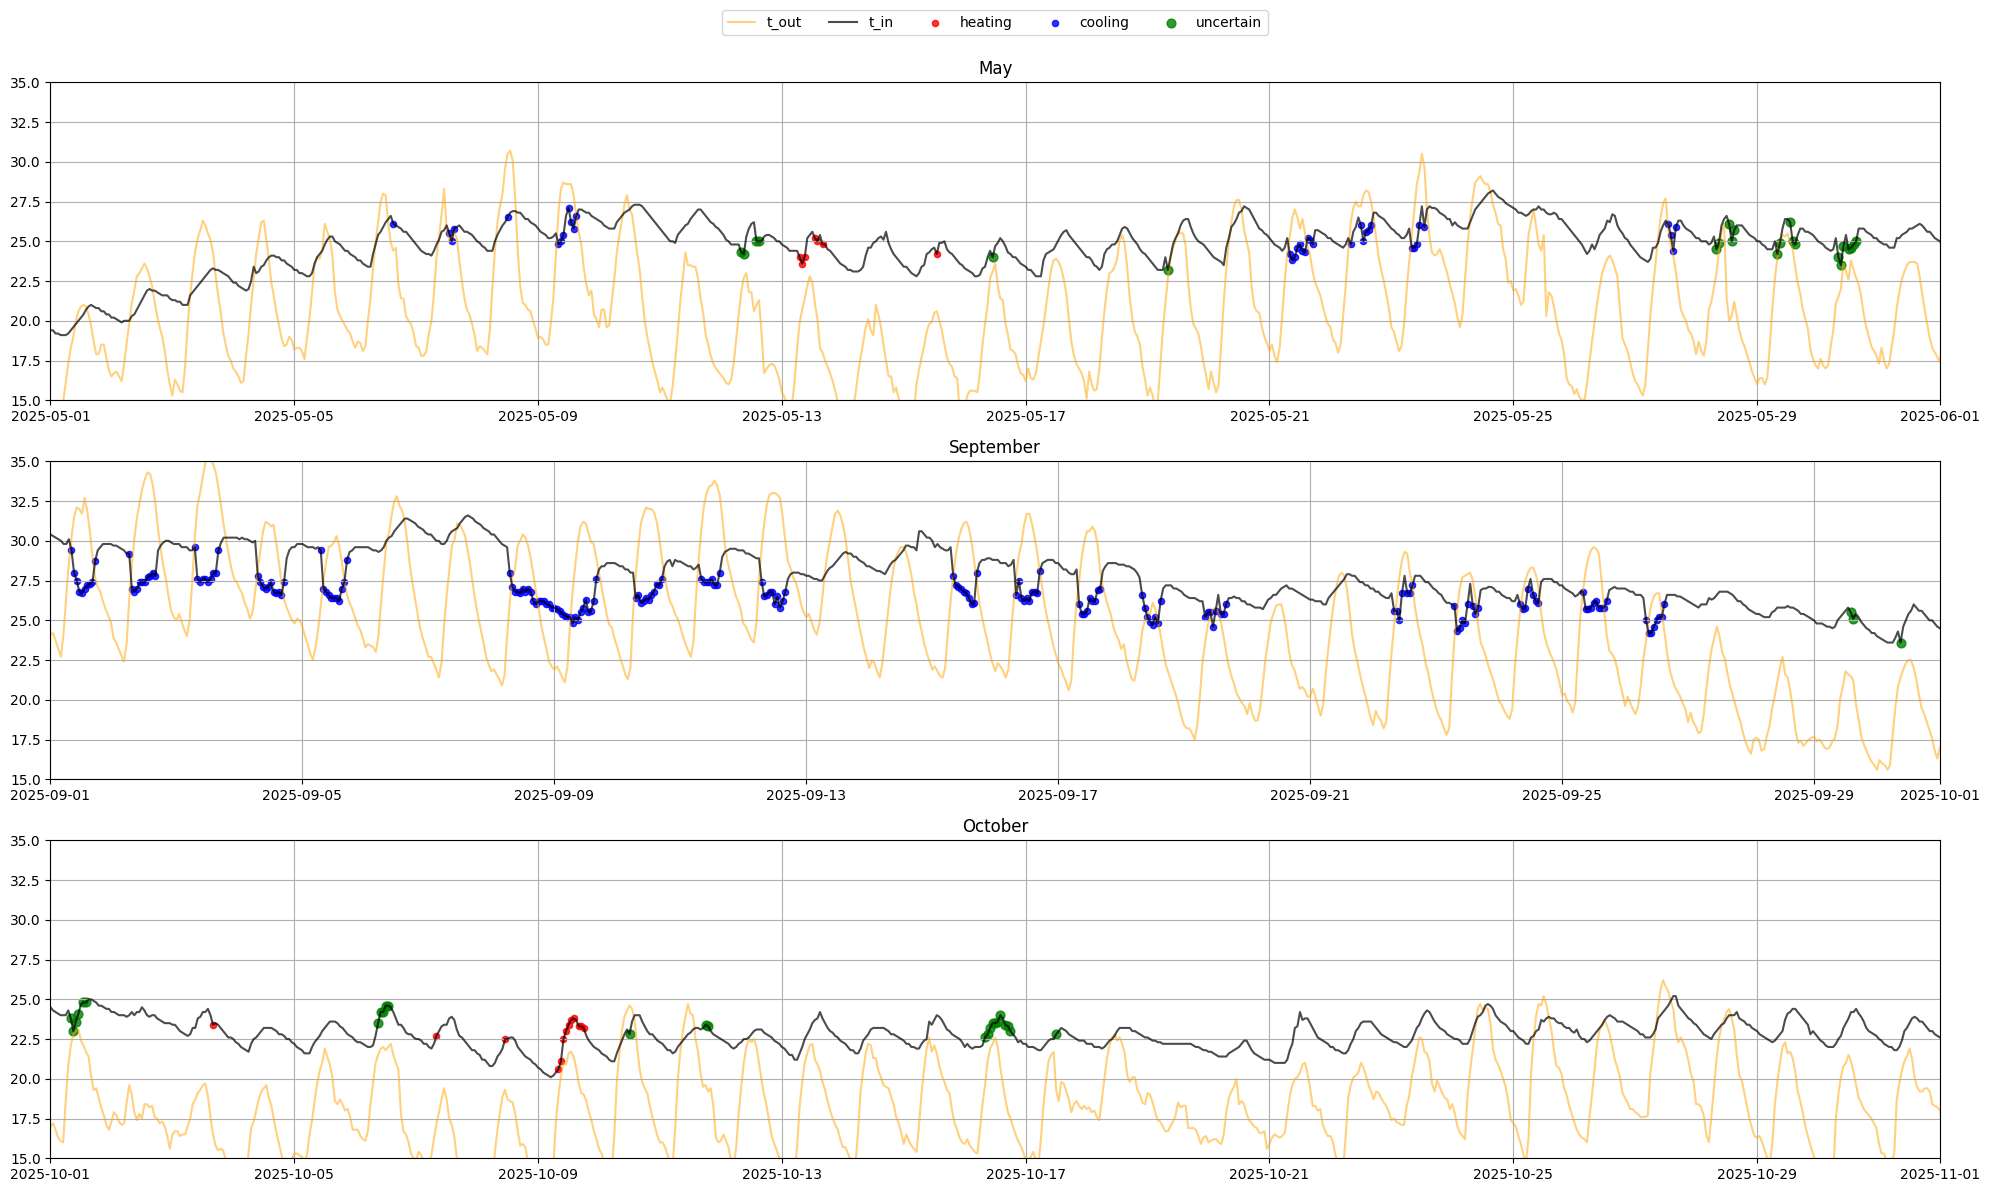

In [ ]:
# Plot -- heating/cooling/uncertain scatter, before handling uncertain points
x = office35.index
y = office35['t_in']

heating_flag = (office35['heating_mode'] == 1)
cooling_flag = (office35['cooling_mode'] == 1)
uncertain_flag = (office35['heating_mode'] == 0) & (office35['cooling_mode'] == 0) & (office35['sequence'] == 1)

months = [(5, 'May'), (9, 'September'), (10, 'October')]

fig, axes = plt.subplots(3, 1, figsize=(20, 12))

for ax, (month, month_name) in zip(axes, months):
    start_date = pd.Timestamp(2025, month, 1)
    end_date = start_date + pd.DateOffset(months=1)

    ax.plot(x, office35['t_out'], color='orange', linewidth=1.5, alpha=0.5, label='t_out')
    ax.plot(x, y, color='black', linewidth=1.5, alpha=0.7, label='t_in')
    ax.scatter(x[heating_flag], y[heating_flag], color='red', s=20, alpha=0.8, label='heating')
    ax.scatter(x[cooling_flag], y[cooling_flag], color='blue', s=20, alpha=0.8, label='cooling')
    ax.scatter(x[uncertain_flag], y[uncertain_flag], color='green', s=40, alpha=0.8, label='uncertain')

    ax.set_xlim(start_date, end_date)
    ax.set_ylim(15, 35)
    ax.set_title(month_name)
    ax.grid(True)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.995),
    ncol=5,
    frameon=True
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
heating_before = int(heating_flag.sum())
cooling_before = int(cooling_flag.sum())
uncertain_before = int(uncertain_flag.sum())

### Handling uncertain points

In [ ]:
# 1. Create the filtered subset first
uncertain_mask = (office35['sequence'] == 1) & (office35['heating_mode'] == 0) & (office35['cooling_mode'] == 0)
uncertain_points = office35[uncertain_mask]

# 2. Group by the index of the subset, not the original dataframe
for date, daily_subset in uncertain_points.groupby(uncertain_points.index.date):

    idx = daily_subset.index
    heating_score = 0
    cooling_score = 0

    day = pd.Timestamp(date)
    start = day - pd.Timedelta(days=2)
    end = day + pd.Timedelta(days=2)
    context = office35.loc[start:end]
    outdoor = tout_daily_naive.loc[start:end]

    # 1. HDD / CDD context (vote)
    hdd_mean = outdoor['heating_degree_days'].mean()
    cdd_mean = outdoor['cooling_degree_days'].mean()
    if hdd_mean > cdd_mean:
        heating_score += 1.1
    elif cdd_mean > hdd_mean:
        cooling_score += 1.1
        # tie = no vote

    # 2. Indoor vs Outdoor (vote)
    avg_tin = daily_subset['t_in'].mean()
    avg_tout = daily_subset['t_out'].mean()
    if avg_tin > avg_tout:
        heating_score += 1
    elif avg_tin < avg_tout:
        cooling_score += 1

    # 3. Month
    month = day.month
    if month in [5, 6, 7, 8, 9]:
      cooling_score += 1
    else:
      heating_score += 1


    if heating_score > cooling_score:
        office35.loc[idx, 'heating_mode'] = 1
    elif cooling_score >= heating_score:
        office35.loc[idx, 'cooling_mode'] = 1


### Plots - After handling uncertain points

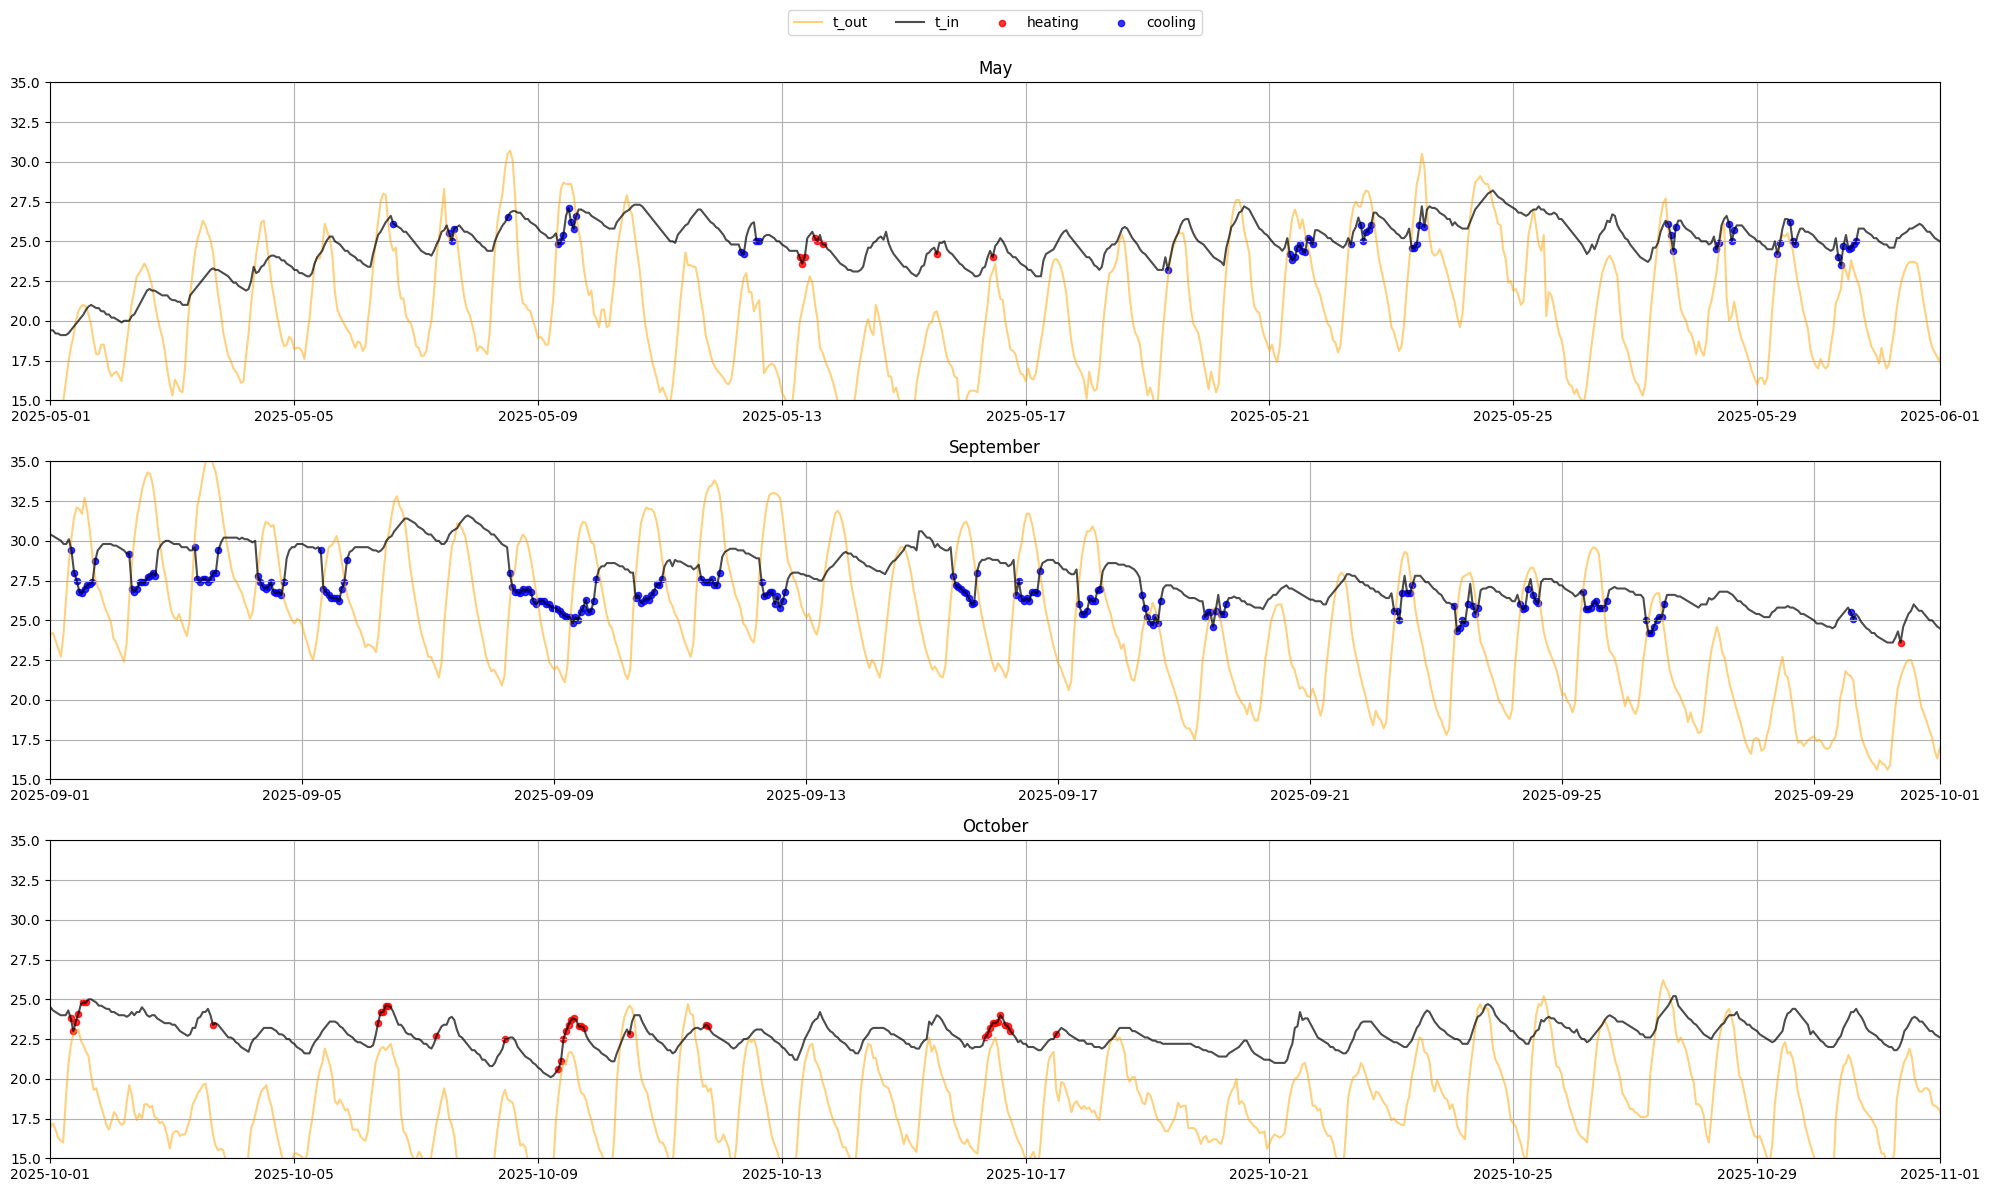

In [ ]:
# Plot -- heating/cooling/uncertain scatter, after handling uncertain points
x = office35.index
y = office35['t_in']

heating_flag = (office35['heating_mode'] == 1)
cooling_flag = (office35['cooling_mode'] == 1)
uncertain_flag = (office35['heating_mode'] == 0) & (office35['cooling_mode'] == 0) & (office35['sequence'] == 1)

fig, axes = plt.subplots(3, 1, figsize=(20, 12))

for ax, (month, month_name) in zip(axes, months):
    start_date = pd.Timestamp(2025, month, 1)
    end_date = start_date + pd.DateOffset(months=1)

    ax.plot(x, office35['t_out'], color='orange', linewidth=1.5, alpha=0.5, label='t_out')
    ax.plot(x, y, color='black', linewidth=1.5, alpha=0.7, label='t_in')
    ax.scatter(x[heating_flag], y[heating_flag], color='red', s=20, alpha=0.8, label='heating')
    ax.scatter(x[cooling_flag], y[cooling_flag], color='blue', s=20, alpha=0.8, label='cooling')

    ax.set_xlim(start_date, end_date)
    ax.set_ylim(15, 35)
    ax.set_title(month_name)
    ax.grid(True)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.995),
    ncol=5,
    frameon=True
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
heating_after = int(heating_flag.sum())
cooling_after = int(cooling_flag.sum())
uncertain_after = int(uncertain_flag.sum())

heating_cooling_uncertain_summary = pd.DataFrame({
    'heating': [heating_before, heating_after],
    'cooling': [cooling_before, cooling_after],
    'uncertain': [uncertain_before, uncertain_after],
}, index=['before', 'after'])

heating_cooling_uncertain_summary

,heating,cooling,uncertain
before,344,787,51
after,371,811,0


In [ ]:
#office35.to_excel("../data/office35_fullop_dataframe.xlsx")
office35


,day_name,month,t_in,consumption,t_out,sequence,heating_mode,cooling_mode
timestamp,,,,,,,,
2024-11-27 11:00:00,Wednesday,November,22.7,0.00,17.2,0,0,0
2024-11-27 12:00:00,Wednesday,November,23.2,0.01,17.7,0,0,0
2024-11-27 13:00:00,Wednesday,November,23.5,0.00,18.0,0,0,0
2024-11-27 14:00:00,Wednesday,November,23.7,0.00,17.4,0,0,0
2024-11-27 15:00:00,Wednesday,November,23.6,0.00,16.2,0,0,0
...,...,...,...,...,...,...,...,...
2025-11-15 05:00:00,Saturday,November,19.5,101.73,11.6,0,0,0
2025-11-15 06:00:00,Saturday,November,19.5,100.63,12.1,0,0,0
2025-11-15 07:00:00,Saturday,November,19.7,98.51,14.2,0,0,0


# Final Results

In [ ]:
rooms_data = {'office12': office12, 'office35': office35}

rows = []
for room_name, df_room in rooms_data.items():
    heating = int(df_room['heating_mode'].sum())
    cooling = int(df_room['cooling_mode'].sum())
    off = int((df_room['sequence'] == 0).sum())
    rows.append({
        'room': room_name,
        'heating': heating,
        'cooling': cooling,
        'total': heating + cooling,
        'off': off,
    })

heating_cooling_summary = pd.DataFrame(rows).set_index('room')
heating_cooling_summary

,heating,cooling,total,off
room,,,,
office12,1,530,531,5395
office35,371,811,1182,7289


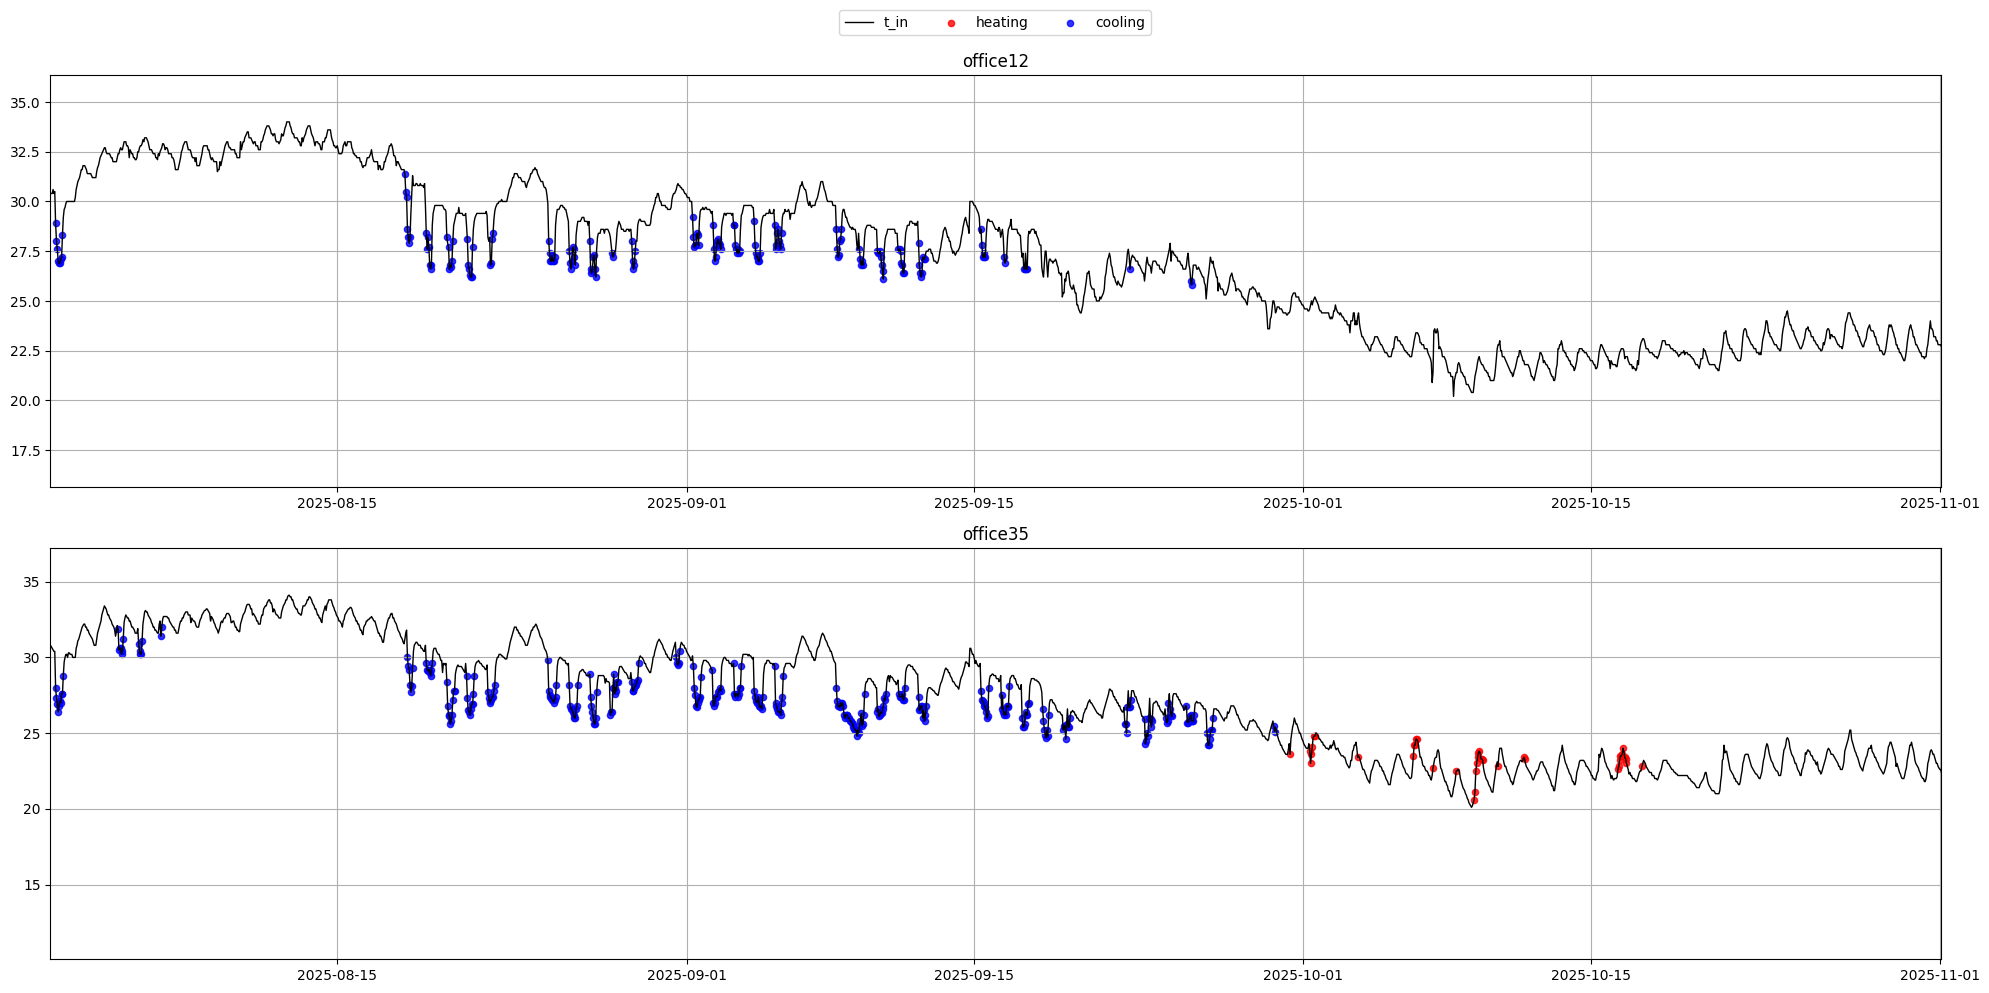

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(20, 10))

offices = [('office12', office12), ('office35', office35)]
start_dates = [pd.Timestamp(2025, 3, 22), pd.Timestamp(2024, 12, 1)]

for ax, (name, df), start_date in zip(axes, offices, start_dates):
    x = df.index
    y = df['t_in']

    heating_flag = (df['heating_mode'] == 1)
    cooling_flag = (df['cooling_mode'] == 1)
    uncertain_flag = (df['heating_mode'] == 0) & (df['cooling_mode'] == 0) & (df['sequence'] == 1)

    #ax.plot(x, df['t_out'], color='orange', linewidth=1.5, alpha=0.5, label='t_out')
    ax.plot(x, y, color='black', linewidth=1, alpha=1, label='t_in')
    ax.scatter(x[heating_flag], y[heating_flag], color='red', s=20, alpha=0.8, label='heating')
    ax.scatter(x[cooling_flag], y[cooling_flag], color='blue', s=20, alpha=0.8, label='cooling')

    ax.set_xlim(start_date, pd.to_datetime('2025-11-01 01:00:00'))
    ax.set_xlim(pd.to_datetime('2025-08-01 01:00:00'), pd.to_datetime('2025-11-01 01:00:00'))
    ax.set_title(name)
    ax.grid(True)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.995),
    ncol=5,
    frameon=True
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [ ]:
# Monthly heating / cooling breakdown per office
_CNT = ['Συνολικά σημεία (data points)', 'Σημεία θέρμανσης', 'Σημεία ψύξης']

def monthly_heating_cooling_table(df_room):
    g = df_room.groupby(df_room.index.to_period('M'))
    t = pd.DataFrame({
        _CNT[0]: g.size(),
        _CNT[1]: g['heating_mode'].sum(),
        _CNT[2]: g['cooling_mode'].sum(),
    })
    t.index = t.index.astype(str)
    t.loc['Σύνολο'] = t.sum()
    t[_CNT] = t[_CNT].astype(int)
    t['Ποσοστό θέρμανσης (%)'] = (t[_CNT[1]] / t[_CNT[0]] * 100).round(2)
    t['Ποσοστό ψύξης (%)']     = (t[_CNT[2]] / t[_CNT[0]] * 100).round(2)
    return t

for _room_name, _df_room in {'Γραφείο 12': office12, 'Γραφείο 35': office35}.items():
    print(f"=== {_room_name} ===")
    display(monthly_heating_cooling_table(_df_room))
    print()

=== Γραφείο 12 ===


,Συνολικά σημεία (data points),Σημεία θέρμανσης,Σημεία ψύξης,Ποσοστό θέρμανσης (%),Ποσοστό ψύξης (%)
timestamp,,,,,
2025-03,444,0,0,0.00,0.00
2025-04,720,1,0,0.14,0.00
2025-05,744,0,1,0.00,0.13
2025-06,720,0,142,0.00,19.72
2025-07,744,0,222,0.00,29.84
2025-08,744,0,72,0.00,9.68
2025-09,720,0,93,0.00,12.92
2025-10,744,0,0,0.00,0.00
2025-11,346,0,0,0.00,0.00



=== Γραφείο 35 ===


,Συνολικά σημεία (data points),Σημεία θέρμανσης,Σημεία ψύξης,Ποσοστό θέρμανσης (%),Ποσοστό ψύξης (%)
timestamp,,,,,
2024-11,85,0,0,0.00,0.00
2024-12,744,13,0,1.75,0.00
2025-01,744,87,0,11.69,0.00
2025-02,672,169,0,25.15,0.00
2025-03,744,34,0,4.57,0.00
2025-04,720,17,0,2.36,0.00
2025-05,744,8,59,1.08,7.93
2025-06,720,0,201,0.00,27.92
2025-07,744,0,224,0.00,30.11
